# Workshop 4 – Stats for AI (Bloque 2)
## Estacionariedad, cointegración y modelos ARIMA/SARIMA

- **Alumno:** Manuel Bajos Rivera 
- **Matrícula:** A01711581


| Parte | Tema | Challenge |
|---|---|---|
| A | Estacionariedad, ADF y KPSS | Challenge 1 |
| B | Regresión espuria y cointegración | Challenge 2 |
| C | Bloques de ARIMA: AR, MA, ACF y PACF | Challenge 3 (con la Parte D) |
| D | Construir y evaluar un modelo SARIMA | Challenge 3.1, 3.2 y 3.3 |

# Estacionalidad vs Series no Estacionarías
Distinción entre series Estacionarias y series No estacionarias

En resumen:
Una serie Estacionaria:
- Tiene un promedio estable a través del tiempo; en otras palabras, la series casi siempre tiende a su promedio histórico.
- La volatilidad de la serie a través del tiempo es estable: la varianza es "homogénea"; quiere decir que en cualquier ventana de tiempo, si calculo la desv estándar, va a ser parecida entre estas ventanas

Ejemplos de series estacionarias:
- El número de latidos del corazón por minuto en reposo:
Promedio 70 y desv estándar 20
- Retornos de una acción: es estacionaria porque tiene un promedio cercano a zero, pero NO es tan homogenea en volatilidad

Una serie NO estacionaria:
- Su promedio NO es estable; cambia significativamente dependiendo de la ventana de tiempo.
- Su desviación estándar NO es homogenea

Tipos de series NO estacionarias:

1) Series crecientes a largo plazo. Ejemplos:
  a) Precios de las casas.
  b) Precios de acciones de empresas.

2) Series decrecientes a largo plazo. Ejemplos:
  a) Precios de acciones que quiebran en el mercado financiero; pRECIO DE MERCADO DE AUTOS USADOS.

3) Series NO predecibles; a veces ssuben por un tiempo, luego bajan, y no siguen un patrón

OBSERVACIONES IMPORTANTES:
La serie de random walk es una serie NO estacionaria que depende si tiene drift = 0 es una serie NO predecible sin tendencia clara. Si drift > 0 y NO es tan pequeña vs su desviación estándar, entonces será una serie creciente; Si el drift (phi0) < 0 y no es tan pequeña vs su desviación estándar, entonces será una serie decreciente.

## Librerías

Uso las mismas librerías del workshop. El `headers` con un `User-Agent` de navegador es necesario porque el servidor de los datos de ventas rechaza las peticiones que no parecen venir de un navegador (devuelve error 406).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from io import BytesIO, StringIO
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.graphics.tsaplots import plot_acf
import warnings

# statsmodels 0.15 prints a FutureWarning on every adfuller/kpss call about a future API change; hide it
warnings.filterwarnings('ignore', category=FutureWarning)

headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0 Safari/537.36'}

# PARTE A. Estacionariedad

## A.1 De la caminata aleatoria al modelo AR(1)

En el Workshop 3 modelamos el log del S&P 500 como una caminata aleatoria con drift:

$$Y_t = \phi_0 + Y_{t-1} + \varepsilon_t$$

La incertidumbre sobre $Y_t$ crece con el tiempo ($SD=\sigma_\varepsilon\sqrt{t}$): la serie no tiene un nivel al cual regresar. Si le damos un coeficiente libre a $Y_{t-1}$:

$$Y_t = \phi_0 + \phi_1 Y_{t-1} + \varepsilon_t$$

obtenemos el **modelo autorregresivo de orden 1, AR(1)**. La caminata aleatoria es el caso especial $\phi_1=1$.

## A.2 ¿Qué es una serie estacionaria?

Una serie es (débilmente) **estacionaria** si su comportamiento estadístico no depende del periodo que observemos. Se deben cumplir tres condiciones:

1. La media es la misma en todos los periodos: $E[Y_t]=\mu$ para toda $t$.
2. La varianza es la misma en todos los periodos: $Var(Y_t)=\sigma_Y^2$ para toda $t$.
3. La covarianza entre $Y_t$ y $Y_{t-k}$ depende solo de la distancia $k$ (el *lag*), no de $t$.

Intuición: si corto una serie estacionaria en pedazos, todos los pedazos se ven estadísticamente parecidos. Una serie con tendencia, o cuya varianza crece con el tiempo (como la caminata aleatoria), **no** es estacionaria.

## A.3 El AR(1) es estacionario solo si $|\phi_1|<1$

Si el AR(1) es estacionario, su media es la misma en $t$ y en $t-1$. Tomando valor esperado:

$$\mu = \phi_0 + \phi_1\mu \quad\Rightarrow\quad \mu=\frac{\phi_0}{1-\phi_1}$$

Esta **media de largo plazo** solo existe si $\phi_1\neq1$. Con $\phi_1=1$ (caminata aleatoria) no hay media a la cual regresar. La varianza de un AR(1) estacionario es

$$Var(Y_t)=\frac{\sigma_\varepsilon^2}{1-\phi_1^2}$$

que es positiva y finita solo si $|\phi_1|<1$. Entonces:

- $|\phi_1|<1$: **estacionaria**. La serie *revierte a la media*: después de un shock regresa a $\mu$.
- $\phi_1=1$: **raíz unitaria** (caminata aleatoria). No estacionaria; los shocks son permanentes.
- $|\phi_1|>1$: **explosiva**. Casi nunca útil para datos de negocio.

¿Qué tan rápido regresa a su media? Un shock de hoy conserva una fracción $\phi_1^k$ de su efecto $k$ periodos después. La **vida media** (*half-life*) es el número de periodos hasta que desaparece la mitad del efecto:

$$\phi_1^{k}=0.5 \quad\Rightarrow\quad k_{1/2}=\frac{\ln(0.5)}{\ln(|\phi_1|)}$$

## A.4 Ejercicio en clase: simular procesos AR(1)

La función simula un AR(1). Paso **los mismos shocks** a todas las simulaciones, para que la única diferencia entre ellas sea $\phi_1$.

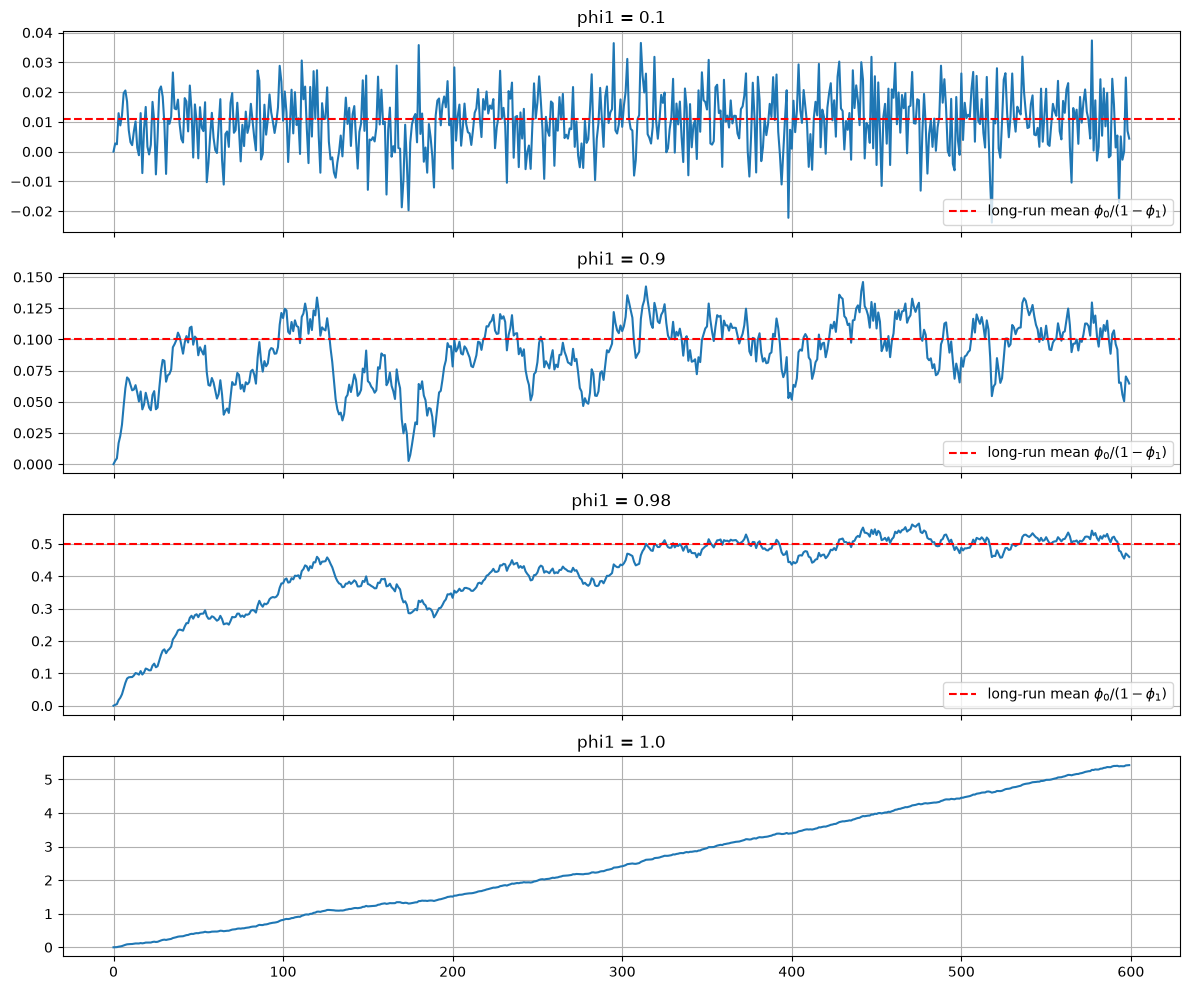

In [2]:
def simulate_ar1(phi0, phi1, shocks, y0=0.0):
    """Simulate Y_t = phi0 + phi1*Y_{t-1} + e_t using the given shocks."""
    y = np.zeros(len(shocks))
    y[0] = y0
    for t in range(1, len(shocks)):
        y[t] = phi0 + phi1 * y[t-1] + shocks[t]
    return y

n = 600
rng = np.random.default_rng(10)
shocks = rng.normal(0, 0.01, n)    # sigma of the shock = 0.01
phi0 = 0.01
phi1_values = [0.10, 0.90, 0.98, 1.00]

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
sims = {}
for ax, p1 in zip(axes, phi1_values):
    sims[p1] = simulate_ar1(phi0, p1, shocks)
    ax.plot(sims[p1])
    if p1 < 1:
        ax.axhline(phi0 / (1 - p1), color='red', linestyle='--', label=r'long-run mean $\phi_0/(1-\phi_1)$')
        ax.legend(loc='lower right')
    ax.set_title(f'phi1 = {p1}')
    ax.grid(True)
plt.tight_layout()
plt.show()

Comparo la teoría con las series simuladas. Para los estadísticos muestrales uso solo la **segunda mitad** de cada serie, para que el valor inicial $Y_0=0$ no los distorsione (la serie con $\phi_1=0.98$ tarda mucho en llegar a su media de 0.5).

In [3]:
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)

rows = []
for p1 in phi1_values:
    y = sims[p1][n // 2:]
    rows.append({
        'phi1': p1,
        'theoretical mean': phi0 / (1 - p1) if p1 < 1 else np.nan,
        'sample mean (2nd half)': y.mean(),
        'lag-1 autocorrelation': pd.Series(y).autocorr(1),
        'half-life (periods)': np.log(0.5) / np.log(p1) if p1 < 1 else np.inf,
    })
ar1_table = pd.DataFrame(rows).round(4)
ar1_table

,phi1,theoretical mean,sample mean (2nd half),lag-1 autocorrelation,half-life (periods)
0,0.10,0.0111,0.0112,0.0202,0.3010
1,0.90,0.1000,0.1020,0.8303,6.5788
2,0.98,0.5000,0.4994,0.9217,34.3096
3,1.00,NaN,3.9554,0.9999,inf


**Mis respuestas al ejercicio en clase**

- **$\phi_1$ pequeño (0.10):** la serie es casi ruido blanco alrededor de su media (0.0111). Un shock desaparece casi de inmediato: la vida media es 0.3 periodos y la autocorrelación en el lag 1 es solo 0.02. **$\phi_1$ cercano a 1:** la serie se vuelve muy persistente: se aleja de su media por periodos largos y tarda mucho en regresar (autocorrelación de 0.83 con $\phi_1=0.9$ y 0.92 con $\phi_1=0.98$). Con $\phi_1=1$ ya no hay media: el drift se acumula y la serie sigue subiendo (la media de la segunda mitad es 3.96, y no se estabiliza).
- **$\phi_1=0.98$:** la vida media es **34.3 periodos**. A 12 periodos todavía queda $0.98^{12}=78\%$ del shock, así que un pronóstico a 12 periodos casi no regresa a la media de largo plazo: a ese horizonte la serie se comporta casi como una caminata aleatoria (solo a muy largo plazo regresa a 0.5).
- **¿Por qué es difícil distinguir 0.98 de 1?** En ventanas cortas las dos trayectorias son casi iguales porque la "fuerza" que regresa la serie a su media es muy débil: la ADF estima $\gamma=\phi_1-1=-0.02$, un número casi cero. Con pocas observaciones el error estándar de $\hat\gamma$ es más grande que esa diferencia, así que la prueba no puede rechazar $H_0$ (tiene poco **poder**).

## A.5 Autocorrelación: un primer vistazo

La **autocorrelación** en el lag $k$ es la correlación entre $Y_t$ y $Y_{t-k}$. Para un AR(1) estacionario la teoría dice que $\rho_k=\phi_1^k$: decae geométricamente. En una caminata aleatoria las autocorrelaciones muestrales decaen **muy lento**, lo cual es una señal visual de raíz unitaria. La **función de autocorrelación (ACF)** grafica $\rho_k$ para muchos lags:

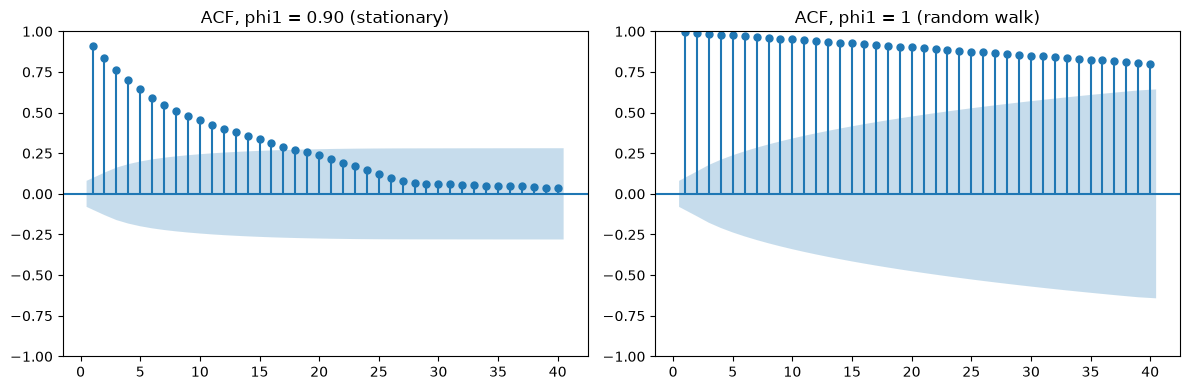

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(sims[0.90], lags=40, zero=False, ax=axes[0], title='ACF, phi1 = 0.90 (stationary)')
plot_acf(sims[1.00], lags=40, zero=False, ax=axes[1], title='ACF, phi1 = 1 (random walk)')
plt.tight_layout()
plt.show()

El área azul es la banda de confianza al 95%: las barras fuera de ella son significativamente distintas de cero. Con $\phi_1=0.9$ la ACF cae relativamente rápido hacia cero; con la caminata aleatoria se queda alta en los 40 lags. La ACF se usa mucho en la Parte C.

## A.6 Datos reales: ventas de productos de consumo

Uso otra vez el dataset mensual de ventas en volumen (toneladas) de las marcas de una categoría de producto de consumo:

In [5]:
url = "http://www.apradie.com/ec2004/salesbrands3.xlsx"
response = requests.get(url, headers=headers)
response.raise_for_status()
sales_brand = pd.read_excel(BytesIO(response.content), sheet_name='Resultado')

Convierto `date` a fecha, la pongo como índice y declaro la frecuencia mensual (`'MS'` = primer día del mes). Después identifico las columnas de volumen de cada marca:

In [6]:
sales_brand['date'] = pd.to_datetime(sales_brand['date'])
sales_brand = sales_brand.set_index('date').sort_index().asfreq('MS')
brand_cols = [c for c in sales_brand.columns if c.startswith('qbrand')]
print(brand_cols)

['qbrand1tons', 'qbrand2tons', 'qbrand3tons', 'qbrand4tons', 'qbrand5tons', 'qbrand6tons']


Grafico las marcas 2 y 6:

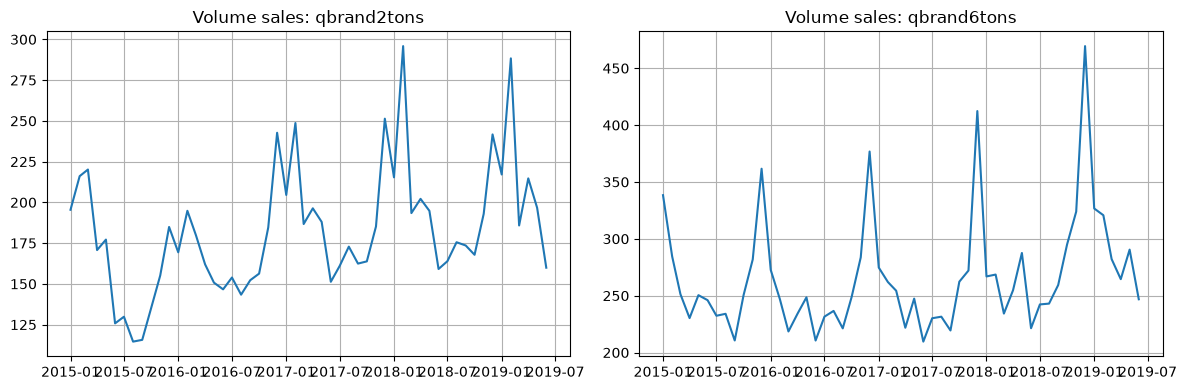

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['qbrand2tons', 'qbrand6tons']):
    ax.plot(sales_brand.index, sales_brand[col])
    ax.set_title(f'Volume sales: {col}')
    ax.grid(True)
plt.tight_layout()
plt.show()

Las dos series tienen **tendencia y estacionalidad**, así que no son estacionarias: su media cambia con el tiempo. La mayoría de las variables de negocio (ventas, ingresos, costos, precios) se comportan así.

## A.7 Transformaciones para volver estacionaria una serie

### Logs y diferencias

La receta usual para series de negocio es:

1. Sacar el **logaritmo natural**. Convierte cambios proporcionales en aditivos y estabiliza la varianza cuando crece con el nivel.
2. Sacar una **diferencia** del log.

¿Por qué la diferencia de logs es un % de cambio? Si $R_t$ es el cambio % simple, entonces $Y_t=Y_{t-1}(1+R_t)$ y

$$\ln(Y_t)-\ln(Y_{t-1})=\ln\left(\frac{Y_t}{Y_{t-1}}\right)=\ln(1+R_t)\approx R_t \quad \text{(para } R_t\text{ pequeño)}$$

La diferencia de logs es el **cambio % con capitalización continua**. Para cambios pequeños es casi igual al cambio % simple; para cambios grandes no, y se regresa con $R_t=e^{\Delta \ln Y_t}-1$. Ejemplo: una diferencia de logs de $-0.25$ es un cambio simple de $e^{-0.25}-1=-22.1\%$, no $-25\%$.

Con datos mensuales hay dos diferencias útiles:

- **Primera diferencia del log**: $\ln Y_t-\ln Y_{t-1}$ = cambio % **mensual**.
- **Diferencia estacional del log**: $\ln Y_t-\ln Y_{t-12}$ = cambio % **anual**, mes por mes. Como compara cada mes con el mismo mes del año anterior, también **elimina la estacionalidad**.

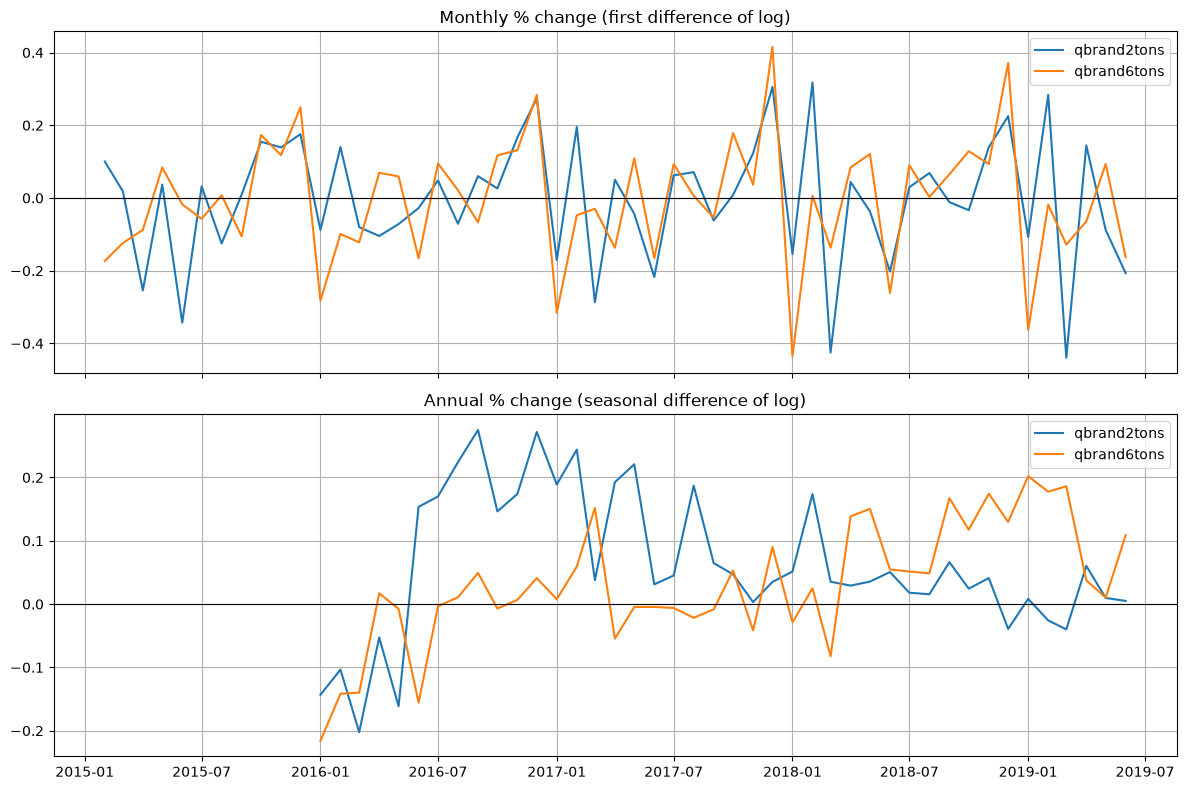

In [8]:
ln_sales = np.log(sales_brand[brand_cols])
msales_growth = ln_sales.diff(1)    # monthly % change
ysales_growth = ln_sales.diff(12)   # annual % change

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for col in ['qbrand2tons', 'qbrand6tons']:
    axes[0].plot(msales_growth.index, msales_growth[col], label=col)
    axes[1].plot(ysales_growth.index, ysales_growth[col], label=col)
axes[0].set_title('Monthly % change (first difference of log)')
axes[1].set_title('Annual % change (seasonal difference of log)')
for ax in axes:
    ax.axhline(0, color='black', linewidth=0.8)
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

El cambio % **mensual** ya no tiene tendencia, pero tiene picos y valles grandes y regulares: la **estacionalidad sigue ahí**. El cambio % **anual** no tiene tendencia ni patrón estacional. Si estas series son estacionarias es difícil decirlo a ojo; necesitamos una prueba estadística.

## A.8 La prueba Augmented Dickey-Fuller (ADF)

La prueba de Dickey-Fuller parte del AR(1) y resta $Y_{t-1}$ de ambos lados:

$$\Delta Y_t = \phi_0 + (\phi_1-1)Y_{t-1} + \varepsilon_t = \phi_0 + \gamma Y_{t-1} + \varepsilon_t$$

- $H_0: \gamma=0$ (es decir, $\phi_1=1$): la serie tiene **raíz unitaria**, no es estacionaria.
- $H_A: \gamma<0$ (es decir, $\phi_1<1$): la serie es **estacionaria**.

Por eso se llama prueba de raíz unitaria. La versión **aumentada** agrega lags de $\Delta Y_t$ a la regresión para absorber la autocorrelación de corto plazo; `adfuller` elige cuántos con el criterio AIC. Bajo $H_0$ el estadístico **no** sigue una distribución t, así que se usan los valores críticos especiales de Dickey-Fuller (`adfuller` calcula el p-value).

### ¿Qué versión de la prueba?

El argumento `regression` decide qué términos determinísticos entran a la regresión de la prueba:

| `regression` | La regresión incluye | Usarla cuando la serie… |
|---|---|---|
| `'n'` | nada | fluctúa alrededor de cero (raro) |
| `'c'` | constante | fluctúa alrededor de una media distinta de cero, sin tendencia. Típico de tasas de crecimiento / rendimientos |
| `'ct'` | constante y tendencia lineal | tiene una tendencia visible. Típico de log-niveles (entonces $H_A$ = estacionaria alrededor de una tendencia) |

Función auxiliar para reportar la prueba:

In [9]:
from statsmodels.tsa.stattools import adfuller, kpss

def adf_test(x, regression='c'):
    """Run the ADF test and return the key results in a dictionary."""
    res = adfuller(x.dropna(), regression=regression, autolag='AIC')
    return {'ADF stat': res[0], 'p-value': res[1], 'lags used': res[2], 'obs': res[3]}

La aplico a tres versiones de la marca 2: log-nivel, cambio % mensual y cambio % anual:

In [10]:
q2 = 'qbrand2tons'
adf_q2 = pd.DataFrame({
    'log level (ct)': adf_test(ln_sales[q2], 'ct'),
    'monthly % change (c)': adf_test(msales_growth[q2], 'c'),
    'annual % change (c)': adf_test(ysales_growth[q2], 'c'),
}).T.round(4)
adf_q2

,ADF stat,p-value,lags used,obs
log level (ct),-0.3013,0.9895,11.0,42.0
monthly % change (c),-2.7994,0.0584,11.0,41.0
annual % change (c),-2.4884,0.1183,3.0,38.0


Cómo leer la tabla:

- Si el **p-value < 0.05**, rechazo $H_0$ (raíz unitaria) al 5% y trato la serie como **estacionaria**.
- Si el **p-value > 0.05**, no puedo rechazar la raíz unitaria y trato la serie como **no estacionaria**.

In [11]:
p_level = adf_q2.loc['log level (ct)', 'p-value']
p_annual = adf_q2.loc['annual % change (c)', 'p-value']
verdict_level = "reject" if p_level < 0.05 else "cannot reject"
verdict_annual = "reject" if p_annual < 0.05 else "cannot reject"
print(f"Brand 2, log level:      p-value = {p_level:.4f} -> {verdict_level} the unit root")
print(f"Brand 2, annual % change: p-value = {p_annual:.4f} -> {verdict_annual} the unit root")

Brand 2, log level:      p-value = 0.9895 -> cannot reject the unit root
Brand 2, annual % change: p-value = 0.1183 -> cannot reject the unit root


> **Dos precauciones con la prueba ADF**
> - **Poco poder cerca de la raíz unitaria.** En el ejercicio de simulación vimos que una serie con $\phi_1=0.98$ se ve casi igual que una caminata aleatoria. Con pocas observaciones la ADF muchas veces no rechaza $H_0$ aunque la serie sea estacionaria. "No rechazar" **no es** "probar que no es estacionaria".
> - **Estacionalidad.** Un patrón estacional fuerte en el cambio % mensual puede distorsionar la prueba. Es una razón más para preferir el cambio % anual en datos mensuales de negocio.

### Prueba cruzada: KPSS

La prueba KPSS **invierte las hipótesis**: $H_0$ = la serie **es estacionaria**. Usar ambas pruebas da una conclusión más confiable:

| ADF ($H_0$: raíz unitaria) | KPSS ($H_0$: estacionaria) | Conclusión |
|---|---|---|
| rechaza | no rechaza | estacionaria |
| no rechaza | rechaza | no estacionaria |
| rechaza | rechaza | ambigua: posible cambio estructural o memoria larga |
| no rechaza | no rechaza | ambigua: no hay suficientes datos para decidir |

In [12]:
kpss_stat, kpss_p, _, _ = kpss(ysales_growth[q2].dropna(), regression='c', nlags='auto')
print(f"KPSS for the annual % change of brand 2: stat = {kpss_stat:.3f}, p-value = {kpss_p:.3f}")

KPSS for the annual % change of brand 2: stat = 0.199, p-value = 0.100


/var/folders/06/082vc2px7v791h689yrjpmv80000gn/T/ipykernel_61128/1499342955.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, _, _ = kpss(ysales_growth[q2].dropna(), regression='c', nlags='auto')


Nota: `kpss` solo reporta p-values entre 0.01 y 0.10 (manda un *warning* cuando el valor real está fuera de ese rango). Un p-value de 0.10 significa "0.10 o más": no se rechaza la estacionariedad.

---
# CHALLENGE 1 (Parte A)

1. Construir una tabla con los p-values de la ADF de **todas las marcas** para tres versiones de cada serie: log-nivel (`'ct'`), cambio % mensual (`'c'`) y cambio % anual (`'c'`).
2. Agregar una columna con el p-value de la KPSS del cambio % anual.
3. Para cada marca decidir qué versión usaría para modelar y justificarlo. Identificar al menos una marca con pruebas ambiguas y explicar qué lo puede causar (viendo su gráfica).
4. Con la simulación AR(1), calcular la vida media de un shock para $\phi_1=0.5, 0.9$ y $0.99$ con datos mensuales e interpretarla para las ventas de una marca.

### 1.1 y 1.2 Tabla de p-values ADF y KPSS

Recorro `brand_cols` y uso `adf_test`. Además agrego una columna con la conclusión combinada ADF + KPSS del cambio % anual, siguiendo la tabla de decisión de arriba (al 5%). Los *warnings* de la KPSS los silencio porque solo avisan que el p-value está fuera del rango 0.01–0.10.

In [13]:
import warnings

def adf_kpss_verdict(p_adf, p_kpss, alpha=0.05):
    """Combined conclusion of the ADF (H0: unit root) and KPSS (H0: stationary) tests."""
    adf_rej, kpss_rej = p_adf < alpha, p_kpss < alpha
    if adf_rej and not kpss_rej:
        return 'stationary'
    if not adf_rej and kpss_rej:
        return 'non-stationary'
    if adf_rej and kpss_rej:
        return 'ambiguous (both reject)'
    return 'ambiguous (neither rejects)'

rows = []
for col in brand_cols:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        kpss_p_annual = kpss(ysales_growth[col].dropna(), regression='c', nlags='auto')[1]
    p_annual_c = adf_test(ysales_growth[col], 'c')['p-value']
    rows.append({
        'brand': col,
        'ADF log level (ct)': adf_test(ln_sales[col], 'ct')['p-value'],
        'ADF monthly % chg (c)': adf_test(msales_growth[col], 'c')['p-value'],
        'ADF annual % chg (c)': p_annual_c,
        'KPSS annual % chg (c)': kpss_p_annual,
        'annual % chg: ADF+KPSS': adf_kpss_verdict(p_annual_c, kpss_p_annual),
    })
ch1_table = pd.DataFrame(rows).set_index('brand').round(4)
ch1_table

,ADF log level (ct),ADF monthly % chg (c),ADF annual % chg (c),KPSS annual % chg (c),annual % chg: ADF+KPSS
brand,,,,,
qbrand1tons,0.9869,0.2227,0.1171,0.0100,non-stationary
qbrand2tons,0.9895,0.0584,0.1183,0.1000,ambiguous (neither rejects)
qbrand3tons,0.9849,0.0074,0.3361,0.1000,ambiguous (neither rejects)
qbrand4tons,0.0013,0.0000,0.0000,0.0802,stationary
qbrand5tons,0.9758,0.8798,0.0213,0.1000,stationary
qbrand6tons,0.8946,0.0258,0.0321,0.0100,ambiguous (both reject)


Para decidir con más contexto grafico el log-nivel y el cambio % anual de las seis marcas. En la gráfica del cambio % anual agrego la media de cada año (línea roja punteada): si la serie fuera estacionaria, esas medias deberían ser parecidas entre sí.

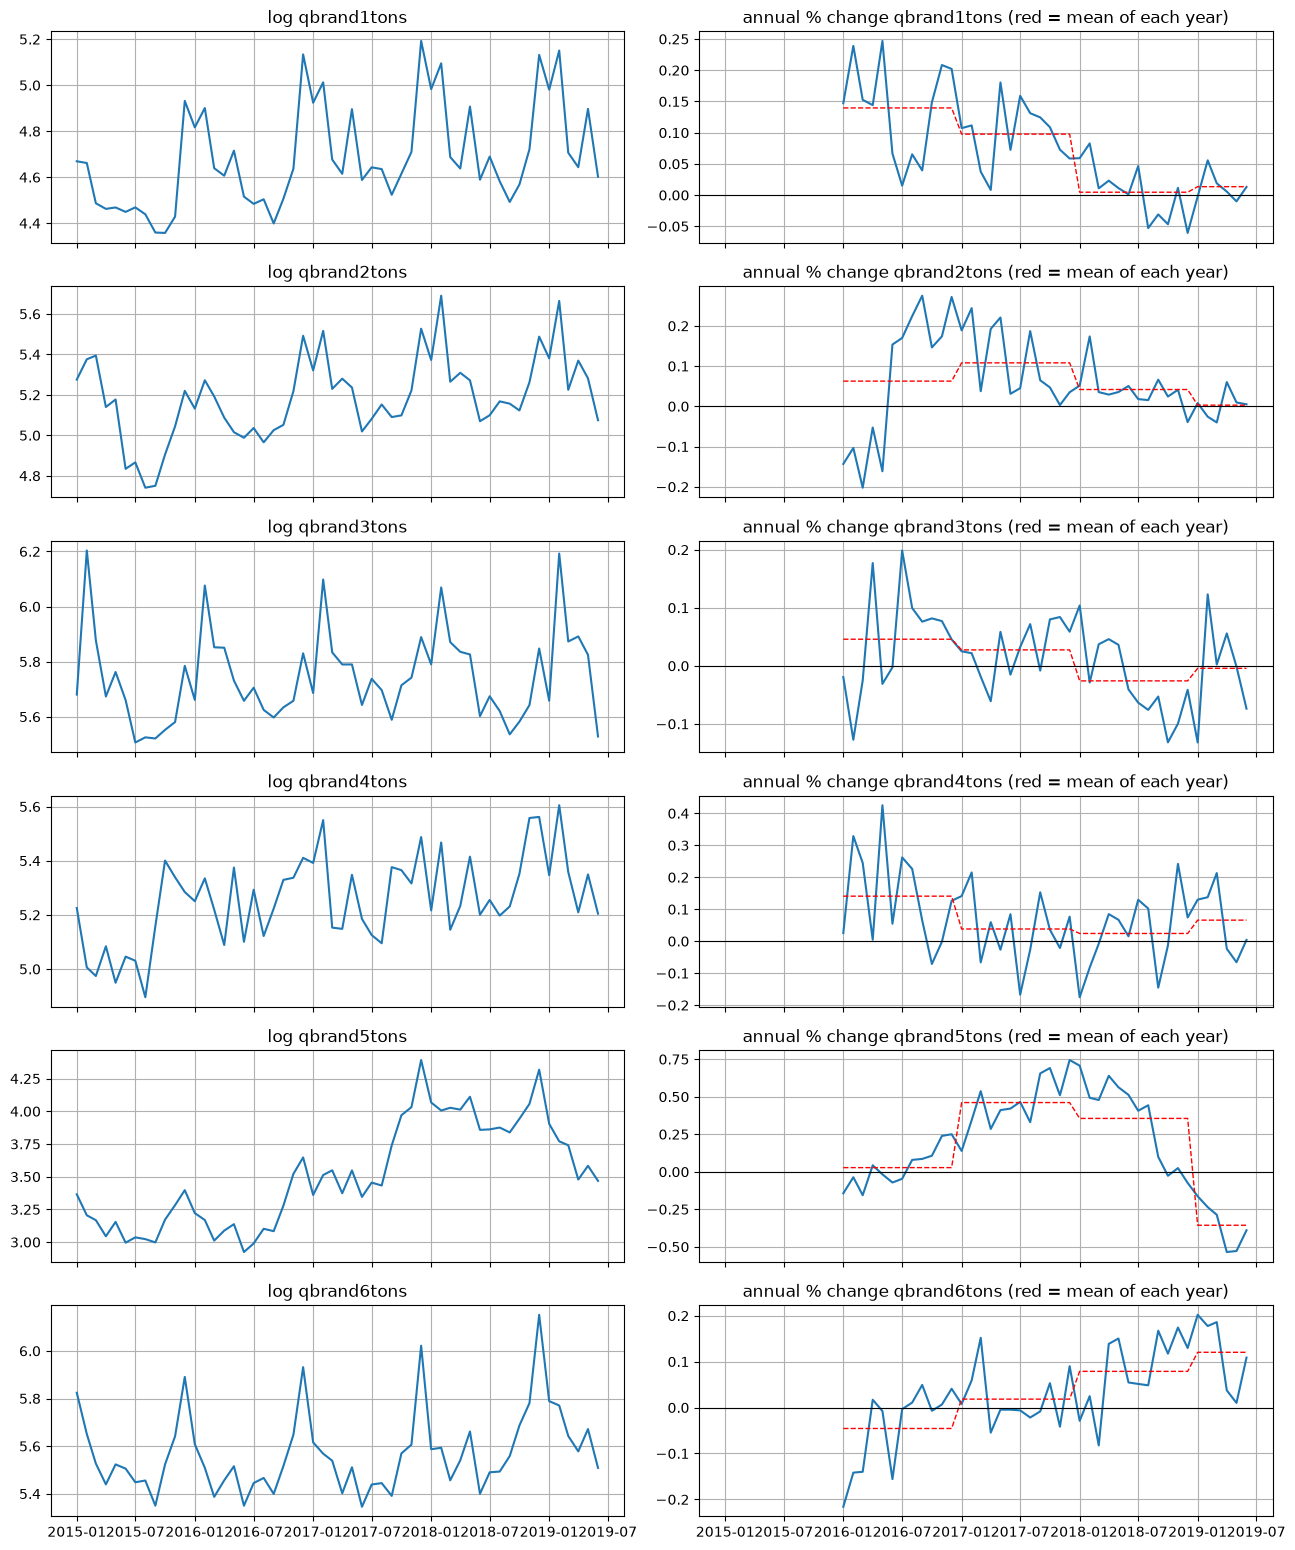

      qbrand1tons  qbrand2tons  qbrand3tons  qbrand4tons  qbrand5tons  qbrand6tons
date                                                                              
2016         14.0          6.3          4.6         14.1          2.8         -4.6
2017          9.8         10.8          2.7          3.8         46.1          1.8
2018          0.5          4.2         -2.6          2.4         35.6          7.9
2019          1.3          0.3         -0.4          6.6        -35.6         12.0


In [14]:
fig, axes = plt.subplots(len(brand_cols), 2, figsize=(13, 2.6 * len(brand_cols)), sharex=True)
for i, col in enumerate(brand_cols):
    axes[i, 0].plot(ln_sales.index, ln_sales[col])
    axes[i, 0].set_title(f'log {col}')
    g = ysales_growth[col]
    axes[i, 1].plot(g.index, g)
    yearly_mean = g.groupby(g.index.year).transform('mean')
    axes[i, 1].plot(g.index, yearly_mean, color='red', linestyle='--', linewidth=1)
    axes[i, 1].axhline(0, color='black', linewidth=0.8)
    axes[i, 1].set_title(f'annual % change {col} (red = mean of each year)')
    for ax in axes[i]:
        ax.grid(True)
plt.tight_layout()
plt.show()

# mean of the annual % change by year, to see if the level of the growth rate is stable
print((ysales_growth.groupby(ysales_growth.index.year).mean() * 100).round(1).dropna(how='all'))

Como apoyo para la decisión, también calculo la ADF de la serie con **ambas diferencias** (diferencia anual y luego diferencia mensual del log, es decir $d=1$ y $D=1$), que es la opción cuando el cambio % anual todavía no es estacionario:

In [15]:
adf_d1D1 = pd.Series({col: adf_test(ysales_growth[col].diff(), 'c')['p-value'] for col in brand_cols},
                     name='ADF annual % chg, 1st diff (c)').round(4)
pd.concat([ch1_table[['ADF annual % chg (c)', 'KPSS annual % chg (c)']], adf_d1D1], axis=1)

,ADF annual % chg (c),KPSS annual % chg (c),"ADF annual % chg, 1st diff (c)"
qbrand1tons,0.1171,0.0100,0.3563
qbrand2tons,0.1183,0.1000,0.0191
qbrand3tons,0.3361,0.1000,0.0000
qbrand4tons,0.0000,0.0802,0.5509
qbrand5tons,0.0213,0.1000,0.8495
qbrand6tons,0.0321,0.0100,0.0000


**Interpretación del Challenge 1 (1.3): qué versión usaría para cada marca**

| Marca | Evidencia (p-values) | Lo que muestra la gráfica | Versión para modelar |
|---|---|---|---|
| 1 | Anual: ADF 0.117, KPSS 0.01 → **no estacionaria** | El crecimiento anual va bajando: 14% (2016) → 9.8% → 0.5% → 1.3% | Cambio anual con una diferencia extra ($d=1, D=1$). La ADF de esa versión (0.356) tampoco rechaza, pero con 41 datos tiene poco poder y la media del crecimiento claramente no es constante. |
| 2 | Anual: ADF 0.118, KPSS 0.10 → **ambigua (ninguna rechaza)** | Salto fuerte a inicios de 2016 (de -15% a +20%) y después oscila alrededor de 0–10% | Cambio % anual ($D=1$): la KPSS no rechaza y, quitando el salto de 2016, se ve una media estable. |
| 3 | Mensual: ADF 0.007; Anual: ADF 0.336, KPSS 0.10 → **ambigua (ninguna rechaza)** | El cambio anual oscila alrededor de 0 (entre -13% y +20%) sin tendencia clara | Cambio % anual ($D=1$). El mensual "pasa" la ADF pero conserva la estacionalidad. Diferenciar dos veces (ADF 0.000) arriesga sobrediferenciar. |
| 4 | Log-nivel (ct): ADF 0.001; anual: ADF 0.000, KPSS 0.08 → **estacionaria** | Crece con una tendencia estable | Cambio % anual ($D=1$). Todas las pruebas coinciden; incluso el log-nivel es estacionario alrededor de una tendencia. |
| 5 | Anual: ADF 0.021, KPSS 0.10 → **estacionaria** según las pruebas | **Cambio estructural**: crece ~0% en 2016, +46% en 2017, +36% en 2018 y -36% en 2019 | Cambio % anual ($D=1$), con cuidado: las pruebas dicen estacionaria, pero el nivel de ventas saltó en 2017 y cayó en 2019. Modelaría ese cambio con una variable dummy (intervención). |
| 6 | Anual: ADF 0.032, KPSS 0.01 → **ambigua (las dos rechazan)** | El crecimiento anual sube cada año: -4.6% → 1.8% → 7.9% → 12.0% | $d=1, D=1$: con la diferencia extra la ADF da 0.000. Es la marca del Challenge 3.1. |

**No todas las marcas llevan a la misma decisión.** La marca 4 es la única donde todo coincide. La **marca 6** es el caso más claro de pruebas ambiguas: la ADF rechaza la raíz unitaria y la KPSS rechaza la estacionariedad al mismo tiempo. En la gráfica se ve por qué: el crecimiento anual no fluctúa alrededor de una media fija, sino que **va subiendo** cada año (la marca está acelerando). Eso es una tendencia en la tasa de crecimiento (o un cambio estructural), justo el caso de "ambas rechazan" de la tabla de decisión. Las marcas 2 y 3 son ambiguas en el otro sentido (ninguna rechaza), lo cual es típico de **pocos datos**: con 54 meses solo hay 42 cambios anuales, y la ADF tiene poco poder. En general, las tres fuentes de ambigüedad aquí son: muestra corta, cambios estructurales (marcas 2 y 5) y tasas de crecimiento que cambian de nivel (marcas 1 y 6).

### 1.4 Vida media de un shock para $\phi_1 = 0.5,\ 0.9,\ 0.99$

Con datos mensuales, la vida media $k_{1/2}=\ln(0.5)/\ln(\phi_1)$ queda en **meses**. También calculo qué fracción del shock sigue viva después de 12 meses ($\phi_1^{12}$) y grafico la respuesta a un shock usando `simulate_ar1` (un shock de 1 en el periodo 1 y cero después, con $\phi_0=0$).

 phi1  half-life (months)  share of shock left after 12 months  share of shock left after 36 months
 0.50              1.0000                               0.0002                               0.0000
 0.90              6.5788                               0.2824                               0.0225
 0.99             68.9676                               0.8864                               0.6964


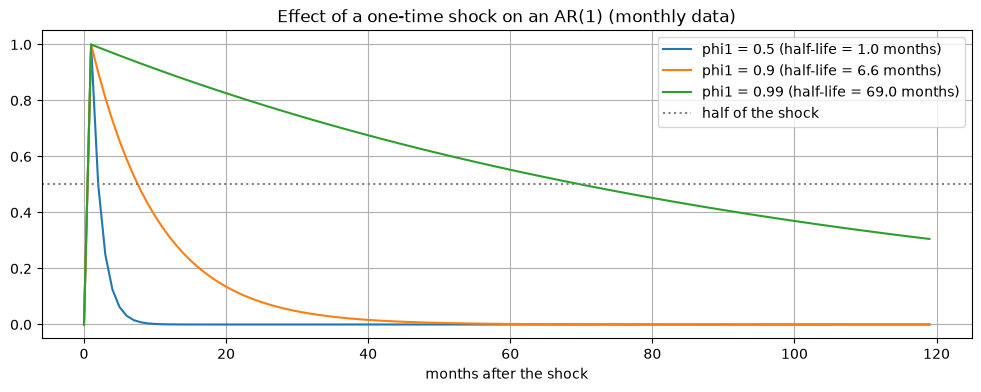

In [16]:
phis = [0.5, 0.9, 0.99]
hl_table = pd.DataFrame({
    'phi1': phis,
    'half-life (months)': [np.log(0.5) / np.log(p) for p in phis],
    'share of shock left after 12 months': [p ** 12 for p in phis],
    'share of shock left after 36 months': [p ** 36 for p in phis],
}).round(4)
print(hl_table.to_string(index=False))

# impulse response with the in-class simulator: one shock of 1 at t=1, no other shocks
horizon = 120
impulse = np.zeros(horizon)
impulse[1] = 1.0
plt.figure(figsize=(12, 4))
for p in phis:
    irf = simulate_ar1(0, p, impulse)
    hl = np.log(0.5) / np.log(p)
    plt.plot(irf, label=f'phi1 = {p} (half-life = {hl:.1f} months)')
plt.axhline(0.5, color='grey', linestyle=':', label='half of the shock')
plt.title('Effect of a one-time shock on an AR(1) (monthly data)')
plt.xlabel('months after the shock')
plt.legend()
plt.grid(True)
plt.show()

**Interpretación del Challenge 1 (1.4): vida media con datos mensuales**

- **$\phi_1=0.5$ → vida media de 1 mes.** Después de 12 meses solo queda 0.02% del shock. Para una marca, un evento inesperado (una promoción, un faltante de inventario, un mes de mucho calor) se olvida en 1–2 meses: las ventas regresan rápido a su nivel normal, y el pronóstico a más de 2–3 meses es básicamente la media.
- **$\phi_1=0.9$ → vida media de 6.6 meses.** A 12 meses todavía queda 28% del efecto y a 36 meses 2%. Un shock como ganar una cadena de autoservicios o una campaña exitosa se nota durante medio año. Conviene planear producción e inventarios tomando en cuenta ese efecto.
- **$\phi_1=0.99$ → vida media de 69 meses (~5.7 años).** A 12 meses queda 89% y a 3 años 70%. En la práctica el shock es casi permanente: la serie se comporta casi como una caminata aleatoria y, como vimos en el ejercicio en clase, con 54 meses de datos sería casi imposible distinguirla de una raíz unitaria. Para la marca, un shock así (por ejemplo, perder un distribuidor importante) cambia el nivel de ventas por años.

Mientras más cerca de 1 está $\phi_1$, más memoria tiene la serie y menos sirve la media histórica como pronóstico.

---
# PARTE B. Regresión espuria y cointegración

## B.1 Regresión espuria: una simulación

Simulo dos caminatas aleatorias **completamente independientes** (construidas con shocks distintos, así que no hay ninguna relación entre ellas) y hago una regresión de una contra la otra:

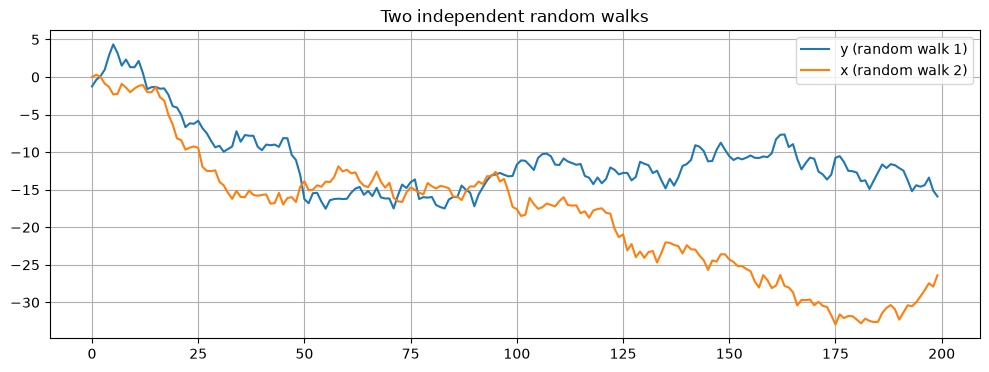

In [17]:
rng = np.random.default_rng(7)
n = 200
x_rw = np.cumsum(rng.normal(0, 1, n))
y_rw = np.cumsum(rng.normal(0, 1, n))
sim_df = pd.DataFrame({'y': y_rw, 'x': x_rw})

plt.figure(figsize=(12, 4))
plt.plot(sim_df['y'], label='y (random walk 1)')
plt.plot(sim_df['x'], label='x (random walk 2)')
plt.title('Two independent random walks')
plt.legend()
plt.grid(True)
plt.show()

In [18]:
spur = smf.ols('y ~ x', data=sim_df).fit()
print(spur.summary().tables[1])
print(f"R-squared = {spur.rsquared:.3f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -5.8696      0.686     -8.552      0.000      -7.223      -4.516
x              0.2813      0.034      8.285      0.000       0.214       0.348
R-squared = 0.257


Muy seguido (se puede probar con otras semillas) la regresión encuentra una relación "significativa", con una R² alta, entre dos series que no tienen nada que ver. Esto es una **regresión espuria** (Granger y Newbold, 1974).

¿Qué tan seguido pasa? Repito el experimento 500 veces para distintos tamaños de muestra y cuento cuántas veces el p-value de la pendiente es menor a 0.05. Si la prueba funcionara bien debería pasar ~5% de las veces, porque la pendiente verdadera es cero:

In [19]:
def spurious_rate(n, reps=500, differences=False, seed=0):
    """Share of regressions with p<0.05 between two INDEPENDENT random walks."""
    rng = np.random.default_rng(seed)
    count = 0
    for _ in range(reps):
        x = np.cumsum(rng.normal(size=n))
        y = np.cumsum(rng.normal(size=n))
        if differences:
            x, y = np.diff(x), np.diff(y)
        p = sm.OLS(y, sm.add_constant(x)).fit().pvalues[1]
        count += p < 0.05
    return count / reps

spurious_table = pd.DataFrame({
    'n': [50, 200, 1000],
    'p<0.05 in LEVELS': [spurious_rate(k) for k in [50, 200, 1000]],
    'p<0.05 in DIFFERENCES': [spurious_rate(k, differences=True) for k in [50, 200, 1000]],
})
spurious_table

,n,p<0.05 in LEVELS,p<0.05 in DIFFERENCES
0,50,0.700,0.072
1,200,0.818,0.050
2,1000,0.922,0.050


In [20]:
rate_200 = float(spurious_table.loc[spurious_table['n'] == 200, 'p<0.05 in LEVELS'].iloc[0])
print(f"With n=200, the regression in levels is 'significant' in {100*rate_200:.1f}% of the cases (expected: 5%)")

With n=200, the regression in levels is 'significant' in 81.8% of the cases (expected: 5%)


En niveles la regresión declara una relación "significativa" en la gran mayoría de los casos en lugar del 5%, y **empeora con más datos**. En diferencias (que son estacionarias) la tasa queda cerca del 5% esperado.

¿Por qué? Si $y$ y $x$ son caminatas aleatorias independientes, el error de la regresión $y_t-\beta_0-\beta_1x_t$ es también una caminata aleatoria: no estacionario y muy autocorrelacionado, lo cual rompe los supuestos de OLS. Los estadísticos t ya no siguen una distribución t y se hacen más grandes conforme crece $n$. Señal clásica de alerta: una **R² mayor que el estadístico Durbin-Watson**.

In [21]:
from statsmodels.stats.stattools import durbin_watson
print(f"R-squared = {spur.rsquared:.3f},  Durbin-Watson = {durbin_watson(spur.resid):.3f}")

R-squared = 0.257,  Durbin-Watson = 0.061


Un Durbin-Watson cercano a 0 significa que los residuales están fuertemente autocorrelacionados de forma positiva (el valor "bueno" es cercano a 2).

## B.2 Regresión espuria con datos reales

Descargo del Banco Mundial dos indicadores anuales de México que no deberían estar relacionados directamente: la **tasa de mortalidad infantil** (muertes por cada 1,000 nacidos vivos) y un **índice del valor de las exportaciones de mercancías**. Uso directamente la API del Banco Mundial:

In [22]:
def get_wb(indicator, country='MEX', start=1980, end=2024):
    """Download one World Bank indicator for one country as a pandas Series."""
    url = (f"https://api.worldbank.org/v2/country/{country}/indicator/{indicator}"
           f"?format=json&date={start}:{end}&per_page=500")
    js = requests.get(url, timeout=60).json()
    s = pd.Series({int(d['date']): d['value'] for d in js[1]}, dtype=float)
    return s.sort_index()

wb = pd.DataFrame({
    'infant_mortality': get_wb('SP.DYN.IMRT.IN'),
    'exports': get_wb('TX.VAL.MRCH.XD.WD'),
}).dropna()
wb.tail()

,infant_mortality,exports
2020,13.4,109.6
2021,13.1,130.1
2022,12.8,151.8
2023,12.4,155.8
2024,12.1,162.2


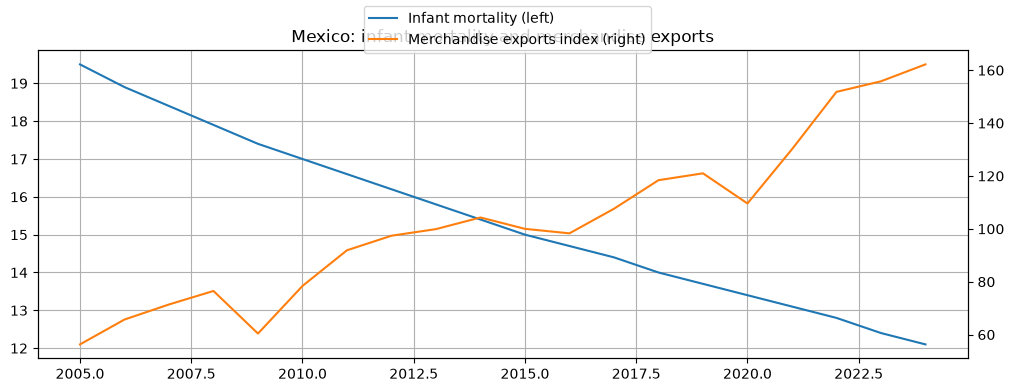

In [23]:
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(wb.index, wb['infant_mortality'], color='tab:blue', label='Infant mortality (left)')
ax2 = ax1.twinx()
ax2.plot(wb.index, wb['exports'], color='tab:orange', label='Merchandise exports index (right)')
ax1.set_title('Mexico: infant mortality and merchandise exports')
fig.legend(loc='upper center')
ax1.grid(True)
plt.show()

Regresión del log de exportaciones contra el log de mortalidad infantil, primero en niveles y luego en diferencias (cambios % anuales):

In [24]:
wb_log = np.log(wb)
reg_levels = smf.ols('exports ~ infant_mortality', data=wb_log).fit()
reg_diffs = smf.ols('exports ~ infant_mortality', data=wb_log.diff().dropna()).fit()

wb_results = pd.DataFrame({
    'slope': [reg_levels.params['infant_mortality'], reg_diffs.params['infant_mortality']],
    'p-value': [reg_levels.pvalues['infant_mortality'], reg_diffs.pvalues['infant_mortality']],
    'R-squared': [reg_levels.rsquared, reg_diffs.rsquared],
    'Durbin-Watson': [durbin_watson(reg_levels.resid), durbin_watson(reg_diffs.resid)],
}, index=['levels (logs)', 'differences (% changes)']).round(4)
wb_results

,slope,p-value,R-squared,Durbin-Watson
levels (logs),-2.0169,0.0000,0.9212,1.5875
differences (% changes),3.4032,0.6791,0.0103,2.2280


**Discusión en clase (mortalidad infantil vs. exportaciones)**

- **En niveles** la regresión encuentra una relación muy "significativa": pendiente -2.02, p-value ≈ 0 y R² = 0.92. Leída literalmente, una mortalidad infantil 1% más baja iría con exportaciones 2% más altas.
- **No tiene sentido causal.** No hay un mecanismo por el cual bajar la mortalidad infantil aumente las exportaciones. Las dos variables siguen la tendencia de desarrollo de México: una baja y la otra sube con los años.
- **En diferencias** (cambios % anuales) la relación desaparece: la pendiente cambia de signo (3.40), el p-value es 0.68 y la R² es 0.01. Cuando quito las tendencias no queda nada.
- **Ojo:** aquí el Durbin-Watson en niveles (1.59) no es menor que la R², así que la regla "R² > DW" no detecta el problema. Esa regla es una señal de alerta, no una prueba. Lo que revela que la relación es espuria es la regresión en diferencias y, más abajo, la prueba de cointegración.

Ambas series se mueven con el desarrollo de largo plazo del país: una baja y la otra sube a lo largo de las décadas. La regresión en niveles captura esas **tendencias comunes**, no una relación directa. Pero cuidado: no toda regresión entre series no estacionarias es espuria. La excepción es la **cointegración**.

## B.3 Cointegración

### La idea: una borracha y su perro

Dos series están **cointegradas** si cada una es no estacionaria (tiene raíz unitaria), pero existe una **combinación lineal** de ellas que sí es estacionaria (Engle y Granger, 1987):

$$Y_t \text{ y } X_t \text{ son I(1)}, \quad\text{pero}\quad u_t = Y_t-\beta_0-\beta_1X_t \text{ es estacionaria (I(0))}$$

La imagen clásica (Murray, 1994): una borracha caminando a casa con su perro. Cada uno deambula como una caminata aleatoria, así que no se puede predecir dónde estará cada uno en una hora. Pero nunca se alejan demasiado: cuando se separan, el perro regresa (o ella lo llama). **La distancia entre ellos es estacionaria**. Hay un equilibrio de largo plazo y las desviaciones son temporales.

Cuando dos series están cointegradas, la regresión en niveles **no es espuria**: estima la relación de equilibrio de largo plazo.

### Un par cointegrado simulado

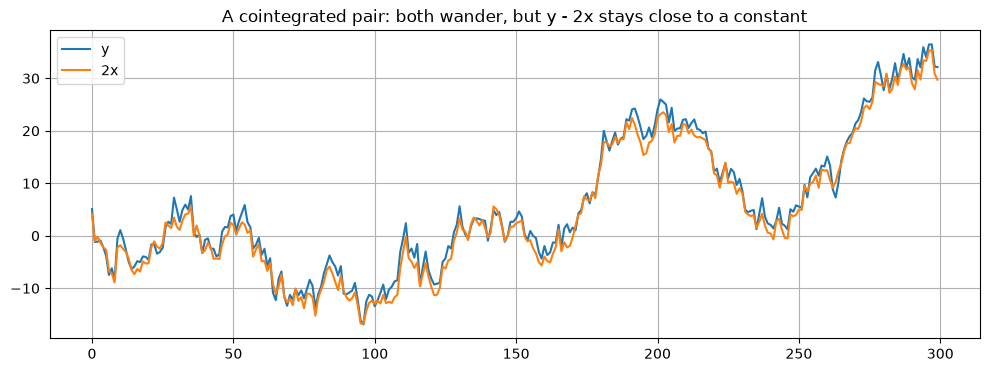

In [25]:
rng = np.random.default_rng(3)
n = 300
x_c = np.cumsum(rng.normal(0, 1, n))                       # random walk
u_c = simulate_ar1(0, 0.5, rng.normal(0, 1, n))           # stationary deviation
y_c = 1 + 2 * x_c + u_c                                    # cointegrated with x
coint_df = pd.DataFrame({'y': y_c, 'x': x_c})

plt.figure(figsize=(12, 4))
plt.plot(coint_df['y'], label='y')
plt.plot(2 * coint_df['x'], label='2x')
plt.title('A cointegrated pair: both wander, but y - 2x stays close to a constant')
plt.legend()
plt.grid(True)
plt.show()

### La prueba de Engle-Granger

Pasos:

1. Verificar que ambas series sean I(1): la ADF no rechaza en niveles, pero sí rechaza en primeras diferencias.
2. Correr la regresión en niveles: $Y_t=\beta_0+\beta_1X_t+u_t$.
3. Probar si los residuales $\hat u_t$ son estacionarios con una prueba de raíz unitaria.

Hay una sutileza en el paso 3: los residuales vienen de una regresión que eligió $\beta$ para hacerlos lo más pequeños y "estacionarios" posible. Por eso los valores críticos usuales de la ADF rechazan demasiado; hay que usar los **valores críticos de Engle-Granger**, que son más exigentes. La función `coint` de statsmodels hace los pasos 2 y 3 con los valores críticos correctos:

In [26]:
from statsmodels.tsa.stattools import coint

# Wrong way (for comparison): plain ADF on the residuals
resid_c = smf.ols('y ~ x', data=coint_df).fit().resid
p_wrong = adfuller(resid_c, regression='n')[1]

# Right way: Engle-Granger with the proper critical values
eg_stat, p_eg, eg_crit = coint(coint_df['y'], coint_df['x'], trend='c')
print(f"Plain ADF on residuals (wrong critical values): p = {p_wrong:.4f}")
print(f"Engle-Granger test (coint):                     p = {p_eg:.4f}")

Plain ADF on residuals (wrong critical values): p = 0.0000
Engle-Granger test (coint):                     p = 0.0000


$H_0$ de Engle-Granger: **no hay cointegración**. Si el p-value < 0.05 concluyo que las series están cointegradas. Para el par simulado se detecta claramente. Para las caminatas independientes del ejemplo espurio no debería:

In [27]:
p_eg_spur = coint(sim_df['y'], sim_df['x'], trend='c')[1]
print(f"Engle-Granger p-value, independent random walks: {p_eg_spur:.4f}")

Engle-Granger p-value, independent random walks: 0.4547


¿Y la mortalidad infantil con las exportaciones?

In [28]:
p_eg_wb = coint(wb_log['exports'], wb_log['infant_mortality'], trend='c')[1]
wb_verdict = "are cointegrated, so the regression in levels could be interpreted as a long-run relationship" if p_eg_wb < 0.05 else "are NOT cointegrated, so the regression in levels is spurious"
print(f"Engle-Granger p-value: {p_eg_wb:.4f} -> the series {wb_verdict}")

Engle-Granger p-value: 0.9859 -> the series are NOT cointegrated, so the regression in levels is spurious


Según la prueba, las dos series **no están cointegradas**, así que la regresión en niveles es espuria. Con pocas observaciones anuales la prueba tiene poco poder, por eso se combina con la lógica económica (no hay razón para que la mortalidad infantil cause exportaciones).

## B.4 Un par cointegrado real: WTI vs. Brent

El WTI (West Texas Intermediate, EE.UU.) y el Brent (Mar del Norte) son dos petróleos de referencia. Son **sustitutos cercanos**: si uno se abarata mucho respecto al otro, los compradores se cambian y el arbitraje tiende a cerrar la brecha. Eso sugiere cointegración. Descargo de Yahoo Finance los precios diarios de los futuros del mes más cercano del WTI (`CL=F`) y del Brent (`BZ=F`) de 2008 a fines de 2025, y saco promedios mensuales.

La función `get_yahoo` descarga un ticker, reintenta si Yahoo no responde y guarda una copia local en `yahoo_data/`, para que la siguiente vez no necesite internet:

In [29]:
import os
import time
import yfinance as yf

def get_yahoo(ticker, start='2000-01-01', end='2026-01-01', cache_dir='yahoo_data', retries=3):
    """Download daily closing prices from Yahoo Finance as a pandas Series.

    - `end` is NOT included (yfinance convention).
    - If Yahoo returns no data, it waits and tries again.
    - The first successful download is saved in the folder `yahoo_data/`; later renders read
      that file and do not need the internet. Delete the folder to download fresh data.
    """
    os.makedirs(cache_dir, exist_ok=True)
    name = ticker.replace('^', '').replace('=', '_')
    cache_file = os.path.join(cache_dir, f"{name}_{start}_{end}.csv")
    if os.path.exists(cache_file):
        return pd.read_csv(cache_file, index_col=0, parse_dates=True).iloc[:, 0].rename(ticker)
    for attempt in range(1, retries + 1):
        try:
            s = yf.download(ticker, start=start, end=end, auto_adjust=True, progress=False)['Close']
            s = s.squeeze('columns').dropna() if isinstance(s, pd.DataFrame) else s.dropna()
            if len(s) > 0:
                s = s.rename(ticker)
                s.index.name = 'date'
                s.to_csv(cache_file)
                return s
            print(f"Attempt {attempt}/{retries}: Yahoo returned no data for {ticker}")
        except Exception as e:
            print(f"Attempt {attempt}/{retries} for {ticker} failed: {type(e).__name__}")
        time.sleep(5 * attempt)
    raise RuntimeError(f"Could not download {ticker} from Yahoo Finance. Try again later.")

oil_daily = pd.DataFrame({'wti': get_yahoo('CL=F', start='2008-01-01', end='2026-01-01'),
                          'brent': get_yahoo('BZ=F', start='2008-01-01', end='2026-01-01')})

Uso **promedios mensuales**. Esto también evita el 20 de abril de 2020, cuando el futuro del WTI cerró en negativo (~ -37 dólares por barril), que no tiene logaritmo.

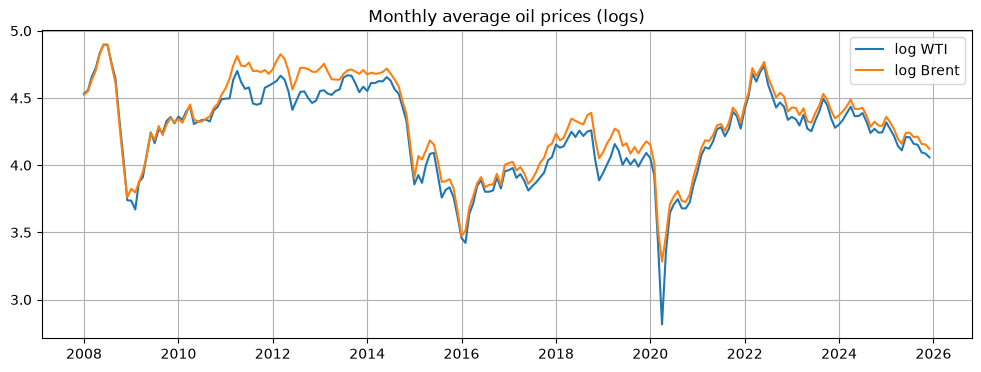

In [30]:
oil = oil_daily.resample('MS').mean().loc[:'2025-12-01'].dropna()
ln_oil = np.log(oil)

plt.figure(figsize=(12, 4))
plt.plot(ln_oil.index, ln_oil['wti'], label='log WTI')
plt.plot(ln_oil.index, ln_oil['brent'], label='log Brent')
plt.title('Monthly average oil prices (logs)')
plt.legend()
plt.grid(True)
plt.show()

**Paso 0:** ¿ambas series son I(1)?

In [31]:
oil_i1 = pd.DataFrame({
    'p-value ADF level (c)': [adf_test(ln_oil[c], 'c')['p-value'] for c in ['wti', 'brent']],
    'p-value ADF 1st diff (c)': [adf_test(ln_oil[c].diff(), 'c')['p-value'] for c in ['wti', 'brent']],
}, index=['log WTI', 'log Brent']).round(4)
oil_i1

,p-value ADF level (c),p-value ADF 1st diff (c)
log WTI,0.0224,0.0
log Brent,0.0428,0.0


Esperamos p-values altos en niveles (no se rechaza la raíz unitaria) y muy bajos en diferencias. Las diferencias claramente son estacionarias. En niveles los p-values quedan apenas por debajo de 0.05: en 2008–2025 los precios del petróleo tuvieron grandes ciclos de subida y caída (2008, 2014–2016, 2020, 2022) alrededor de un rango parecido, y eso hace que la ADF "vea" reversión a la media en esta ventana. Como en el workshop, por teoría económica (los precios de commodities no tienen una media fija de largo plazo) y por el resultado en diferencias, los trato como I(1).

**Paso 1:** la regresión de largo plazo:

In [32]:
oil_lr = smf.ols('brent ~ wti', data=ln_oil).fit()
beta_oil = float(oil_lr.params['wti'])
print(oil_lr.summary().tables[1])
print(f"Long-run elasticity: {beta_oil:.3f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1615      0.054      2.976      0.003       0.055       0.268
wti            0.9789      0.013     76.613      0.000       0.954       1.004
Long-run elasticity: 0.979


La pendiente es una **elasticidad de largo plazo**: un precio del WTI 1% más alto va con un precio del Brent ~$\hat\beta_1$% más alto en el largo plazo (cercano a 1, como se espera de sustitutos).

**Paso 2:** ¿la desviación del equilibrio (el *spread*) es estacionaria?

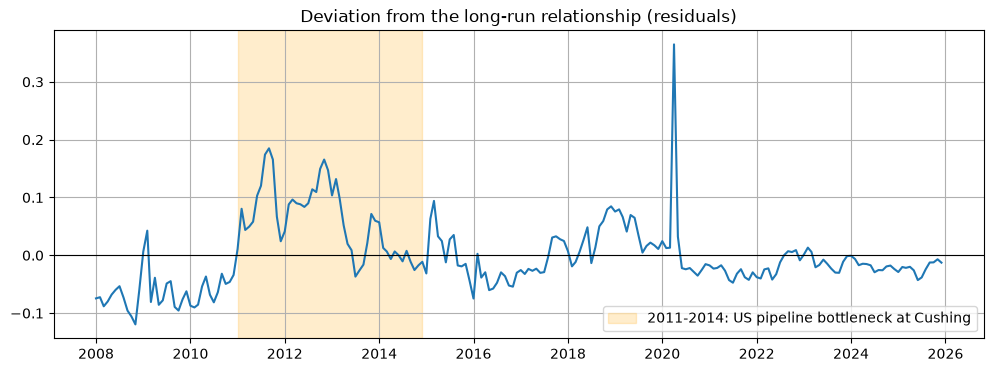

In [33]:
spread = oil_lr.resid

plt.figure(figsize=(12, 4))
plt.plot(spread.index, spread)
plt.axhline(0, color='black', linewidth=0.8)
plt.axvspan(pd.Timestamp('2011-01-01'), pd.Timestamp('2014-12-01'), color='orange', alpha=0.2,
            label='2011-2014: US pipeline bottleneck at Cushing')
plt.title('Deviation from the long-run relationship (residuals)')
plt.legend()
plt.grid(True)
plt.show()

In [34]:
p_eg_oil = coint(ln_oil['brent'], ln_oil['wti'], trend='c')[1]
oil_verdict = "reject" if p_eg_oil < 0.05 else "cannot reject"
print(f"Engle-Granger p-value: {p_eg_oil:.4f} -> {oil_verdict} H0 of no cointegration at 5%")

Engle-Granger p-value: 0.0143 -> reject H0 of no cointegration at 5%


En la gráfica de residuales, entre 2011 y 2014 el spread se alejó mucho de cero por un periodo largo: la producción de EE.UU. creció rápido y no podía llegar a la costa por cuellos de botella en los oleoductos, así que el WTI se abarató mucho frente al Brent. Este tipo de **cambio estructural** hace que la desviación se vea menos estacionaria y reduce el poder de la prueba. Las pruebas estadísticas no reemplazan el conocimiento del negocio.

### Corrección de errores: cómo se cierra la brecha

Si las series están cointegradas, las desviaciones del equilibrio deberían predecir cambios futuros que cierran la brecha. Lo reviso con un **modelo de corrección de errores (ECM)**:

$$\Delta \ln Brent_t = \alpha + \gamma\,\hat u_{t-1} + \delta\,\Delta \ln WTI_t + e_t$$

Si $\gamma<0$, cuando el Brent está por arriba de su equilibrio con el WTI ($\hat u_{t-1}>0$), el Brent tiende a bajar el siguiente periodo y la brecha se cierra.

In [35]:
ecm_df = pd.DataFrame({'d_brent': ln_oil['brent'].diff(),
                       'd_wti': ln_oil['wti'].diff(),
                       'u_lag': spread.shift(1)}).dropna()
ecm = smf.ols('d_brent ~ u_lag + d_wti', data=ecm_df).fit()
gamma = float(ecm.params['u_lag'])
gamma_p = float(ecm.pvalues['u_lag'])
print(ecm.summary().tables[1])
print(f"gamma = {gamma:.3f} (p-value = {gamma_p:.4f}): about {100*abs(gamma):.0f}% of the gap is corrected each month")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0001      0.002     -0.054      0.957      -0.005       0.004
u_lag         -0.1742      0.038     -4.558      0.000      -0.250      -0.099
d_wti          0.7870      0.022     36.603      0.000       0.745       0.829
gamma = -0.174 (p-value = 0.0000): about 17% of the gap is corrected each month


Un $\gamma$ negativo y significativo significa que cada mes se corrige una fracción $|\gamma|$ de la desviación del equilibrio. $\delta$ (coeficiente de `d_wti`) es el efecto de **corto plazo**: en el mismo mes, un cambio de 1% en el WTI se traslada en ~$\delta$% al Brent.

## B.5 Por qué esto importa para IA y machine learning

- **Features espurias.** Dos variables con tendencia siempre están muy correlacionadas. Un modelo que usa una para predecir la otra puede verse excelente dentro de muestra y fallar fuera de muestra. Seleccionar features por correlación es especialmente peligroso con datos con tendencia.
- **Cambio de distribución (*distribution shift*).** Una serie no estacionaria cambia su media (y muchas veces su varianza) con el tiempo. Los datos del periodo de prueba vienen de una distribución distinta a la de entrenamiento, lo cual viola el supuesto básico de la mayoría de modelos de ML.
- **Los modelos de árboles no extrapolan.** Un random forest o gradient boosting predice valores dentro del rango que vio en entrenamiento. Si las ventas siguen creciendo, el modelo predice una línea plana en el máximo de entrenamiento. Modelar tasas de crecimiento (estacionarias) y regresar a niveles lo resuelve.
- **Splits cronológicos.** Train/test y validación cruzada deben respetar el orden del tiempo; revolver los datos filtra información del futuro al entrenamiento.
- **Cointegración = estructura útil.** Cuando las series comparten un equilibrio de largo plazo (precios de sustitutos, precio spot y futuro), la desviación del equilibrio es una feature estacionaria muy poderosa. Es la base del *pairs trading* en finanzas.

---
# CHALLENGE 2 (Parte B)

## 2.1 Experimento de regresión espuria

Extiendo `spurious_rate` para calcular la tasa de rechazo (p < 0.05) para $n$ = 25, 50, 100, 250, 500 y 1000 en tres casos:

- **(a)** dos caminatas aleatorias independientes, en niveles;
- **(b)** las mismas caminatas, en primeras diferencias;
- **(c)** dos AR(1) estacionarios independientes con $\phi_1=0.5$ (con `simulate_ar1`), en niveles.

Uso la misma semilla en los tres casos y 500 repeticiones por cada $n$. Para el caso (c) los shocks tienen desviación estándar 1 y $\phi_0=0$.

      (a) RW levels  (b) RW differences  (c) AR(1) phi=0.5 levels
n                                                                
25            0.504               0.048                     0.128
50            0.700               0.072                     0.150
100           0.746               0.042                     0.114
250           0.854               0.056                     0.148
500           0.884               0.042                     0.116
1000          0.922               0.050                     0.122


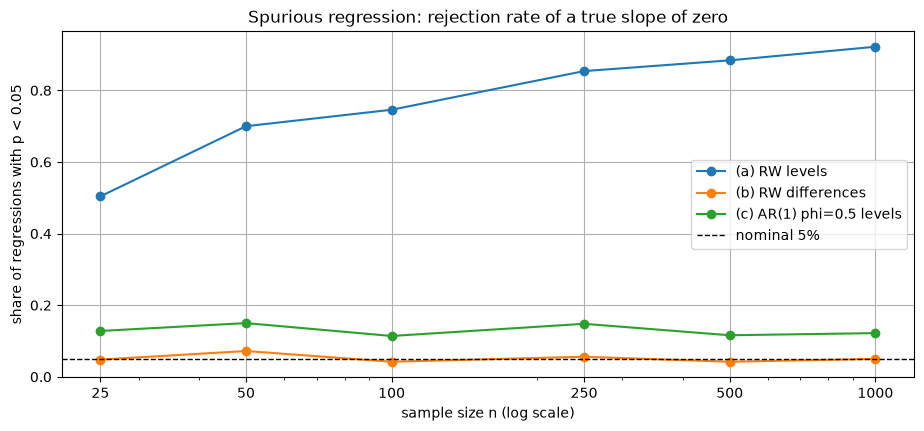

In [36]:
def spurious_rate_ext(n, case='levels', reps=500, seed=0, phi1=0.5):
    """Share of regressions with p<0.05 between two INDEPENDENT series.
    case = 'levels' (random walks), 'differences' (random walks differenced) or 'ar1' (stationary AR(1))."""
    rng = np.random.default_rng(seed)
    count = 0
    for _ in range(reps):
        e_x, e_y = rng.normal(size=n), rng.normal(size=n)
        if case == 'ar1':
            x, y = simulate_ar1(0, phi1, e_x), simulate_ar1(0, phi1, e_y)
        else:
            x, y = np.cumsum(e_x), np.cumsum(e_y)
            if case == 'differences':
                x, y = np.diff(x), np.diff(y)
        p = sm.OLS(y, sm.add_constant(x)).fit().pvalues[1]
        count += p < 0.05
    return count / reps

n_values = [25, 50, 100, 250, 500, 1000]
spur_ext = pd.DataFrame({
    'n': n_values,
    '(a) RW levels': [spurious_rate_ext(k, 'levels') for k in n_values],
    '(b) RW differences': [spurious_rate_ext(k, 'differences') for k in n_values],
    '(c) AR(1) phi=0.5 levels': [spurious_rate_ext(k, 'ar1') for k in n_values],
}).set_index('n')
print(spur_ext)

ax = spur_ext.plot(marker='o', figsize=(11, 4.5), logx=True)
ax.axhline(0.05, color='black', linestyle='--', linewidth=1, label='nominal 5%')
ax.set_xticks(n_values)
ax.set_xticklabels(n_values)
ax.set_xlabel('sample size n (log scale)')
ax.set_ylabel('share of regressions with p < 0.05')
ax.set_title('Spurious regression: rejection rate of a true slope of zero')
ax.legend()
ax.grid(True)
plt.show()

Para entender por qué el caso (c) se aleja un poco del 5%, también calculo el **Durbin-Watson promedio** de los residuales en cada caso con $n=250$ (una sola corrida rápida de 200 repeticiones):

In [37]:
def avg_dw(n, case, reps=200, seed=1, phi1=0.5):
    rng = np.random.default_rng(seed)
    dws = []
    for _ in range(reps):
        e_x, e_y = rng.normal(size=n), rng.normal(size=n)
        if case == 'ar1':
            x, y = simulate_ar1(0, phi1, e_x), simulate_ar1(0, phi1, e_y)
        else:
            x, y = np.cumsum(e_x), np.cumsum(e_y)
            if case == 'differences':
                x, y = np.diff(x), np.diff(y)
        dws.append(durbin_watson(sm.OLS(y, sm.add_constant(x)).fit().resid))
    return np.mean(dws)

pd.Series({c: avg_dw(250, c) for c in ['levels', 'differences', 'ar1']}, name='mean Durbin-Watson (n=250)').round(3)

levels         0.073
differences    2.011
ar1            1.043
Name: mean Durbin-Watson (n=250), dtype: float64

**Interpretación del Challenge 2.1**

| n | (a) RW en niveles | (b) RW en diferencias | (c) AR(1) en niveles |
|---|---|---|---|
| 25 | 50.4% | 4.8% | 12.8% |
| 1000 | 92.2% | 5.0% | 12.2% |

**¿Por qué (a) empeora con $n$?** Si $y$ y $x$ son caminatas aleatorias independientes, el error de la regresión también es una caminata aleatoria: no estacionario, con varianza que crece con el tiempo. Con más datos, $\hat\beta_1$ **no converge a cero** (converge a una variable aleatoria, porque dos tendencias estocásticas siempre se "parecen" en algún tramo), pero el error estándar de OLS, que supone errores independientes, sí se hace más pequeño como $1/\sqrt{n}$. El estadístico t crece con $\sqrt{n}$, así que la tasa de rechazo se acerca a 100%: más datos *empeoran* el problema. El Durbin-Watson promedio de 0.07 confirma residuales casi como caminata aleatoria.

**¿Por qué (b) funciona?** Las diferencias de una caminata aleatoria son ruido blanco. Los residuales son independientes (DW promedio 2.01) y la prueba rechaza ~5% de las veces, como debe ser.

**¿Por qué (c) es mucho mejor que (a) aunque las series estén autocorrelacionadas?** Las series son **estacionarias**: regresan a su media, así que $\hat\beta_1$ sí converge a 0 cuando crece $n$. Lo único que falla es que la autocorrelación (DW promedio 1.04) hace que el error estándar de OLS sea demasiado pequeño, pero por un **factor constante** que no crece con $n$. Lo puedo calcular: con dos AR(1) independientes con $\phi_x=\phi_y=0.5$, la varianza verdadera de $\hat\beta_1$ es $(1+\phi_x\phi_y)/(1-\phi_x\phi_y)=1.25/0.75=1.67$ veces la que reporta OLS. El estadístico t está inflado por $\sqrt{1.67}=1.29$, así que se rechaza cuando $|Z|>1.96/1.29=1.52$, lo cual pasa $\approx 12.9\%$ de las veces. Es casi exactamente lo que da la simulación (11–15% para todo $n$). La distorsión es moderada y se corrige con errores estándar robustos a autocorrelación (Newey-West). En cambio, la de (a) no tiene arreglo en niveles.

## 2.2 Cointegración con datos reales: gasolina RBOB vs. WTI

Descargo con `get_yahoo` los precios diarios del futuro de gasolina RBOB (`RB=F`, dólares por galón) y del WTI (`CL=F`, dólares por barril) de 2006-01-01 a 2025-12-31 (`end='2026-01-01'` porque `end` no se incluye). Convierto a promedios mensuales y saco logs. Las unidades distintas (galón vs. barril) no importan: con logs, la diferencia de unidades solo cambia la constante de la regresión.

Monthly sample: 2006-01 to 2025-12 (240 months); min WTI monthly avg = 16.70


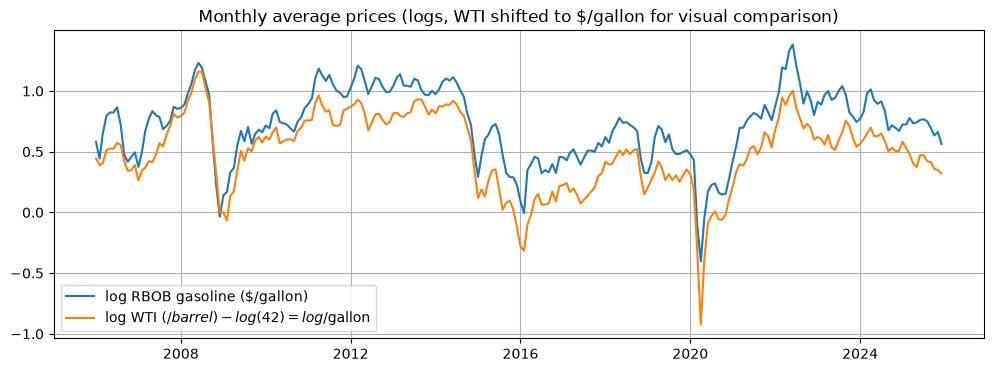

In [38]:
fuel_daily = pd.DataFrame({'gasoline': get_yahoo('RB=F', start='2006-01-01', end='2026-01-01'),
                           'wti': get_yahoo('CL=F', start='2006-01-01', end='2026-01-01')})
fuel = fuel_daily.resample('MS').mean().loc[:'2025-12-01'].dropna()
print(f"Monthly sample: {fuel.index[0]:%Y-%m} to {fuel.index[-1]:%Y-%m} ({len(fuel)} months); min WTI monthly avg = {fuel['wti'].min():.2f}")
ln_fuel = np.log(fuel)

plt.figure(figsize=(12, 4))
plt.plot(ln_fuel.index, ln_fuel['gasoline'], label='log RBOB gasoline ($/gallon)')
plt.plot(ln_fuel.index, ln_fuel['wti'] - np.log(42), label='log WTI ($/barrel) - log(42) = log $/gallon')
plt.title('Monthly average prices (logs, WTI shifted to $/gallon for visual comparison)')
plt.legend()
plt.grid(True)
plt.show()

### a) ¿Ambas series son I(1)?

Una serie es I(1) si la ADF **no rechaza** en niveles pero **sí rechaza** en primeras diferencias. Los precios del petróleo no tienen una tendencia lineal clara en 2006–2025 (suben y bajan), así que uso `'c'` en niveles como en clase; por robustez también reporto `'ct'`, y agrego la KPSS en niveles como prueba cruzada.

In [39]:
def i1_table(df_log, cols):
    out = {}
    for c in cols:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            kpss_lvl = kpss(df_log[c].dropna(), regression='c', nlags='auto')[1]
        out[c] = {'ADF level (c)': adf_test(df_log[c], 'c')['p-value'],
                  'ADF level (ct)': adf_test(df_log[c], 'ct')['p-value'],
                  'KPSS level (c)': kpss_lvl,
                  'ADF 1st diff (c)': adf_test(df_log[c].diff(), 'c')['p-value']}
    return pd.DataFrame(out).T.round(4)

fuel_i1 = i1_table(ln_fuel, ['gasoline', 'wti'])
fuel_i1

,ADF level (c),ADF level (ct),KPSS level (c),ADF 1st diff (c)
gasoline,0.0010,0.0058,0.1,0.0
wti,0.0062,0.0223,0.1,0.0


**Interpretación: ¿son I(1)?**

Las primeras diferencias son claramente estacionarias (p = 0.000 para las dos). Pero **en niveles, en esta muestra, las pruebas no apoyan una raíz unitaria**: la ADF rechaza para la gasolina (p = 0.001 con `'c'`, 0.006 con `'ct'`) y para el WTI (p = 0.006 y 0.022), y la KPSS tampoco rechaza la estacionariedad (p = 0.10). Es el mismo resultado que en el ejemplo de clase con WTI y Brent (p = 0.02 y 0.04 en niveles).

Mi lectura: en 2006–2025 los precios tuvieron varios ciclos grandes (2008, 2014–2016, 2020 y 2022) alrededor de un rango parecido (~40–100 dólares el barril), y en una ventana de 20 años eso parece reversión a la media. La teoría económica dice que los precios de commodities no tienen una media fija de largo plazo (los costos de producción, la tecnología y la demanda cambian), así que sigo el enfoque del workshop y los trato como **I(1)**, aclarando que la evidencia estadística de eso es débil en esta muestra. En la práctica, la conclusión de abajo no cambia: si las series fueran I(0), la regresión en niveles tampoco sería espuria.

### b) Prueba de Engle-Granger

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -3.0678      0.084    -36.623      0.000      -3.233      -2.903
wti            0.8948      0.020     45.349      0.000       0.856       0.934
R-squared = 0.896, Durbin-Watson = 0.373

Engle-Granger: stat = -1.849, p-value = 0.6057, critical values (1%, 5%, 10%) = [-3.943 -3.362 -3.062]


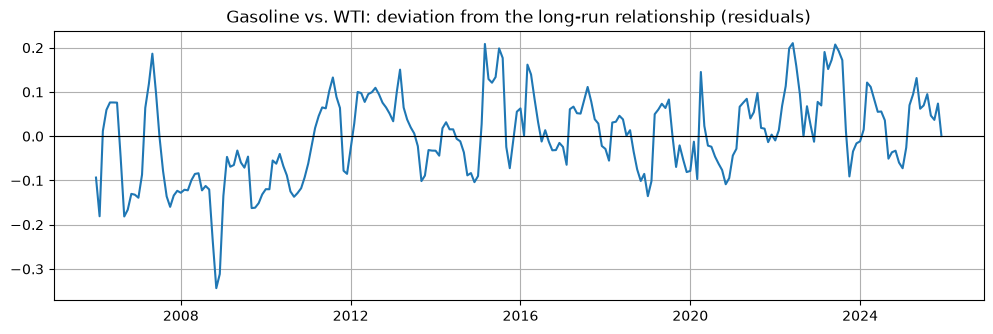

In [40]:
fuel_lr = smf.ols('gasoline ~ wti', data=ln_fuel).fit()
print(fuel_lr.summary().tables[1])
print(f"R-squared = {fuel_lr.rsquared:.3f}, Durbin-Watson = {durbin_watson(fuel_lr.resid):.3f}")

eg_fuel_stat, p_eg_fuel, eg_fuel_crit = coint(ln_fuel['gasoline'], ln_fuel['wti'], trend='c')
print(f"\nEngle-Granger: stat = {eg_fuel_stat:.3f}, p-value = {p_eg_fuel:.4f}, "
      f"critical values (1%, 5%, 10%) = {np.round(eg_fuel_crit, 3)}")

fuel_spread = fuel_lr.resid
plt.figure(figsize=(12, 3.5))
plt.plot(fuel_spread.index, fuel_spread)
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Gasoline vs. WTI: deviation from the long-run relationship (residuals)')
plt.grid(True)
plt.show()

**Prueba de robustez.** El spread tiene un patrón que se repite cada año. Calculo el spread promedio por mes del año y repito Engle-Granger cambiando el criterio para elegir los lags de la regresión ADF de los residuales (AIC, que es el default, vs. BIC, que penaliza más los lags):

In [41]:
print('Average spread (residual) by month of the year:')
print(fuel_spread.groupby(fuel_spread.index.month).mean().round(3).to_frame('mean residual').T.to_string())

rows = []
for crit in ['aic', 'bic']:
    stat, pval, _ = coint(ln_fuel['gasoline'], ln_fuel['wti'], trend='c', autolag=crit)
    lags = adfuller(fuel_spread, regression='c', autolag=crit.upper())[2]
    rows.append({'lag criterion': crit.upper(), 'lags used': lags, 'EG stat': round(stat, 3), 'EG p-value': round(pval, 4)})
pd.DataFrame(rows).set_index('lag criterion')

Average spread (residual) by month of the year:
date              1      2      3      4      5      6      7      8     9      10     11     12
mean residual -0.053 -0.033  0.052  0.066  0.069  0.051  0.043  0.028 -0.04 -0.057 -0.063 -0.064


,lags used,EG stat,EG p-value
lag criterion,,,
AIC,10,-1.849,0.6057
BIC,1,-6.025,0.0000


**Interpretación: ¿están cointegradas?**

- La regresión de largo plazo da una elasticidad de **0.895**: un WTI 1% más caro va con una gasolina ~0.9% más cara en el largo plazo. La constante (-3.07) absorbe la diferencia de unidades ($\ln 42 = 3.74$, porque un barril tiene 42 galones) y el margen de refinación.
- Con la especificación default (lags elegidos por AIC), Engle-Granger **no rechaza** la hipótesis nula de no cointegración: estadístico -1.85 contra un valor crítico de -3.36 al 5%, p = 0.61.
- Pero el resultado depende de cuántos lags se usan. El spread tiene una **estacionalidad muy marcada**: la gasolina es ~5–7% más cara de marzo a agosto (la gasolina de verano tiene otra especificación y hay más demanda) y ~5–6% más barata de octubre a diciembre. Para "absorber" ese patrón, el AIC elige 10 lags, y con tantos lags la prueba pierde mucho poder. Con BIC (1 lag) el estadístico es -6.0 y el p-value ≈ 0.000: se rechaza con claridad la no cointegración. Además, en la gráfica del spread se ven episodios largos fuera de cero (2008, y 2011–2014, cuando el WTI estaba barato por el cuello de botella de Cushing que vimos en clase), que también le quitan poder a la prueba.

**Conclusión:** con la evidencia en conjunto (BIC, el ECM de abajo y la lógica económica) concluyo que **gasolina y WTI sí están cointegradas**. La gasolina se refina del crudo, y si el margen de refinación (*crack spread*) se vuelve muy alto o muy bajo, las refinerías ajustan su producción y el margen regresa. El p-value de 0.61 con AIC es un problema de poder de la prueba (por la estacionalidad del spread), no evidencia de que no haya equilibrio.

### c) Modelo de corrección de errores para la gasolina

$$\Delta \ln Gas_t = \alpha + \gamma\,\hat u_{t-1} + \delta\,\Delta \ln WTI_t + e_t$$

Vida media de una desviación: cada mes queda una fracción $(1+\gamma)$ de la desviación, así que $k_{1/2}=\ln(0.5)/\ln(1+\hat\gamma)$.

In [42]:
ecm_fuel_df = pd.DataFrame({'d_gas': ln_fuel['gasoline'].diff(),
                            'd_wti': ln_fuel['wti'].diff(),
                            'u_lag': fuel_spread.shift(1)}).dropna()
ecm_fuel = smf.ols('d_gas ~ u_lag + d_wti', data=ecm_fuel_df).fit()
print(ecm_fuel.summary().tables[1])
gamma_fuel = float(ecm_fuel.params['u_lag'])
gamma_fuel_p = float(ecm_fuel.pvalues['u_lag'])
hl_fuel = np.log(0.5) / np.log(1 + gamma_fuel)
print(f"\ngamma = {gamma_fuel:.4f} (p-value = {gamma_fuel_p:.4f}); delta = {ecm_fuel.params['d_wti']:.4f}")
print(f"Half-life of a deviation = ln(0.5)/ln(1+gamma) = {hl_fuel:.2f} months")
print(f"Durbin-Watson of the ECM residuals = {durbin_watson(ecm_fuel.resid):.3f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0004      0.004      0.106      0.916      -0.007       0.007
u_lag         -0.1849      0.038     -4.834      0.000      -0.260      -0.110
d_wti          0.8740      0.035     25.216      0.000       0.806       0.942

gamma = -0.1849 (p-value = 0.0000); delta = 0.8740
Half-life of a deviation = ln(0.5)/ln(1+gamma) = 3.39 months
Durbin-Watson of the ECM residuals = 1.634


**Interpretación del modelo de corrección de errores**

- $\hat\gamma = -0.185$ (p ≈ 0): es negativo y significativo, como se espera si hay cointegración. Cuando la gasolina está 10% más cara de lo que su relación de equilibrio con el WTI indica, al mes siguiente tiende a bajar ~1.85% (además del efecto del WTI). Cada mes se corrige ~18.5% de la desviación, una velocidad parecida a la del par Brent–WTI de clase (17%).
- **Vida media de una desviación:** $\ln(0.5)/\ln(1-0.185) = $ **3.4 meses**. La mitad de una brecha entre gasolina y crudo se cierra en poco más de un trimestre.
- $\hat\delta = 0.874$: efecto de corto plazo. En el mismo mes, un cambio de 1% en el WTI se traslada en ~0.87% a la gasolina.
- El estadístico t de $\gamma$ (-4.8) es otra forma de probar cointegración (si no hubiera equilibrio, $\gamma$ sería cero) y apoya la conclusión anterior. Una parte de esa corrección viene de la estacionalidad (el sobreprecio de verano desaparece en otoño), así que para un modelo de pronóstico agregaría variables dummy de mes.

## 2.3 Un par que no debería estar cointegrado: WTI vs. tasa del bono del Tesoro a 10 años

Uso el log del WTI (promedio mensual) y la tasa del bono a 10 años de EE.UU. (`^TNX`, en %, promedio mensual) de 2006 a 2025. La tasa la dejo en **nivel (%)**, porque ya es una tasa (no tiene sentido económico sacarle log y además en 2020 estuvo cerca de 0.5%).

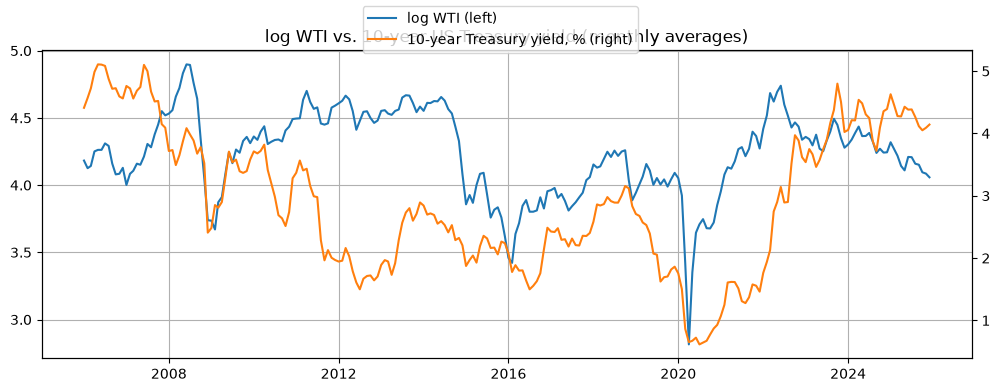

Unit-root tests:
        ADF level (c)  ADF level (ct)  KPSS level (c)  ADF 1st diff (c)
ln_wti         0.0062          0.0223          0.1000               0.0
tnx            0.2466          0.7372          0.0497               0.0


In [43]:
tnx_daily = get_yahoo('^TNX', start='2006-01-01', end='2026-01-01')
wti_tnx = pd.DataFrame({'ln_wti': ln_fuel['wti'],
                        'tnx': tnx_daily.resample('MS').mean()}).loc['2006-01-01':'2025-12-01'].dropna()

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(wti_tnx.index, wti_tnx['ln_wti'], color='tab:blue', label='log WTI (left)')
ax2 = ax1.twinx()
ax2.plot(wti_tnx.index, wti_tnx['tnx'], color='tab:orange', label='10-year Treasury yield, % (right)')
ax1.set_title('log WTI vs. 10-year US Treasury yield (monthly averages)')
fig.legend(loc='upper center')
ax1.grid(True)
plt.show()

print("Unit-root tests:")
print(i1_table(wti_tnx, ['ln_wti', 'tnx']))

In [44]:
reg_tnx_lv = smf.ols('ln_wti ~ tnx', data=wti_tnx).fit()
reg_tnx_df = smf.ols('ln_wti ~ tnx', data=wti_tnx.diff().dropna()).fit()
tnx_results = pd.DataFrame({
    'slope': [reg_tnx_lv.params['tnx'], reg_tnx_df.params['tnx']],
    'p-value': [reg_tnx_lv.pvalues['tnx'], reg_tnx_df.pvalues['tnx']],
    'R-squared': [reg_tnx_lv.rsquared, reg_tnx_df.rsquared],
    'Durbin-Watson': [durbin_watson(reg_tnx_lv.resid), durbin_watson(reg_tnx_df.resid)],
}, index=['levels', 'differences']).round(4)
print(tnx_results)

eg_tnx_stat, p_eg_tnx, eg_tnx_crit = coint(wti_tnx['ln_wti'], wti_tnx['tnx'], trend='c')
print(f"\nEngle-Granger (log WTI on TNX): stat = {eg_tnx_stat:.3f}, p-value = {p_eg_tnx:.4f}")
p_eg_tnx_rev = coint(wti_tnx['tnx'], wti_tnx['ln_wti'], trend='c')[1]
print(f"Engle-Granger (TNX on log WTI): p-value = {p_eg_tnx_rev:.4f}")

              slope  p-value  R-squared  Durbin-Watson
levels       0.0946      0.0     0.1142         0.1129
differences  0.1984      0.0     0.1567         1.6118

Engle-Granger (log WTI on TNX): stat = -3.435, p-value = 0.0386
Engle-Granger (TNX on log WTI): p-value = 0.5979


**Interpretación del Challenge 2.3: WTI vs. bono a 10 años**

- **Orden de integración:** la tasa del bono es claramente **I(1)**: la ADF no rechaza en niveles (p = 0.25 con `'c'` y 0.74 con `'ct'`), la KPSS rechaza la estacionariedad (p = 0.0497) y en diferencias es estacionaria. El log del WTI, como vimos arriba, se ve estacionario en esta ventana (ADF p = 0.006).
- **Engle-Granger da resultados contradictorios según la dirección:** con log WTI como variable dependiente p = 0.039 (rechazaría la no cointegración), pero con la tasa como dependiente p = 0.60. La prueba no es simétrica. En la primera dirección la pendiente es muy pequeña (R² = 0.11), así que el residual es prácticamente el log del WTI sin su media, y como en esta muestra el WTI ya "parece" estacionario, la prueba rechaza. Eso **no es cointegración**: dos series solo pueden estar cointegradas si **las dos** son I(1). Una serie I(0) y una I(1) no pueden tener una combinación lineal estacionaria (cualquier combinación con peso en la tasa del bono hereda su raíz unitaria). Por eso la dirección correcta es la que normaliza sobre la serie I(1), y ahí no hay cointegración (p = 0.60).
- **Regresión en niveles:** pendiente 0.095, p ≈ 0, pero R² = 0.114 apenas mayor que el Durbin-Watson = 0.113. Es la señal clásica de regresión espuria: residuales extremadamente autocorrelacionados y un p-value que no se puede creer.
- **Regresión en diferencias:** pendiente 0.198, p ≈ 0, R² = 0.157 y DW = 1.61 (residuales razonables). Esta relación sí es válida, pero es de **corto plazo**: en los meses en que la tasa sube 0.10 puntos (10 pb), el WTI sube ~2% en promedio. Las dos variables reaccionan a las mismas noticias sobre crecimiento e inflación en EE.UU.

**Conclusión:** la regresión en niveles **es espuria**. No hay cointegración (no hay un equilibrio de largo plazo ni un mecanismo de arbitraje que una el precio del petróleo con la tasa del bono, a diferencia de gasolina y crudo), y lo que existe es un comovimiento de corto plazo que solo se debe modelar en diferencias.

---
# PARTE C. Modelos ARIMA: los bloques de construcción

Importo las herramientas adicionales de esta parte:

In [45]:
import os
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.stattools import pacf
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings('ignore')   # hide convergence warnings while fitting many models

## C.1 La metodología Box-Jenkins

La familia ARIMA/SARIMA la popularizaron Box y Jenkins (1970). La idea es explicar una serie $Y_t$ usando **solo su propio pasado**: sus valores pasados y sus shocks pasados. La metodología es un ciclo iterativo:

1. **Identificación**: encontrar una versión estacionaria de la serie y ver sus autocorrelaciones para proponer un modelo.
2. **Estimación**: estimar los coeficientes.
3. **Diagnóstico**: revisar si los residuales parecen ruido blanco (sin autocorrelación). Si no, regresar al paso 1 y ajustar.
4. **Pronóstico**: usar el modelo final para predecir y evaluar los pronósticos en datos que el modelo no vio.

## C.2 AR(p): la serie depende de sus propios valores pasados

Un modelo autorregresivo de orden $p$ incluye $p$ lags de la serie:

$$Y_t=\phi_0+\phi_1Y_{t-1}+\phi_2Y_{t-2}+\dots+\phi_pY_{t-p}+\varepsilon_t$$

Un shock $\varepsilon_t$ entra a $Y_t$; $Y_t$ entra a $Y_{t+1}$; $Y_{t+1}$ entra a $Y_{t+2}$, etc. El shock nunca se olvida por completo, pero en un AR estacionario su efecto se desvanece geométricamente. Un proceso AR tiene **memoria infinita pero que se desvanece**.

## C.3 MA(q): la serie depende de shocks pasados

Un modelo de promedio móvil de orden $q$ explica $Y_t$ con el shock actual y los últimos $q$ shocks:

$$Y_t=\theta_0+\varepsilon_t+\theta_1\varepsilon_{t-1}+\dots+\theta_q\varepsilon_{t-q}$$

Un shock afecta la serie exactamente $q$ periodos y luego se olvida por completo: un MA tiene **memoria finita de $q$ periodos**. Ejemplo: una promoción inesperada sube las ventas este mes y parcialmente el siguiente, y luego su efecto desaparece.

## C.4 ARMA(p,q), ARIMA(p,d,q) y SARIMA

ARMA(p,q) combina ambos tipos de términos:

$$Y_t=\phi_0+\sum_{k=1}^{p}\phi_kY_{t-k}+\sum_{k=1}^{q}\theta_k\varepsilon_{t-k}+\varepsilon_t$$

ARMA requiere una serie estacionaria. Si hay que diferenciar la serie $d$ veces para hacerla estacionaria, el modelo es **ARIMA(p,d,q)** ("I" = integrado). Con datos mensuales o trimestrales normalmente también se necesitan términos **estacionales** (lags de 12 meses o 4 trimestres y sus múltiplos):

$$\text{SARIMA}(p,d,q)(P,D,Q)_s$$

| Parámetro | Significado |
|---|---|
| $p$ | número de términos AR (lags 1, 2, …, p) |
| $d$ | número de primeras diferencias ($Y_t-Y_{t-1}$) |
| $q$ | número de términos MA (shocks de t-1, …, t-q) |
| $P$ | número de términos AR estacionales (lags s, 2s, …) |
| $D$ | número de diferencias estacionales ($Y_t-Y_{t-s}$) |
| $Q$ | número de términos MA estacionales (shocks de t-s, t-2s, …) |
| $s$ | número de periodos en un año (12 mensual, 4 trimestral) |

Si agregamos variables explicativas externas (X's), el modelo es **ARIMAX / SARIMAX** (por eso la clase de Python se llama `SARIMAX`).

## C.5 Herramientas de identificación: ACF y PACF

### La función de autocorrelación (ACF)

La autocorrelación en el lag $k$ es la correlación entre $Y_t$ y $Y_{t-k}$. Como una serie estacionaria tiene la misma varianza en todo periodo, se simplifica a

$$\rho_k=\frac{Cov(Y_t,Y_{t-k})}{SD(Y_t)\,SD(Y_{t-k})}=\frac{\gamma(k)}{\sigma_Y^2}$$

donde $\gamma(k)$ es la autocovarianza en el lag $k$.

### La función de autocorrelación parcial (PACF)

La autocorrelación **parcial** en el lag $k$ mide la relación entre $Y_t$ y $Y_{t-k}$ **después de quitar el efecto de los lags intermedios** $Y_{t-1},\dots,Y_{t-k+1}$. Una forma de calcularla es el coeficiente de $Y_{t-k}$ en la regresión

$$Y_t=\alpha+\beta_1Y_{t-1}+\dots+\beta_kY_{t-k}+e_t \qquad\Rightarrow\qquad PACF(k)=\hat\beta_k$$

Lo compruebo con un AR(1) simulado. En un AR(1), $Y_{t-2}$ afecta a $Y_t$ solo a través de $Y_{t-1}$, así que la PACF en el lag 2 debería ser ~0, mientras la ACF en el lag 2 no:

In [46]:
rng_seed = 42
ar1 = ArmaProcess(ar=[1, -0.7], ma=[1]).generate_sample(nsample=500, distrvs=np.random.default_rng(rng_seed).standard_normal)
ar1 = pd.Series(ar1)

lags_df = pd.DataFrame({'y': ar1, 'lag1': ar1.shift(1), 'lag2': ar1.shift(2)}).dropna()
beta2 = sm.OLS(lags_df['y'], sm.add_constant(lags_df[['lag1', 'lag2']])).fit().params['lag2']

print(f"ACF at lag 2:                       {ar1.autocorr(2):.3f}   (theory: 0.7^2 = 0.49)")
print(f"PACF at lag 2 (statsmodels):        {pacf(ar1, nlags=2, method='ols')[2]:.3f}")
print(f"PACF at lag 2 (regression coefficient): {beta2:.3f}")

ACF at lag 2:                       0.459   (theory: 0.7^2 = 0.49)
PACF at lag 2 (statsmodels):        -0.112
PACF at lag 2 (regression coefficient): -0.112


Nota: `ArmaProcess` escribe el polinomio AR como $1-\phi_1L$, así que $\phi_1=0.7$ se pone como `ar=[1, -0.7]`. El polinomio MA es $1+\theta_1L$, así que $\theta_1$ se pone con su propio signo: `ma=[1, θ1]`.

### Patrones (firmas) de procesos AR, MA y ARMA

Simulo cuatro procesos cuyo modelo verdadero conozco y veo su ACF y PACF:

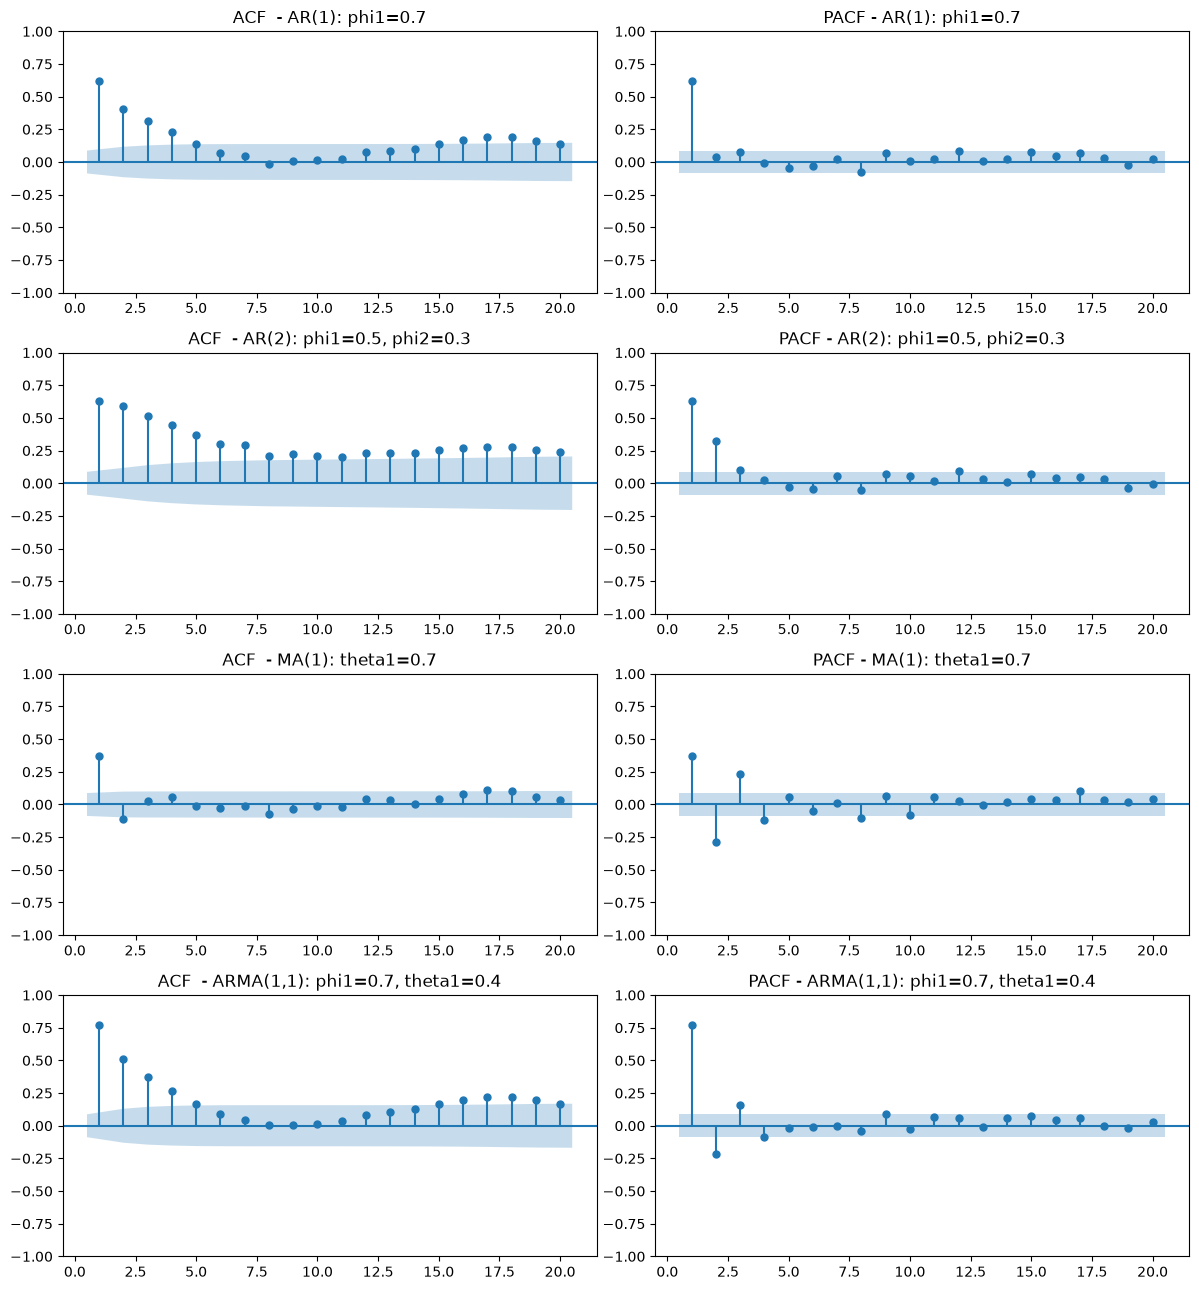

In [47]:
processes = {
    'AR(1): phi1=0.7':           ArmaProcess(ar=[1, -0.7], ma=[1]),
    'AR(2): phi1=0.5, phi2=0.3': ArmaProcess(ar=[1, -0.5, -0.3], ma=[1]),
    'MA(1): theta1=0.7':         ArmaProcess(ar=[1], ma=[1, 0.7]),
    'ARMA(1,1): phi1=0.7, theta1=0.4': ArmaProcess(ar=[1, -0.7], ma=[1, 0.4]),
}
sim_series = {name: proc.generate_sample(nsample=500, distrvs=np.random.default_rng(1).standard_normal)
              for name, proc in processes.items()}

fig, axes = plt.subplots(4, 2, figsize=(12, 13))
for i, (name, y) in enumerate(sim_series.items()):
    plot_acf(y, lags=20, zero=False, ax=axes[i, 0], title=f'ACF  - {name}')
    plot_pacf(y, lags=20, zero=False, ax=axes[i, 1], title=f'PACF - {name}', method='ywm')
plt.tight_layout()
plt.show()

El área sombreada es la banda de confianza al 95%. Los patrones son:

| Modelo verdadero | ACF | PACF |
|---|---|---|
| AR(p) | decae gradualmente | se corta después del lag p |
| MA(q) | se corta después del lag q | decae gradualmente (muchas veces alternando signo) |
| ARMA(p,q) | decae gradualmente | decae gradualmente |

Así que **la PACF sugiere $p$ y la ACF sugiere $q$**. Con datos reales los patrones son más ruidosos, así que estas reglas dan un punto de partida, no la respuesta final.

### Ejercicio en clase: identificar las series misteriosas

Corro el siguiente bloque sin ver los parámetros (están "escondidos" en una lista), veo la ACF y PACF de cada serie y propongo un modelo:

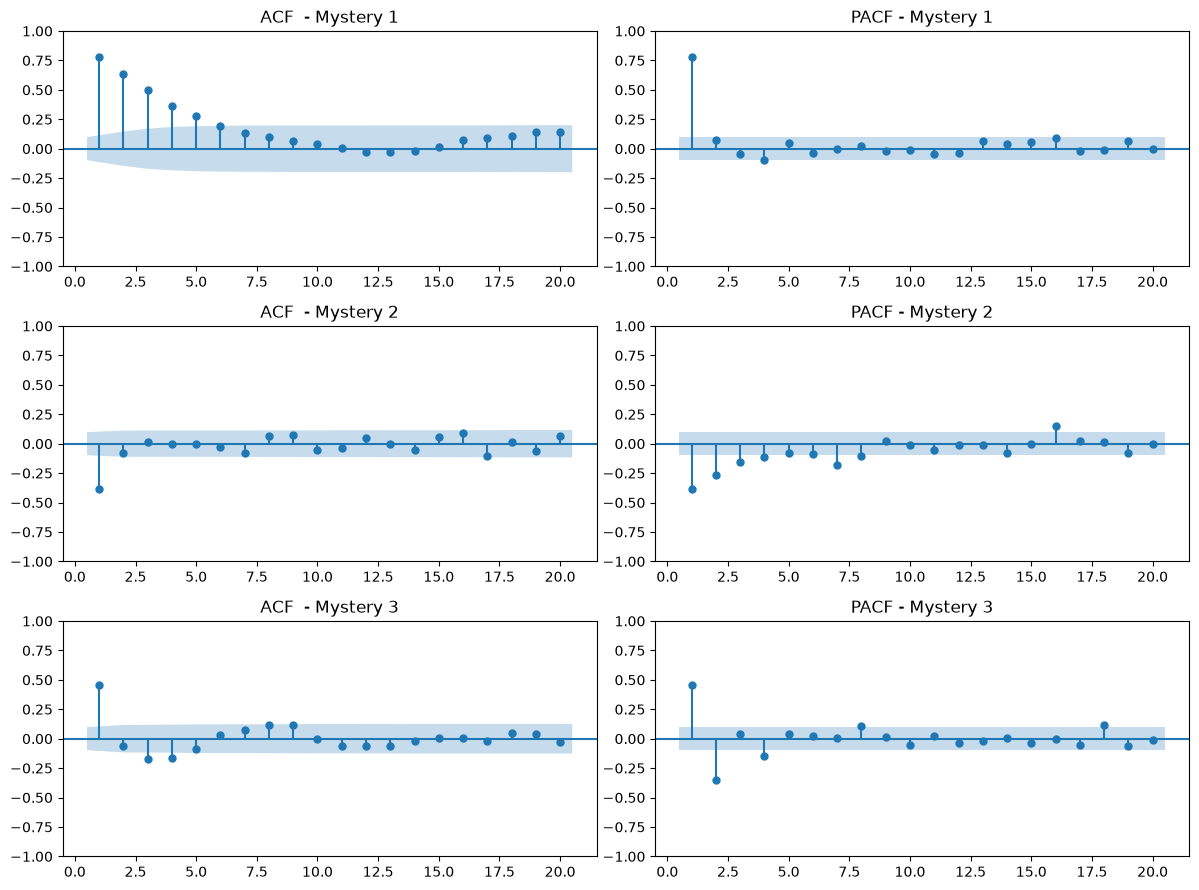

In [48]:
_secret = [([1, -0.8], [1]), ([1], [1, -0.6]), ([1, -0.6, 0.3], [1])]
mystery = {f'Mystery {k+1}': ArmaProcess(*_secret[k]).generate_sample(400, distrvs=np.random.default_rng(100 + k).standard_normal)
           for k in range(3)}

fig, axes = plt.subplots(3, 2, figsize=(12, 9))
for i, (name, y) in enumerate(mystery.items()):
    plot_acf(y, lags=20, zero=False, ax=axes[i, 0], title=f'ACF  - {name}')
    plot_pacf(y, lags=20, zero=False, ax=axes[i, 1], title=f'PACF - {name}', method='ywm')
plt.tight_layout()
plt.show()

Ahora estimo el modelo propuesto para cada serie y reviso si los coeficientes son significativos. El ejemplo del workshop es la serie misteriosa 1 como AR(1):

In [49]:
res_m1 = SARIMAX(mystery['Mystery 1'], order=(1, 0, 0), trend='c').fit(disp=False)
print(res_m1.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -0.0066      0.049     -0.133      0.894      -0.103       0.090
ar.L1          0.7802      0.030     26.397      0.000       0.722       0.838
sigma2         0.9722      0.075     12.976      0.000       0.825       1.119


Mis propuestas para las otras dos series (viendo las gráficas): la **2** tiene una ACF con un solo pico (lag 1, negativo) y una PACF que decae alternando → **MA(1)**. La **3** tiene una PACF con dos picos (lags 1 y 2) y luego se corta, y una ACF que decae → **AR(2)**. Las estimo para confirmar:

In [50]:
res_m2 = SARIMAX(mystery['Mystery 2'], order=(0, 0, 1), trend='c').fit(disp=False)
res_m3 = SARIMAX(mystery['Mystery 3'], order=(2, 0, 0), trend='c').fit(disp=False)
print('Mystery 2 as MA(1):'); print(res_m2.summary().tables[1])
print('Mystery 3 as AR(2):'); print(res_m3.summary().tables[1])

Mystery 2 as MA(1):
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -0.0164      0.016     -0.996      0.319      -0.049       0.016
ma.L1         -0.6765      0.036    -18.613      0.000      -0.748      -0.605
sigma2         1.0135      0.078     12.950      0.000       0.860       1.167
Mystery 3 as AR(2):
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -0.0607      0.053     -1.155      0.248      -0.164       0.042
ar.L1          0.6209      0.043     14.561      0.000       0.537       0.704
ar.L2         -0.3496      0.047     -7.437      0.000      -0.442      -0.257
sigma2         1.0396      0.075     13.931      0.000       0.893       1.186


**Resultado del ejercicio de las series misteriosas**

| Serie | ACF | PACF | Mi propuesta | Estimación |
|---|---|---|---|---|
| Mystery 1 | decae gradualmente | un pico en lag 1 | AR(1) | $\hat\phi_1=0.78$ (p ≈ 0) |
| Mystery 2 | un solo pico negativo en lag 1 | decae | MA(1) | $\hat\theta_1=-0.68$ (p ≈ 0) |
| Mystery 3 | decae oscilando | picos en lags 1 y 2 | AR(2) | $\hat\phi_1=0.62$, $\hat\phi_2=-0.35$ (ambos p ≈ 0) |

Los parámetros verdaderos (en `_secret`) son $\phi_1=0.8$; $\theta_1=-0.6$; y $\phi_1=0.6,\ \phi_2=-0.3$. Las estimaciones quedan cerca y todas son significativas, mientras que las constantes no lo son (la media verdadera es 0). En la serie 3, el $\phi_2$ negativo es lo que hace que la ACF oscile en lugar de decaer suavemente.

Los coeficientes se estiman por **Máxima Verosimilitud (ML)**. A diferencia de OLS, ML no tiene fórmula cerrada para modelos ARMA: el software busca iterativamente los coeficientes que hacen más probable los datos observados. Los términos MA hacen imposible usar OLS porque los shocks pasados $\varepsilon_{t-k}$ no se observan; se infieren junto con los coeficientes.

## C.6 Datos reales: el IGAE de México

El **IGAE** (Indicador Global de la Actividad Económica) lo publica el INEGI cada mes. Mide la actividad económica de México, parecido al PIB, pero es mensual y sale antes que el PIB trimestral. Uso la serie **sin ajuste estacional**, porque quiero modelar la estacionalidad yo mismo.

### Descargar el IGAE con la API del INEGI

El INEGI tiene una API gratuita. Uso el paquete `INEGIpy` (se instala una vez con `pip install INEGIpy==2.0.0`). La API requiere un token; uso el token que el profesor compartió en el workshop (se puede pedir uno propio gratis en la página del INEGI; nunca se debe publicar un token propio en un repositorio público).

Nota: en diciembre 2025 el INEGI cambió el ID del IGAE. El ID `6207136901` es el índice del IGAE (base 2018=100), cifras originales, total de la economía.

In [51]:
# pip install INEGIpy==2.0.0
from INEGIpy import Indicadores

# Token shared by the professor in the workshop:
TOKEN = 'c4559227-83d3-aeb4-1a8d-bee73f627140'
inegi = Indicadores(TOKEN)

# IGAE mensual: Índice base 2018=100, cifras originales, Total
# (INEGI changed this ID in Dec 2025)
IGAE_ID = "6207136901"
igaedf = inegi.obtener_df(indicadores=IGAE_ID, nombres="IGAE")

`obtener_df` regresa un data frame con las fechas como índice y una columna `IGAE`. Me aseguro de que el índice sea tipo fecha, que cada fecha sea el primer día del mes y que los valores sean numéricos:

In [52]:
igaedf.index = pd.to_datetime(igaedf.index)
igaedf.index = igaedf.index.to_period('M').to_timestamp()   # first day of each month
igaedf = igaedf[['IGAE']].apply(pd.to_numeric, errors='coerce')
igaedf = igaedf.sort_index().asfreq('MS')
igaedf['logIGAE'] = np.log(igaedf['IGAE'])
igaedf.tail()

,IGAE,logIGAE
fechas,,
2026-04-01,106.613699,4.669212
2026-05-01,108.549177,4.687203
2026-06-01,107.390831,4.676475
2026-07-01,109.262414,4.693752
2026-08-01,108.317094,4.685063


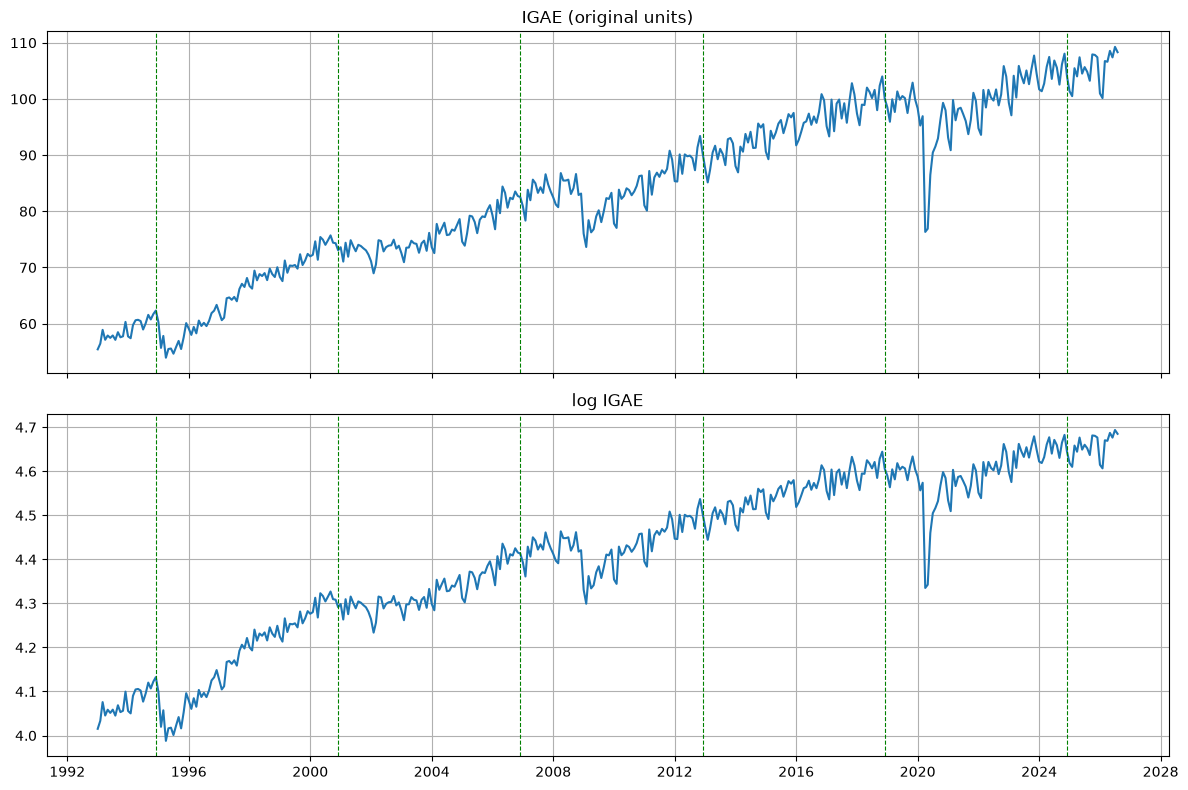

In [53]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(igaedf.index, igaedf['IGAE'])
axes[0].set_title('IGAE (original units)')
axes[1].plot(igaedf.index, igaedf['logIGAE'])
axes[1].set_title('log IGAE')
for ax in axes:
    for year in [1994, 2000, 2006, 2012, 2018, 2024]:
        ax.axvline(pd.Timestamp(f'{year}-12-01'), color='green', linestyle='--', linewidth=0.8)
    ax.grid(True)
plt.tight_layout()
plt.show()

Las líneas verdes marcan el inicio de cada sexenio. Se ve una **tendencia creciente**, una **estacionalidad fuerte** y las crisis de 1995, 2009 y 2020. En escala log, distancias verticales iguales son cambios % iguales, así que la gráfica en log es la correcta para comparar la profundidad de crisis de distintas décadas.

¿Qué tan profunda fue la crisis del COVID? Como los datos no tienen ajuste estacional, comparo cada mes con el mismo mes del año anterior (cambio % anual):

In [54]:
annual_log_change = igaedf['logIGAE'].diff(12)
worst_month = annual_log_change.idxmin()
worst_log = float(annual_log_change.min())
worst_simple = float(np.exp(worst_log) - 1)
worst_label = worst_month.strftime('%B %Y')
print(f"Worst annual change: {worst_label}: log difference = {worst_log:.3f}, simple % change = {100*worst_simple:.1f}%")

Worst annual change: May 2020: log difference = -0.276, simple % change = -24.1%


El peor mes fue mayo 2020. Como vimos en la Parte A, el cambio en log y el cambio % simple solo son parecidos para cambios pequeños: aquí difieren por varios puntos.

### Paso 1 – Identificación: encontrar una versión estacionaria

Para series económicas mensuales empiezo con la **diferencia estacional del log** (cambio % anual), porque quita tanto la tendencia como la estacionalidad. La comparo con el log-nivel usando la ADF:

ADF p-value, log level (ct):     0.2475
ADF p-value, annual growth (c):  0.0011  -> stationary


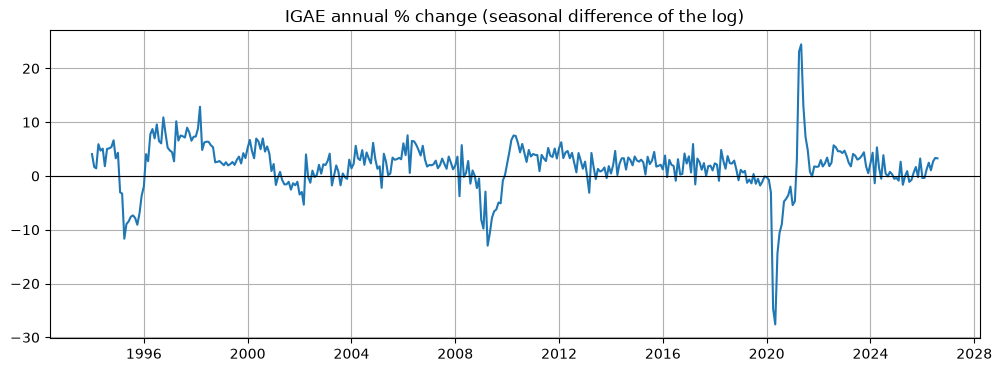

In [55]:
igaedf['annualgrowth'] = igaedf['logIGAE'].diff(12)

p_adf_level = adf_test(igaedf['logIGAE'], 'ct')['p-value']        # adf_test was defined in Part A
p_adf_annual = adf_test(igaedf['annualgrowth'], 'c')['p-value']
igae_stationary = "stationary" if p_adf_annual < 0.05 else "NOT stationary (consider an additional first difference, d=1)"
print(f"ADF p-value, log level (ct):     {p_adf_level:.4f}")
print(f"ADF p-value, annual growth (c):  {p_adf_annual:.4f}  -> {igae_stationary}")

plt.figure(figsize=(12, 4))
plt.plot(igaedf.index, 100 * igaedf['annualgrowth'])
plt.axhline(0, color='black', linewidth=0.8)
plt.title('IGAE annual % change (seasonal difference of the log)')
plt.grid(True)
plt.show()

El log-nivel no es estacionario y el crecimiento anual sí. Esto define los parámetros de diferenciación: modelo el **log del IGAE** con una diferencia estacional y sin primera diferencia:

$$d=0,\qquad D=1,\qquad s=12$$

### Paso 1 (cont.) – ACF y PACF de la serie estacionaria

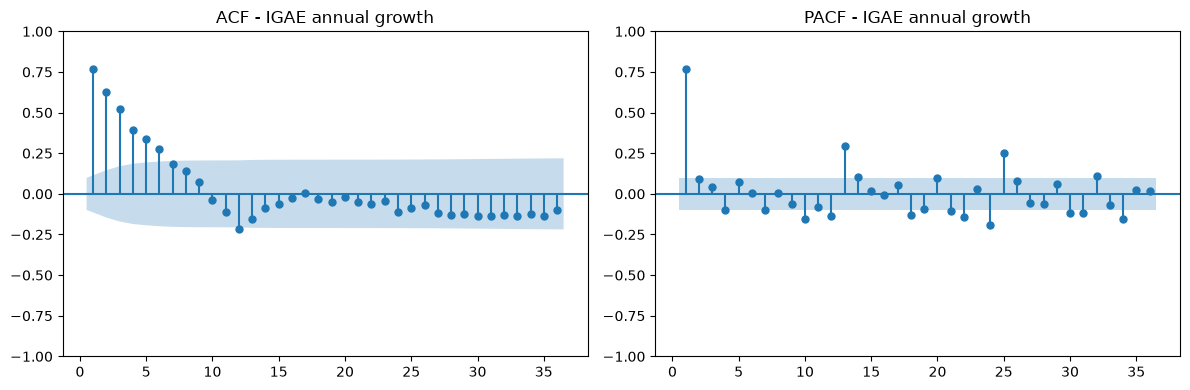

Lag-1 autocorrelation = 0.77; consecutive significant PACF lags from lag 1 = 1


In [56]:
ag = igaedf['annualgrowth'].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(ag, lags=36, zero=False, ax=axes[0], title='ACF - IGAE annual growth')
plot_pacf(ag, lags=36, zero=False, ax=axes[1], title='PACF - IGAE annual growth', method='ywm')
plt.tight_layout()
plt.show()

acf1 = float(ag.autocorr(1))
pacf_vals, pacf_ci = pacf(ag, nlags=24, alpha=0.05, method='ywm')
signif = (pacf_ci[:, 0] > 0) | (pacf_ci[:, 1] < 0)
# number of consecutive significant PACF lags starting at lag 1:
p_suggest = int(np.argmin(signif[1:])) if not signif[1:].all() else 24
print(f"Lag-1 autocorrelation = {acf1:.2f}; consecutive significant PACF lags from lag 1 = {p_suggest}")

La ACF decae lento desde una autocorrelación alta en el lag 1: el crecimiento anual es **muy persistente** (si la economía crece más rápido que hace un año este mes, probablemente también el siguiente). La PACF tiene pocos picos significativos al inicio y luego cae cerca de cero. Es una **firma AR**, así que empiezo con $p$ pequeño y sin términos MA. Como primer modelo simple uso $p=1$ y dejo que los diagnósticos digan qué falta.

---
# PARTE D. Construir y evaluar un modelo SARIMA

## D.1 Split train / test

Para evaluar los pronósticos de forma honesta escondo los **últimos 24 meses** y los uso solo al final. El split debe ser **cronológico**: un split aleatorio dejaría que el modelo "vea el futuro".

In [57]:
igae_log = igaedf['logIGAE'].dropna()
h_test = 24
train = igae_log.iloc[:-h_test]
test = igae_log.iloc[-h_test:]
print(f"Training: {train.index[0]:%Y-%m} to {train.index[-1]:%Y-%m} ({len(train)} months)")
print(f"Test:     {test.index[0]:%Y-%m} to {test.index[-1]:%Y-%m} ({len(test)} months)")

Training: 1993-01 to 2024-08 (380 months)
Test:     2024-09 to 2026-08 (24 months)


Dos funciones auxiliares: una para estimar un SARIMA y otra para los diagnósticos.

In [58]:
def fit_sarima(y, order, seasonal_order, trend='c', exog=None):
    """Fit a SARIMA(X) model by maximum likelihood."""
    return SARIMAX(y, order=order, seasonal_order=seasonal_order,
                   trend=trend, exog=exog).fit(disp=False)

def diagnose(res, name, plots=True):
    """Coefficient table, Ljung-Box test on residuals and AIC; residual ACF/PACF plots."""
    s = res.model.seasonal_periods or 1
    burn = res.model.k_diff + s * res.model.k_seasonal_diff + 1   # drop the first residuals (initialization)
    resid = res.resid.iloc[burn:]
    m = res.model
    k = m.k_ar_params + m.k_ma_params + m.k_seasonal_ar_params + m.k_seasonal_ma_params   # number of ARMA terms
    lb = acorr_ljungbox(resid, lags=[12, 24], model_df=max(k, 0))
    coefs = pd.DataFrame({'coef': res.params, 'p-value': res.pvalues}).drop('sigma2').round(4)
    print(f"===== {name} =====")
    print(coefs)
    print(f"Ljung-Box p-value (lag 12): {lb['lb_pvalue'].iloc[0]:.4f} | (lag 24): {lb['lb_pvalue'].iloc[1]:.4f}")
    print(f"AIC = {res.aic:.2f}")
    if plots:
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
        plot_acf(resid, lags=36, zero=False, ax=axes[0], title=f'Residual ACF - {name}')
        plot_pacf(resid, lags=36, zero=False, ax=axes[1], title=f'Residual PACF - {name}', method='ywm')
        plt.tight_layout()
        plt.show()
    return resid, lb

La prueba **Ljung-Box** revisa si un grupo de autocorrelaciones de los residuales es conjuntamente cero. $H_0$: los residuales son ruido blanco (no queda autocorrelación). Queremos un **p-value alto** (> 0.05). Un p-value bajo significa que el modelo deja estructura predecible en los errores.

## D.2 Pasos 2 y 3 – Estimación y diagnóstico: calibrar el modelo

### Modelo 1: SARIMA(1,0,0)(0,1,0)$_{12}$

===== Model 1: (1,0,0)(0,1,0,12) =====
             coef  p-value
intercept  0.0045    0.004
ar.L1      0.7693    0.000
Ljung-Box p-value (lag 12): 0.0000 | (lag 24): 0.0000
AIC = -1536.81


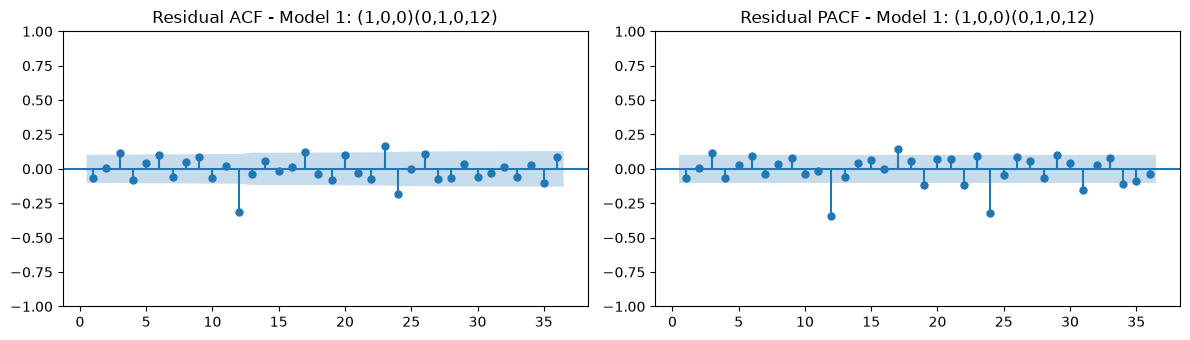

Residual autocorrelation at lag 12: -0.32


In [59]:
res1 = fit_sarima(train, (1, 0, 0), (0, 1, 0, 12))
resid1, lb1 = diagnose(res1, 'Model 1: (1,0,0)(0,1,0,12)')
res1_acf12 = float(resid1.autocorr(12))
print(f"Residual autocorrelation at lag 12: {res1_acf12:.2f}")

El coeficiente AR(1) es significativo. Pero en los residuales la autocorrelación en el lag 12 es claramente negativa. Un pico negativo significativo en el **lag estacional** después de una diferencia estacional es la señal clásica de un **MA estacional ($Q=1$)**: la diferencia estacional "sobrecorrige" y parte del shock de hace 12 meses se deshace este año.

### Modelo 2: SARIMA(1,0,0)(0,1,1)$_{12}$

===== Model 2: (1,0,0)(0,1,1,12) =====
             coef  p-value
intercept  0.0026      0.0
ar.L1      0.8605      0.0
ma.S.L12  -0.8232      0.0
Ljung-Box p-value (lag 12): 0.0000 | (lag 24): 0.0000
AIC = -1656.18


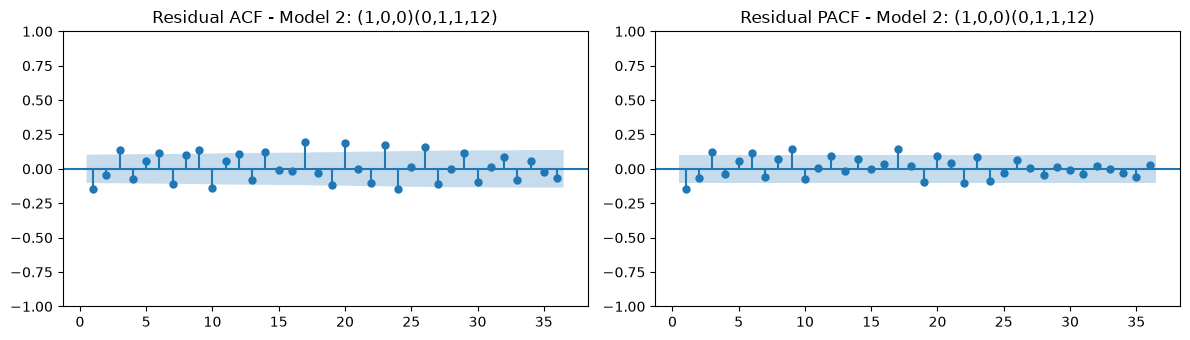

Residual autocorrelation at lag 1: -0.15


In [60]:
res2 = fit_sarima(train, (1, 0, 0), (0, 1, 1, 12))
resid2, lb2 = diagnose(res2, 'Model 2: (1,0,0)(0,1,1,12)')
res2_acf1 = float(resid2.autocorr(1))
print(f"Residual autocorrelation at lag 1: {res2_acf1:.2f}")

El MA estacional es significativo y el pico del lag 12 desaparece; el AIC baja mucho. Ahora queda un pico en el **lag 1** de los residuales. Un pico significativo en el lag 1 (teniendo ya un AR(1)) sugiere agregar un término **MA(1)** ($q=1$).

### Modelo 3: SARIMA(1,0,1)(0,1,1)$_{12}$

===== Model 3: (1,0,1)(0,1,1,12) =====
             coef  p-value
intercept  0.0014   0.0013
ar.L1      0.9268   0.0000
ma.L1     -0.2652   0.0000
ma.S.L12  -0.8324   0.0000
Ljung-Box p-value (lag 12): 0.0006 | (lag 24): 0.0000
AIC = -1669.04


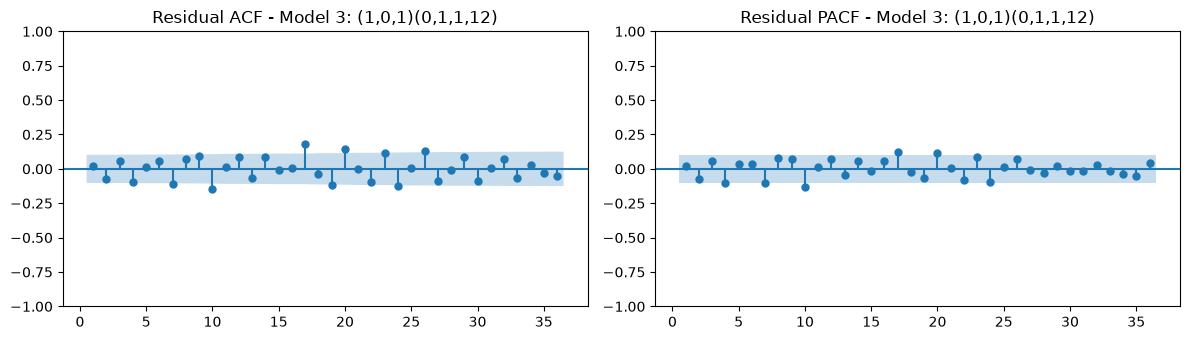

In [61]:
res3 = fit_sarima(train, (1, 0, 1), (0, 1, 1, 12))
resid3, lb3 = diagnose(res3, 'Model 3: (1,0,1)(0,1,1,12)')
lb3_p24 = float(lb3['lb_pvalue'].iloc[1])

Todos los coeficientes son significativos y el AIC vuelve a bajar. Si el p-value de Ljung-Box es mayor a 0.05 no se rechaza que los residuales sean ruido blanco. Aquí sigue siendo bajo: con ~380 meses (incluyendo crisis como 1995, 2009 y sobre todo el COVID de 2020) la prueba detecta cualquier pequeño pico y los *outliers* de 2020 dejan estructura. Uno o dos picos aislados ligeramente fuera de la banda son esperables por azar: con 36 lags y banda al 95%, ~2 picos serán "significativos" incluso con ruido blanco puro.

### Confirmar con un criterio de información (AIC)

Calibrar a mano es buena forma de aprender, pero hay que revisar alternativas de forma sistemática. El **AIC** premia el ajuste pero penaliza el número de parámetros: **menor es mejor**. Estimo todas las combinaciones de órdenes pequeños y las ordeno:

In [62]:
from itertools import product

def sarima_grid(y, d, D, s, max_p=2, max_q=2, max_P=1, max_Q=1, trend='c'):
    """Fit all SARIMA(p,d,q)(P,D,Q,s) combinations up to the given orders; rank by AIC."""
    rows = []
    for p, q, P, Q in product(range(max_p + 1), range(max_q + 1), range(max_P + 1), range(max_Q + 1)):
        try:
            res = fit_sarima(y, (p, d, q), (P, D, Q, s), trend=trend)
            burn = d + s * D + 1
            k = p + q + P + Q
            lb_p = acorr_ljungbox(res.resid.iloc[burn:], lags=[2 * s], model_df=k)['lb_pvalue'].iloc[0]
            rows.append({'order': (p, d, q), 'seasonal': (P, D, Q, s), 'AIC': res.aic,
                         'BIC': res.bic, f'Ljung-Box p (lag {2*s})': lb_p, 'n params': k})
        except Exception:
            pass
    return pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)

grid = sarima_grid(train, d=0, D=1, s=12)
grid.head(8).round(3)

,order,seasonal,AIC,BIC,Ljung-Box p (lag 24),n params
0,"(2, 0, 2)","(1, 1, 1, 12)",-1670.490,-1639.225,0.0,6
1,"(1, 0, 2)","(1, 1, 1, 12)",-1670.218,-1642.862,0.0,5
2,"(1, 0, 1)","(1, 1, 1, 12)",-1670.196,-1646.747,0.0,4
3,"(1, 0, 2)","(0, 1, 1, 12)",-1669.696,-1646.247,0.0,4
4,"(2, 0, 0)","(1, 1, 1, 12)",-1669.250,-1645.802,0.0,4
5,"(1, 0, 1)","(0, 1, 1, 12)",-1669.037,-1649.497,0.0,3
6,"(2, 0, 2)","(0, 1, 1, 12)",-1668.991,-1641.635,0.0,5
7,"(2, 0, 1)","(1, 1, 1, 12)",-1667.687,-1640.331,0.0,5


In [63]:
best_order = grid.loc[0, 'order']
best_seasonal = grid.loc[0, 'seasonal']
best_label = f"SARIMA{best_order}{best_seasonal[:3]}_12"
aic_model3 = float(res3.aic)
aic_best = float(grid.loc[0, 'AIC'])
print(f"Lowest AIC: {best_label} (AIC = {aic_best:.1f}); hand-calibrated Model 3: AIC = {aic_model3:.1f}")

Lowest AIC: SARIMA(2, 0, 2)(1, 1, 1)_12 (AIC = -1670.5); hand-calibrated Model 3: AIC = -1669.0


Cuando dos modelos tienen AIC parecido (diferencia menor a ~2–4 puntos), prefiero el **más simple**, y solo considero modelos cuyos residuales pasen Ljung-Box. Me quedo con el Modelo 3 para interpretar y comparo ambos en el periodo de prueba.

## D.3 Interpretar el modelo

Sea $w_t=\ln IGAE_t-\ln IGAE_{t-12}$ el crecimiento anual. En notación de statsmodels, el Modelo 3 es

$$(1-\phi_1L)\,w_t = c + (1+\theta_1L)(1+\Theta_1L^{12})\,\varepsilon_t$$

donde $L$ es el operador de rezago ($L^kY_t=Y_{t-k}$). Expandiendo el producto de los polinomios MA:

$$w_t=c+\phi_1w_{t-1}+\varepsilon_t+\theta_1\varepsilon_{t-1}+\Theta_1\varepsilon_{t-12}+\theta_1\Theta_1\varepsilon_{t-13}$$

El último término aparece porque los MA regular y estacional se multiplican: por eso se llama modelo estacional **multiplicativo**.

In [64]:
c_hat = float(res3.params['intercept'])
phi1_hat = float(res3.params['ar.L1'])
theta1_hat = float(res3.params['ma.L1'])
Theta1_hat = float(res3.params['ma.S.L12'])
mean_growth = c_hat / (1 - phi1_hat)                 # long-run mean of the annual growth
half_life = np.log(0.5) / np.log(abs(phi1_hat))      # months
print(f"c = {c_hat:.5f}, phi1 = {phi1_hat:.4f}, theta1 = {theta1_hat:.4f}, Theta1 = {Theta1_hat:.4f}")
print(f"Long-run mean annual growth = {100*mean_growth:.2f}%   |   half-life of a shock to growth = {half_life:.1f} months")

c = 0.00138, phi1 = 0.9268, theta1 = -0.2652, Theta1 = -0.8324
Long-run mean annual growth = 1.89%   |   half-life of a shock to growth = 9.1 months


- $\hat\phi_1$: el crecimiento anual es muy persistente. La mitad de un shock a la tasa de crecimiento desaparece después de la vida media calculada arriba. Si la economía crece por arriba de su promedio este mes, lo más probable es que siga así los siguientes meses (y lo mismo con los meses malos). Para un modelo estacionario se necesita $|\phi_1|<1$.
- $\hat c$ **no es** el crecimiento promedio. Como en el AR(1) de la Parte A, la media de largo plazo es $c/(1-\phi_1)$: el crecimiento anual promedio de la economía mexicana implicado por el modelo.
- $\hat\theta_1$: efecto del shock del mes pasado. Un valor negativo significa que parte de la sorpresa del mes pasado se revierte este mes.
- $\hat\Theta_1$: el MA estacional. Un valor cercano a $-1$ significa que el patrón estacional es muy estable de un año a otro, así que la diferencia estacional sobrecorrige y el modelo deshace casi todo el shock del mismo mes del año pasado.

## D.4 Paso 4 – Pronóstico y evaluación fuera de muestra

### Benchmark: el pronóstico ingenuo estacional

Cualquier modelo debe ganarle a un benchmark simple. Para datos estacionales el benchmark natural es el **ingenuo estacional** (*seasonal naive*): cada mes será igual al mismo mes del último año observado. Es la versión estacional de la caminata aleatoria del Workshop 3.

In [65]:
def metrics(actual_log, pred_log):
    """RMSE and MAPE computed on the original scale of the IGAE."""
    a, p = np.exp(actual_log), np.exp(pred_log)
    return {'RMSE': float(np.sqrt(np.mean((a - p) ** 2))),
            'MAPE (%)': float(100 * np.mean(np.abs((a - p) / a)))}

# Seasonal naive: repeat the last 12 months of the training data
last_year = train.iloc[-12:].values
snaive = pd.Series(np.tile(last_year, int(np.ceil(h_test / 12)))[:h_test], index=test.index)

fc3 = res3.get_forecast(h_test)
res_best = fit_sarima(train, best_order, best_seasonal)
fc_best = res_best.get_forecast(h_test)

eval_table = pd.DataFrame({
    'Seasonal naive': metrics(test, snaive),
    'Model 3 (1,0,1)(0,1,1)': metrics(test, fc3.predicted_mean),
    f'Best AIC {best_label}': metrics(test, fc_best.predicted_mean),
}).T.round(3)
print(f"Mean annual growth of the IGAE in the test period: {100*igae_log.diff(12).loc[test.index].mean():.2f}% "
      f"| forecast by Model 3: {100*(fc3.predicted_mean - igae_log.shift(12).loc[test.index]).mean():.2f}% "
      f"| long-run mean of Model 3: {100*mean_growth:.2f}%")
eval_table

Mean annual growth of the IGAE in the test period: 0.75% | forecast by Model 3: 3.41% | long-run mean of Model 3: 1.89%


,RMSE,MAPE (%)
Seasonal naive,1.813,1.316
"Model 3 (1,0,1)(0,1,1)",3.188,2.709
"Best AIC SARIMA(2, 0, 2)(1, 1, 1)_12",3.453,2.989


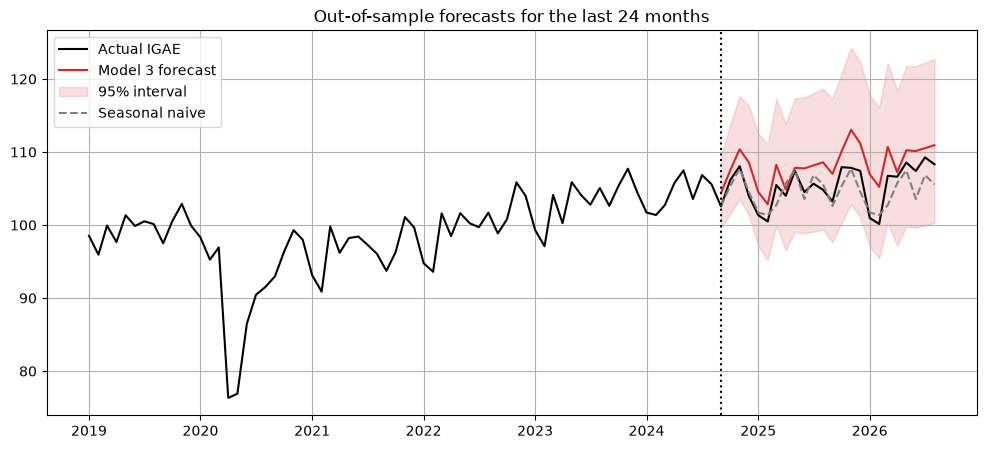

In [66]:
ci3 = fc3.conf_int(alpha=0.05)
plt.figure(figsize=(12, 5))
plt.plot(np.exp(igae_log['2019-01-01':]), color='black', label='Actual IGAE')
plt.plot(np.exp(fc3.predicted_mean), color='tab:red', label='Model 3 forecast')
plt.fill_between(test.index, np.exp(ci3.iloc[:, 0]), np.exp(ci3.iloc[:, 1]), color='tab:red', alpha=0.15, label='95% interval')
plt.plot(np.exp(snaive), color='tab:grey', linestyle='--', label='Seasonal naive')
plt.axvline(test.index[0], color='black', linestyle=':')
plt.title('Out-of-sample forecasts for the last 24 months')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

**MAPE** (error porcentual absoluto medio) es el error promedio como % del valor real; **RMSE** (raíz del error cuadrático medio) está en puntos del IGAE y castiga más los errores grandes.

**Discusión: ¿el SARIMA le gana al ingenuo estacional a 24 meses?**

**No.** A 24 meses el ingenuo estacional tiene MAPE de 1.32% y RMSE de 1.81 puntos, contra 2.71% y 3.19 del Modelo 3. El error del SARIMA es ~1.4 puntos porcentuales más alto (el doble). El modelo con mejor AIC lo hace todavía peor (MAPE 2.99%), lo cual muestra que un mejor ajuste dentro de muestra no garantiza mejores pronósticos.

La razón está en el crecimiento. El Modelo 3 empieza con el crecimiento reciente y lo regresa poco a poco hacia su media de largo plazo (~1.9% anual), con mucha persistencia ($\phi_1=0.93$). En el periodo de prueba pronosticó un crecimiento anual promedio de **3.4%**, pero la economía mexicana casi se estancó (crecimiento real promedio de **0.75%**). El ingenuo estacional supone crecimiento cero (repite el último año), y en este periodo eso quedó más cerca de lo que pasó. Con un solo origen de pronóstico, el resultado depende mucho de qué tan "normal" fue ese periodo.

### Comparación un paso adelante con un modelo de machine learning

La evaluación anterior pronostica hasta 24 meses desde un solo origen. Una alternativa común es la evaluación **un paso adelante** (*one-step-ahead*): cada mes pronostico solo el siguiente mes usando toda la información disponible hasta el mes anterior. Comparo:

- **Ingenuo estacional**: $\hat Y_t=Y_{t-12}$.
- **SARIMA (Modelo 3)**, con coeficientes estimados solo con datos de entrenamiento.
- **Gradient boosting** (modelo de árboles) que predice el crecimiento anual usando como features los últimos 12 valores del crecimiento anual.

Al modelo de ML le doy la versión **estacionaria** (la tasa de crecimiento). Los árboles no extrapolan: si le diera el nivel del IGAE, nunca podría predecir un valor por arriba del máximo que vio en entrenamiento (Parte B).

In [67]:
from sklearn.ensemble import GradientBoostingRegressor

# SARIMA one-step-ahead: same coefficients (estimated on train), applied to the full series
res3_full = res3.apply(igae_log)
sarima_1step = res3_full.get_prediction(start=test.index[0], end=test.index[-1], dynamic=False).predicted_mean

# Seasonal naive one-step-ahead
snaive_1step = igae_log.shift(12).loc[test.index]

# Gradient boosting on lags of the annual growth
g = igae_log.diff(12)
ml_data = pd.concat({'g': g, **{f'lag{k}': g.shift(k) for k in range(1, 13)}}, axis=1).dropna()
X_train = ml_data.loc[:train.index[-1]].drop(columns='g')
y_train = ml_data.loc[:train.index[-1], 'g']
X_test = ml_data.loc[test.index].drop(columns='g')
gbm = GradientBoostingRegressor(n_estimators=300, max_depth=2, learning_rate=0.05, random_state=0)
gbm.fit(X_train, y_train)

gbm_1step = pd.Series(gbm.predict(X_test), index=test.index) + igae_log.shift(12).loc[test.index]

onestep_table = pd.DataFrame({
    'Seasonal naive': metrics(test, snaive_1step),
    'SARIMA Model 3': metrics(test, sarima_1step),
    'Gradient boosting (lags of growth)': metrics(test, gbm_1step),
}).T.round(3)
onestep_table

,RMSE,MAPE (%)
Seasonal naive,1.759,1.262
SARIMA Model 3,1.488,1.129
Gradient boosting (lags of growth),2.207,1.396


**Discusión: ¿quién gana un paso adelante?**

Un paso adelante **gana el SARIMA**: MAPE 1.13% y RMSE 1.49, contra 1.26% / 1.76 del ingenuo estacional y 1.40% / 2.21 del gradient boosting. El SARIMA reduce el error del benchmark en ~10%, mientras que el modelo de ML queda **peor que el ingenuo**. Un paso adelante el SARIMA usa el dato más reciente cada mes, así que su sesgo hacia la media de largo plazo no se acumula como a 24 meses. Con unos cientos de observaciones mensuales y una sola serie, un SARIMA bien especificado es difícil de superar. Los modelos de árboles necesitan muchos más datos (muchas series relacionadas) o features externas útiles para lucirse.

### Pronóstico final

Para el pronóstico final re-estimo el modelo con **todos** los datos y pronostico 24 meses:

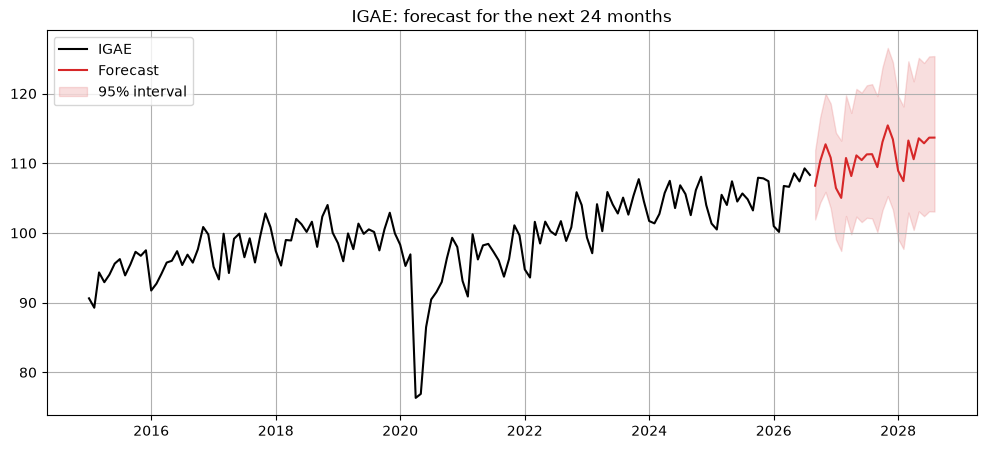

In [68]:
res_final = fit_sarima(igae_log, (1, 0, 1), (0, 1, 1, 12))
fc_final = res_final.get_forecast(24)
ci_final = fc_final.conf_int(alpha=0.05)

plt.figure(figsize=(12, 5))
plt.plot(np.exp(igae_log['2015-01-01':]), color='black', label='IGAE')
plt.plot(np.exp(fc_final.predicted_mean), color='tab:red', label='Forecast')
plt.fill_between(ci_final.index, np.exp(ci_final.iloc[:, 0]), np.exp(ci_final.iloc[:, 1]), color='tab:red', alpha=0.15, label='95% interval')
plt.title('IGAE: forecast for the next 24 months')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

Modelo el **log** del IGAE, así que regreso el pronóstico con $e^x$. La exponencial del pronóstico del log es el pronóstico de la **mediana** del IGAE (la media sería un poco mayor). El intervalo se abre conforme crece el horizonte, igual que el *fan chart* de la caminata aleatoria del Workshop 3.

## D.5 Agregar una variable externa: ARIMAX

La economía mexicana está muy ligada a la de EE.UU. El mercado accionario de EE.UU. es un **indicador adelantado**: los precios se mueven con las expectativas de los inversionistas sobre la actividad futura. ¿El S&P 500 del mes pasado ayuda a explicar el IGAE? Descargo el S&P 500 con `get_yahoo` y calculo promedios mensuales:

In [69]:
sp500_daily = get_yahoo('^GSPC', start='1990-01-01', end='2026-10-01')

> **Cómo trata SARIMAX la variable externa.** SARIMAX estima una **regresión con errores SARIMA**: $\ln IGAE_t=\beta X_t+u_t$, donde el error $u_t$ sigue el modelo SARIMA. Las diferencias ($D=1$) se aplican a toda la ecuación. Si $Y$ es el log del IGAE y $X$ el log del S&P 500, el modelo relaciona el crecimiento anual del IGAE con el cambio % anual del S&P 500. Por eso $X$ se pasa **en la misma forma que $Y$ (log-nivel)**, no como tasa de crecimiento.

In [70]:
log_sp = np.log(sp500_daily.resample('MS').mean()).asfreq('MS')   # log of the monthly average
x_lag1 = log_sp.shift(1).rename('log_sp500_lag1')                   # last month's S&P 500

x_in = x_lag1.reindex(igae_log.index)
sample = x_in.notna()
y_x = igae_log[sample]
x_x = x_in[sample]

res_x = fit_sarima(y_x, (1, 0, 1), (0, 1, 1, 12), exog=x_x)
res_nox = fit_sarima(y_x, (1, 0, 1), (0, 1, 1, 12))      # same sample, no exogenous variable
_ = diagnose(res_x, 'ARIMAX: Model 3 + lagged log S&P 500', plots=False)

beta_x = float(res_x.params['log_sp500_lag1'])
beta_x_p = float(res_x.pvalues['log_sp500_lag1'])
aic_x, aic_nox = float(res_x.aic), float(res_nox.aic)
print(f"\nbeta = {beta_x:.4f} (p-value = {beta_x_p:.4f}); AIC with X = {aic_x:.1f}, AIC without X = {aic_nox:.1f}")

===== ARIMAX: Model 3 + lagged log S&P 500 =====
                  coef  p-value
intercept       0.0007   0.0458
log_sp500_lag1  0.1402   0.0000
ar.L1           0.8957   0.0000
ma.L1          -0.2853   0.0000
ma.S.L12       -0.7502   0.0000
Ljung-Box p-value (lag 12): 0.0001 | (lag 24): 0.0000
AIC = -1811.40

beta = 0.1402 (p-value = 0.0000); AIC with X = -1811.4, AIC without X = -1795.7


$\hat\beta$ es una **elasticidad entre tasas de crecimiento**: si el cambio % anual del S&P 500 el mes pasado es 1 punto porcentual mayor, el crecimiento anual del IGAE este mes cambia en ~$\hat\beta$ puntos porcentuales. Los precios de las acciones son mucho más volátiles que la actividad económica, así que se espera un coeficiente pequeño. Un AIC menor con la variable externa (en la misma muestra) indica que sí aporta información.

**El problema para pronosticar.** Para pronosticar el IGAE 24 meses adelante con este modelo necesito los valores **futuros** del S&P 500, que no conozco. Usar el valor del mes pasado me da un mes de dato conocido; para horizontes más largos también hay que pronosticar la variable externa. Aquí uso la caminata aleatoria con drift del Workshop 3:

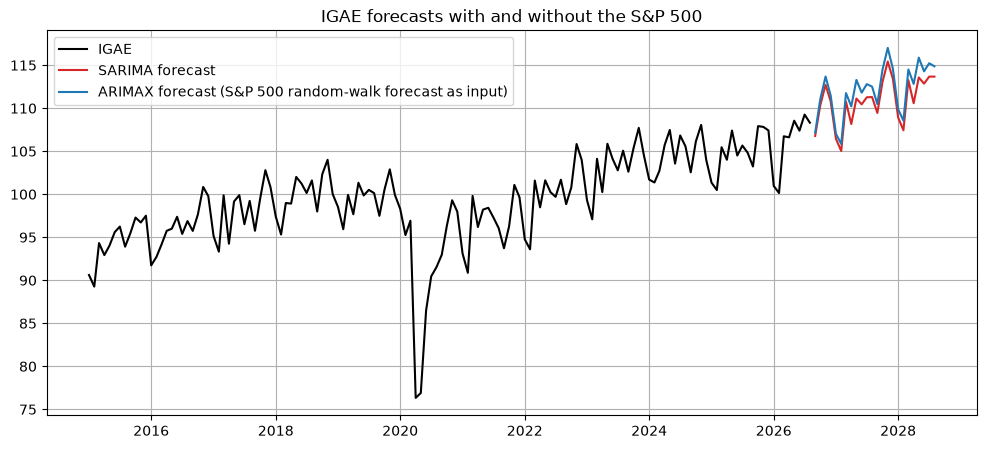

In [71]:
future_idx = pd.date_range(igae_log.index[-1] + pd.offsets.MonthBegin(1), periods=24, freq='MS')
# months of the S&P 500 we must forecast (shift(1) needs the series to extend to the last forecast month)
months_needed = len(pd.date_range(log_sp.index[-1] + pd.offsets.MonthBegin(1), future_idx[-1], freq='MS'))

drift_sp = float(log_sp.loc['2000-01-01':].diff().mean())          # monthly drift of the random walk
sp_future_idx = pd.date_range(log_sp.index[-1] + pd.offsets.MonthBegin(1), periods=max(months_needed, 0), freq='MS')
sp_future = pd.Series(float(log_sp.iloc[-1]) + drift_sp * np.arange(1, len(sp_future_idx) + 1), index=sp_future_idx)
log_sp_ext = pd.concat([log_sp, sp_future])
x_future = log_sp_ext.shift(1).reindex(future_idx).to_frame('log_sp500_lag1')

fc_x = res_x.get_forecast(24, exog=x_future)

plt.figure(figsize=(12, 5))
plt.plot(np.exp(igae_log['2015-01-01':]), color='black', label='IGAE')
plt.plot(np.exp(fc_final.predicted_mean), color='tab:red', label='SARIMA forecast')
plt.plot(np.exp(fc_x.predicted_mean), color='tab:blue', label='ARIMAX forecast (S&P 500 random-walk forecast as input)')
plt.title('IGAE forecasts with and without the S&P 500')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

El pronóstico ARIMAX **hereda los errores** del pronóstico de la variable externa. Una variable externa ayuda más cuando se **conoce por adelantado**: efectos de calendario, promociones planeadas o indicadores adelantados cuyo rezago es al menos tan largo como el horizonte de pronóstico.

---
# CHALLENGE 3 (Partes C y D)

## Challenge 3.1: Pronosticar las ventas de una marca (marca 6)

Uso las ventas mensuales en volumen de la marca 6 (`qbrand6tons`), $s=12$.

### a) Identificación

Grafico el log de las ventas y su cambio % anual:

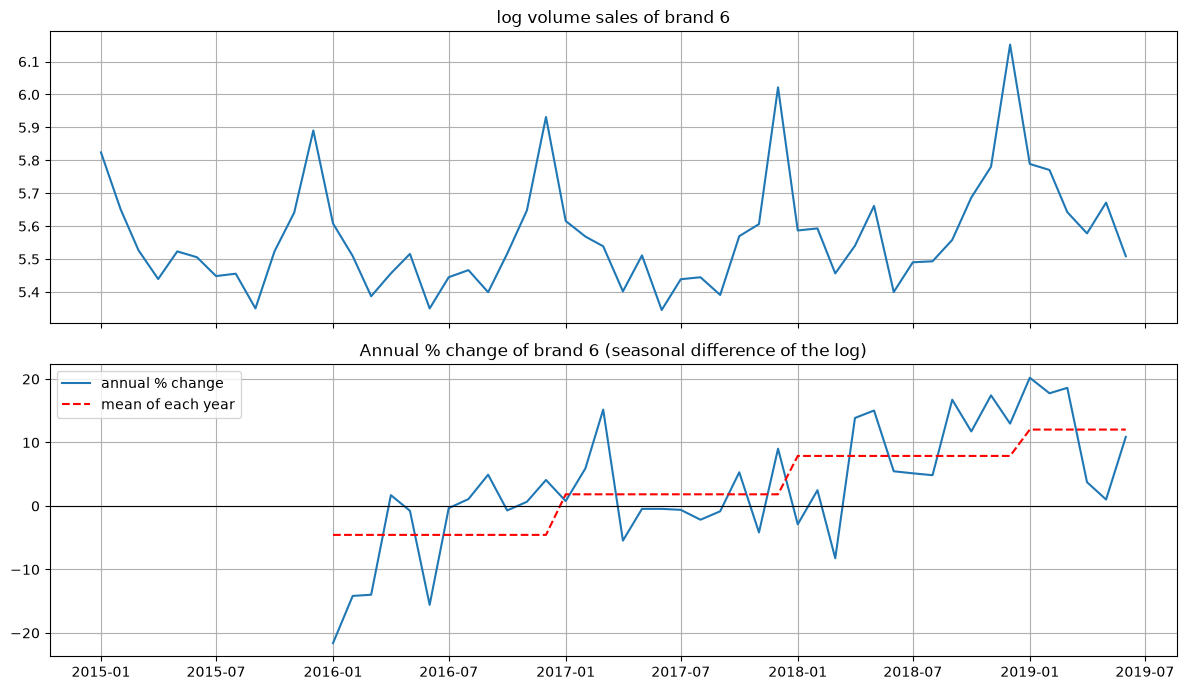

Observations: 54 months (2015-01 to 2019-06)


In [72]:
y6 = np.log(sales_brand['qbrand6tons']).rename('log_q6')
g6 = y6.diff(12)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(y6.index, y6)
axes[0].set_title('log volume sales of brand 6')
axes[1].plot(g6.index, 100 * g6, label='annual % change')
axes[1].plot(g6.index, 100 * g6.groupby(g6.index.year).transform('mean'), color='red', linestyle='--', label='mean of each year')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('Annual % change of brand 6 (seasonal difference of the log)')
axes[1].legend()
for ax in axes:
    ax.grid(True)
plt.tight_layout()
plt.show()
print(f"Observations: {len(y6)} months ({y6.index[0]:%Y-%m} to {y6.index[-1]:%Y-%m})")

Pruebo el log-nivel (`'ct'`), el cambio % anual (`'c'`) y, como el cambio anual parece tener tendencia, también la primera diferencia del cambio anual ($d=1, D=1$). Agrego la KPSS como prueba cruzada:

In [73]:
def kpss_p(x, regression='c'):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return kpss(x.dropna(), regression=regression, nlags='auto')[1]

w6 = g6.diff()   # d=1 and D=1: change of the annual growth
ident6 = pd.DataFrame({
    'log level': {'ADF p-value': adf_test(y6, 'ct')['p-value'], 'ADF spec': 'ct', 'KPSS p-value': kpss_p(y6, 'ct')},
    'annual % change (D=1)': {'ADF p-value': adf_test(g6, 'c')['p-value'], 'ADF spec': 'c', 'KPSS p-value': kpss_p(g6)},
    'annual % change, 1st diff (d=1, D=1)': {'ADF p-value': adf_test(w6, 'c')['p-value'], 'ADF spec': 'c', 'KPSS p-value': kpss_p(w6)},
}).T
ident6

,ADF p-value,ADF spec,KPSS p-value
log level,0.89463,ct,0.1
annual % change (D=1),0.032126,c,0.01
"annual % change, 1st diff (d=1, D=1)",0.0,c,0.1


**Interpretación de la identificación**

- **Log-nivel:** ADF (`'ct'`) p = 0.895 → no se rechaza la raíz unitaria. Además tiene una estacionalidad muy marcada (picos cada diciembre), así que necesito al menos la diferencia estacional: **$D=1$**.
- **Cambio % anual ($D=1$):** la ADF rechaza (p = 0.032), pero la KPSS **también rechaza** (p = 0.01): resultado ambiguo. La gráfica lo explica: la media del crecimiento anual sube cada año (-4.6% → 1.8% → 7.9% → 12.0%), así que el crecimiento no tiene una media constante. La marca está acelerando.
- **Con una primera diferencia adicional ($d=1$, $D=1$):** ADF p ≈ 0.000 y KPSS p = 0.10. Ahora las dos pruebas coinciden en que es estacionaria.

**Decisión: $d=1$, $D=1$, $s=12$.** El riesgo de diferenciar de más es crear un MA(1) con coeficiente cercano a -1. Lo reviso en la calibración: el $\hat\theta_1$ que sale (~-0.64) está lejos de -1, así que no hay señal de sobrediferenciación.

ACF y PACF de la serie estacionaria ($d=1$, $D=1$). Con pocas observaciones (~41) solo puedo ver hasta ~18 lags:

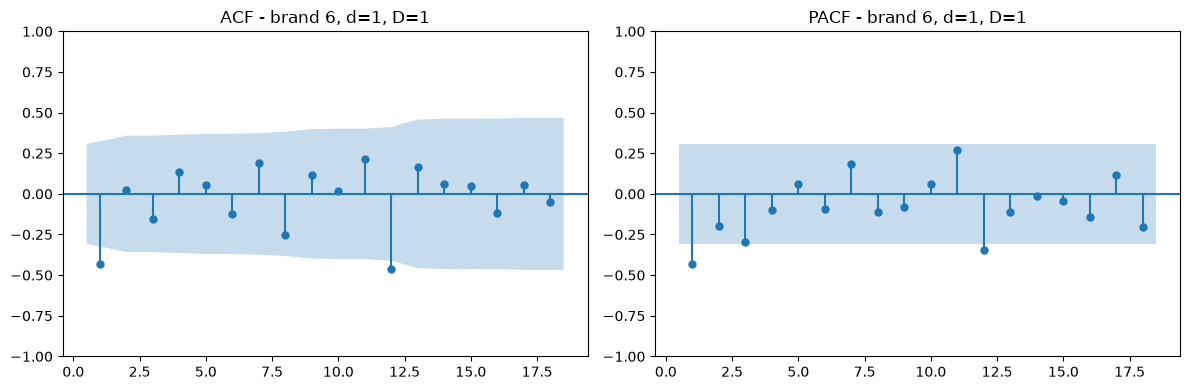

ACF  lags 1-13: [-0.43  0.02 -0.16  0.14  0.06 -0.12  0.19 -0.25  0.11  0.02  0.21 -0.46
  0.16]
PACF lags 1-13: [-0.43 -0.2  -0.29 -0.1   0.06 -0.09  0.19 -0.11 -0.08  0.06  0.27 -0.34
 -0.11]


In [74]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(w6.dropna(), lags=18, zero=False, ax=axes[0], title='ACF - brand 6, d=1, D=1')
plot_pacf(w6.dropna(), lags=18, zero=False, ax=axes[1], title='PACF - brand 6, d=1, D=1', method='ywm')
plt.tight_layout()
plt.show()
print('ACF  lags 1-13:', np.round(sm.tsa.acf(w6.dropna(), nlags=13)[1:], 2))
print('PACF lags 1-13:', np.round(pacf(w6.dropna(), nlags=13, method='ywm')[1:], 2))

**Modelo inicial propuesto.** La ACF tiene un pico negativo significativo en el **lag 1** (-0.43) y otro en el **lag 12** (-0.46), y casi nada entre ellos. La PACF decae en los primeros lags (-0.43, -0.20, -0.29). Es la firma de un **MA(1) regular** más un término **estacional en el lag 12**. El punto de partida natural es el "modelo aerolínea" SARIMA(0,1,1)(0,1,1)$_{12}$. Para documentar cada paso, empiezo sin términos ARMA y los agrego uno por uno según lo que pidan los residuales.

### b) Calibración

Dejo fuera los **últimos 12 meses** como test. Como uso $d=1$ y $D=1$, estimo con `trend='n'` (con dos diferencias una constante implicaría una tendencia cuadrática en el log).

La función `diagnose` del workshop usa 36 lags y Ljung-Box en 12 y 24, que es demasiado para esta serie: después de las dos diferencias quedan ~28 residuales en entrenamiento. Hago una versión con el número de lags como parámetro (Ljung-Box en 6 y 12, gráficas hasta 12 lags); la lógica es la misma.

In [75]:
y6_train = y6.iloc[:-12]
y6_test = y6.iloc[-12:]
print(f"Training: {y6_train.index[0]:%Y-%m} to {y6_train.index[-1]:%Y-%m} ({len(y6_train)} months)")
print(f"Test:     {y6_test.index[0]:%Y-%m} to {y6_test.index[-1]:%Y-%m} ({len(y6_test)} months)")

def diagnose_short(res, name, lb_lags=(6, 12), plot_lags=12, plots=True):
    """Same as diagnose(), but with fewer lags for short series."""
    s = res.model.seasonal_periods or 1
    burn = res.model.k_diff + s * res.model.k_seasonal_diff + 1
    resid = res.resid.iloc[burn:]
    m = res.model
    k = m.k_ar_params + m.k_ma_params + m.k_seasonal_ar_params + m.k_seasonal_ma_params
    lb = acorr_ljungbox(resid, lags=list(lb_lags), model_df=max(k, 0))
    coefs = pd.DataFrame({'coef': res.params, 'p-value': res.pvalues}).drop('sigma2').round(4)
    print(f"===== {name} =====  ({len(resid)} residuals)")
    print(coefs if len(coefs) else '(no ARMA coefficients)')
    print(' | '.join(f"Ljung-Box p-value (lag {l}): {p:.4f}" for l, p in zip(lb_lags, lb['lb_pvalue'])))
    print(f"AIC = {res.aic:.2f}")
    print('Residual ACF lags 1-12:', np.round(sm.tsa.acf(resid, nlags=12)[1:], 2))
    if plots:
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
        plot_acf(resid, lags=plot_lags, zero=False, ax=axes[0], title=f'Residual ACF - {name}')
        plot_pacf(resid, lags=plot_lags, zero=False, ax=axes[1], title=f'Residual PACF - {name}', method='ywm')
        plt.tight_layout()
        plt.show()
    return resid, lb

Training: 2015-01 to 2018-06 (42 months)
Test:     2018-07 to 2019-06 (12 months)


**Modelo B0: SARIMA(0,1,0)(0,1,0)$_{12}$** — solo las dos diferencias, sin términos ARMA. Sirve para ver qué estructura queda en los residuales.

===== B0: (0,1,0)(0,1,0,12) =====  (28 residuals)
(no ARMA coefficients)
Ljung-Box p-value (lag 6): 0.2161 | Ljung-Box p-value (lag 12): 0.0965
AIC = -52.78
Residual ACF lags 1-12: [-0.48 -0.03 -0.05  0.14 -0.03 -0.09  0.21 -0.15 -0.08  0.12  0.14 -0.33]


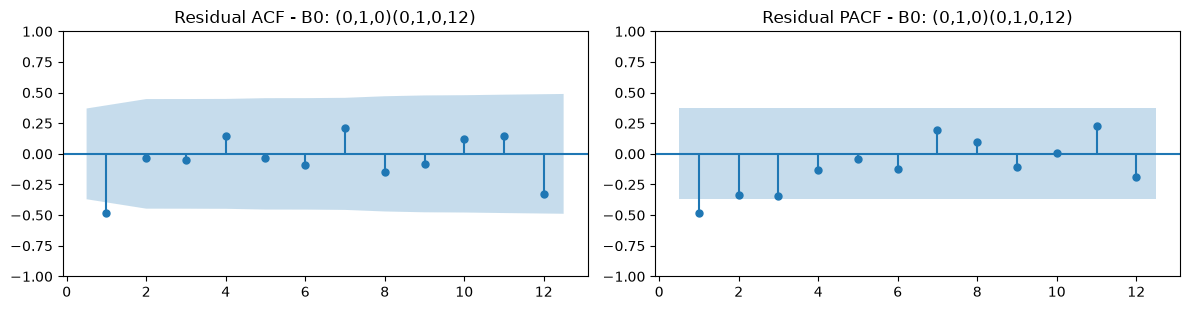

In [76]:
b0 = fit_sarima(y6_train, (0, 1, 0), (0, 1, 0, 12), trend='n')
rb0, lbb0 = diagnose_short(b0, 'B0: (0,1,0)(0,1,0,12)')

**B0 → qué falta.** Los residuales tienen un pico negativo grande en el **lag 1** (-0.48), fuera de la banda, y otro en el lag 12 (-0.33). Ljung-Box no llega a rechazar al 5% (p = 0.22 y 0.10) porque solo hay 28 residuales y la prueba tiene poco poder, pero el pico del lag 1 es muy claro. Un pico negativo en el lag 1 después de diferenciar es la señal clásica de un **MA(1)**, así que lo agrego.

**Modelo B1: SARIMA(0,1,1)(0,1,0)$_{12}$** — agrego MA(1):

===== B1: (0,1,1)(0,1,0,12) =====  (28 residuals)
         coef  p-value
ma.L1 -0.6419      0.0
Ljung-Box p-value (lag 6): 0.8668 | Ljung-Box p-value (lag 12): 0.3586
AIC = -60.94
Residual ACF lags 1-12: [-0.12 -0.1  -0.01  0.17  0.04 -0.02  0.17 -0.15 -0.1   0.11  0.05 -0.37]


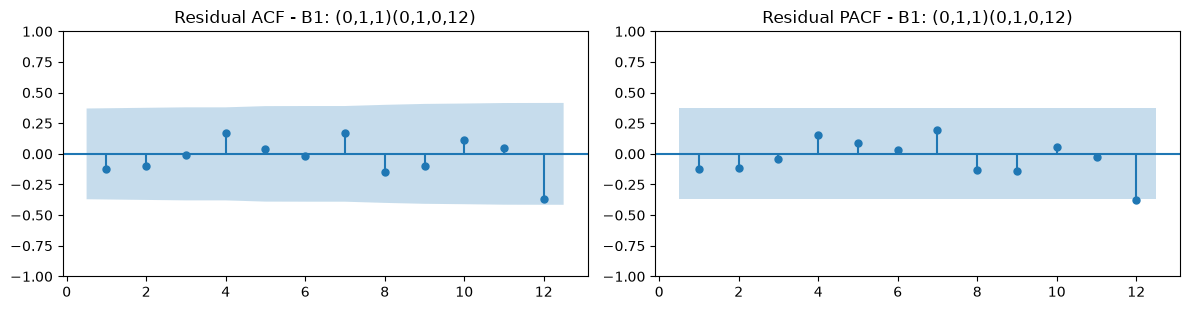

In [77]:
b1 = fit_sarima(y6_train, (0, 1, 1), (0, 1, 0, 12), trend='n')
rb1, lbb1 = diagnose_short(b1, 'B1: (0,1,1)(0,1,0,12)')

**B1 → qué cambió.** $\hat\theta_1=-0.64$ es muy significativo (p ≈ 0) y el AIC baja de -52.8 a -60.9 (8 puntos). El pico del lag 1 desaparece (-0.12) y Ljung-Box queda en p = 0.87 / 0.36. Pero sigue el pico negativo en el **lag 12** (-0.37): la diferencia estacional deja estructura en el lag estacional. Agrego un término estacional y pruebo las dos opciones ($Q=1$ y $P=1$).

**Modelos B2 y B3: término estacional.** Pruebo las dos formas de capturar el pico del lag 12: MA estacional ($Q=1$) y AR estacional ($P=1$):

===== B2: (0,1,1)(0,1,1,12) =====  (28 residuals)
            coef  p-value
ma.L1    -0.6287   0.0005
ma.S.L12 -0.3285   0.3868
Ljung-Box p-value (lag 6): 0.5598 | Ljung-Box p-value (lag 12): 0.5870
AIC = -61.69
Residual ACF lags 1-12: [-0.2  -0.1  -0.05  0.09  0.13 -0.11  0.26 -0.15 -0.11  0.07 -0.01 -0.15]


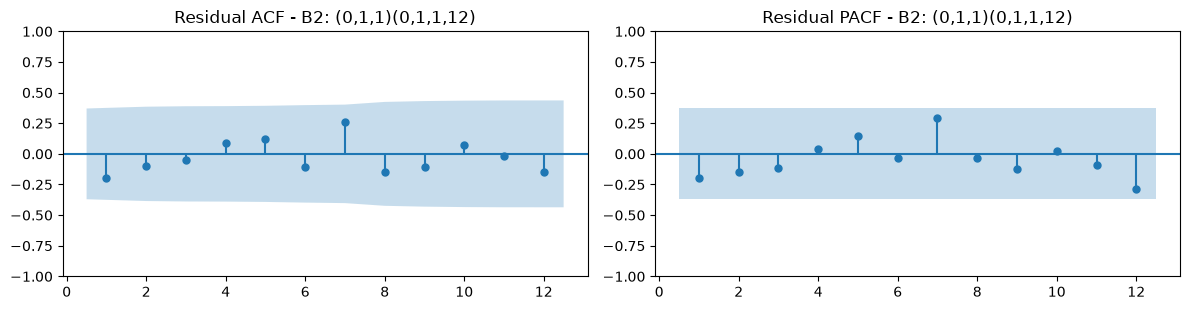

===== B3: (0,1,1)(1,1,0,12) =====  (28 residuals)
            coef  p-value
ma.L1    -0.6226   0.0010
ar.S.L12 -0.4906   0.0252
Ljung-Box p-value (lag 6): 0.2993 | Ljung-Box p-value (lag 12): 0.3622
AIC = -63.78
Residual ACF lags 1-12: [-0.24 -0.11 -0.07  0.03  0.19 -0.17  0.31 -0.14 -0.14  0.08 -0.05  0.01]


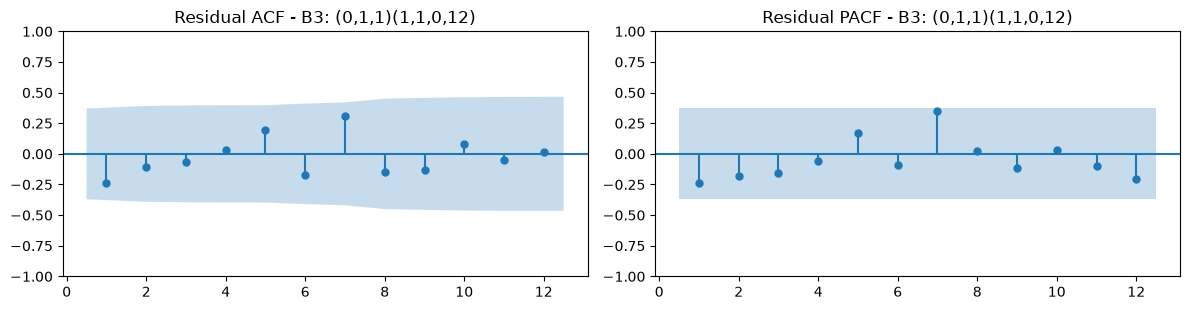

In [78]:
b2 = fit_sarima(y6_train, (0, 1, 1), (0, 1, 1, 12), trend='n')
rb2, lbb2 = diagnose_short(b2, 'B2: (0,1,1)(0,1,1,12)')
b3 = fit_sarima(y6_train, (0, 1, 1), (1, 1, 0, 12), trend='n')
rb3, lbb3 = diagnose_short(b3, 'B3: (0,1,1)(1,1,0,12)')

**B2 vs. B3 → cuál término estacional.**

- **B2 (MA estacional):** $\hat\Theta_1=-0.33$ con p = 0.39, **no significativo**. El AIC solo mejora 0.75 puntos (-61.69).
- **B3 (AR estacional):** $\hat\Phi_1=-0.49$ con p = 0.025, **significativo**. El AIC mejora 2.8 puntos respecto a B1 (-63.78), el pico del lag 12 desaparece (0.01) y Ljung-Box queda en p = 0.30 (lag 6) / 0.36 (lag 12): residuales compatibles con ruido blanco.

Me quedo con **B3**. Con solo 3.5 años de entrenamiento hay únicamente 2–3 observaciones por cada lag estacional, y el MA estacional no se puede estimar con precisión. El AR estacional negativo captura que el patrón estacional se corrige parcialmente de un año al siguiente. Queda un pico aislado en el lag 7 (0.31), pero con 12 lags y una banda al 95% es esperable algún pico por azar, y no hay una razón de negocio para un efecto a 7 meses, así que no agrego más términos.

**Comparación con `sarima_grid`.** Corro la búsqueda con $d=1, D=1$ y `trend='n'`. Como control, también corro la búsqueda con $d=0, D=1$ (la alternativa que sugería la ADF sola). Ojo: **los AIC de modelos con distinto $d$ no son comparables** (se calculan sobre series diferentes), así que la comparación entre $d=0$ y $d=1$ la hago fuera de muestra en el inciso c).

In [79]:
grid6 = sarima_grid(y6_train, d=1, D=1, s=12, trend='n')
print('Grid with d=1, D=1 (trend = n):')
print(grid6.head(8).round(3).to_string())
grid6_d0 = sarima_grid(y6_train, d=0, D=1, s=12, trend='c')
print('\nGrid with d=0, D=1 (trend = c):')
print(grid6_d0.head(5).round(3).to_string())

Grid with d=1, D=1 (trend = n):
       order       seasonal     AIC     BIC  Ljung-Box p (lag 24)  n params
0  (0, 1, 1)  (1, 1, 1, 12) -64.530 -59.061                 0.240         3
1  (2, 1, 2)  (1, 1, 1, 12) -63.880 -54.309                 0.411         6
2  (0, 1, 1)  (1, 1, 0, 12) -63.785 -59.683                 0.126         2
3  (0, 1, 2)  (1, 1, 1, 12) -63.117 -56.281                 0.301         4
4  (1, 1, 1)  (1, 1, 1, 12) -63.004 -56.167                 0.260         4
5  (1, 1, 0)  (1, 1, 1, 12) -62.672 -57.203                 0.127         3
6  (0, 1, 2)  (1, 1, 0, 12) -62.233 -56.764                 0.154         3
7  (1, 1, 1)  (1, 1, 0, 12) -62.178 -56.709                 0.131         3



Grid with d=0, D=1 (trend = c):
       order       seasonal     AIC     BIC  Ljung-Box p (lag 24)  n params
0  (1, 0, 1)  (1, 1, 0, 12) -63.107 -56.101                 0.150         3
1  (1, 0, 1)  (1, 1, 1, 12) -62.804 -54.397                 0.108         4
2  (2, 0, 0)  (1, 1, 0, 12) -62.427 -55.421                 0.150         3
3  (1, 0, 0)  (1, 1, 0, 12) -62.350 -56.745                 0.420         2
4  (2, 0, 0)  (1, 1, 1, 12) -61.886 -53.478                 0.100         4


In [80]:
aic_tbl = pd.DataFrame({
    'model': ['B0 (0,1,0)(0,1,0)', 'B1 (0,1,1)(0,1,0)', 'B2 (0,1,1)(0,1,1)', 'B3 (0,1,1)(1,1,0)',
              f"Grid best SARIMA{grid6.loc[0, 'order']}{grid6.loc[0, 'seasonal'][:3]}"],
    'AIC': [b0.aic, b1.aic, b2.aic, b3.aic, grid6.loc[0, 'AIC']],
    'BIC': [b0.bic, b1.bic, b2.bic, b3.bic, grid6.loc[0, 'BIC']],
    'n params': [0, 1, 2, 2, grid6.loc[0, 'n params']],
}).round(2)
aic_tbl

,model,AIC,BIC,n params
0,"B0 (0,1,0)(0,1,0)",-52.78,-51.41,0
1,"B1 (0,1,1)(0,1,0)",-60.94,-58.21,1
2,"B2 (0,1,1)(0,1,1)",-61.69,-57.59,2
3,"B3 (0,1,1)(1,1,0)",-63.78,-59.68,2
4,"Grid best SARIMA(0, 1, 1)(1, 1, 1)",-64.53,-59.06,3


Reviso los coeficientes del mejor modelo del grid (estimado con los mismos datos de entrenamiento):

In [81]:
g6best = fit_sarima(y6_train, grid6.loc[0, 'order'], grid6.loc[0, 'seasonal'], trend='n')
rg6, lbg6 = diagnose_short(g6best, f"Grid best: {grid6.loc[0, 'order']}{grid6.loc[0, 'seasonal']}", plots=False)

===== Grid best: (0, 1, 1)(1, 1, 1, 12) =====  (28 residuals)
            coef  p-value
ma.L1    -0.6227   0.0010
ar.S.L12 -0.9884   0.1068
ma.S.L12  0.8513   0.8215
Ljung-Box p-value (lag 6): 0.2194 | Ljung-Box p-value (lag 12): 0.3060
AIC = -64.53
Residual ACF lags 1-12: [-0.21 -0.13 -0.07  0.05  0.18 -0.16  0.29 -0.14 -0.14  0.15 -0.03 -0.01]


**Comparación con el grid.** El modelo con menor AIC es SARIMA(0,1,1)(1,1,1)$_{12}$ (AIC -64.53), apenas 0.75 puntos mejor que B3 (-63.78), que además es el **tercero** del ranking. Con una diferencia menor a 2 puntos prefiero el modelo más simple, y el **BIC prefiere B3** (-59.68 vs. -59.06). Al revisar el modelo del grid sus términos estacionales **no son significativos** ($\hat\Phi_1=-0.99$ con p ≈ 0.11 y $\hat\Theta_1=+0.85$ con p ≈ 0.82) y casi se cancelan entre sí: está sobreparametrizado y su estimación es inestable (un $\Phi$ pegado a -1). **Modelo elegido: B3 = SARIMA(0,1,1)(1,1,0)$_{12}$.**

Sobre el grid con $d=0$: su mejor modelo, (1,0,1)(1,1,0), tiene AIC -63.11, pero ese número no se puede comparar con los de $d=1$ (son verosimilitudes de series distintas). Por eso la comparación entre $d=0$ y $d=1$ la hago fuera de muestra.

### c) Evaluación fuera de muestra (12 meses)

Comparo contra el **ingenuo estacional** (repetir los últimos 12 meses de entrenamiento). También incluyo el mejor modelo del grid y, como control, el mejor modelo con $d=0$, para verificar con datos fuera de muestra la decisión de usar $d=1$. Las métricas se calculan en toneladas (escala original) con la función `metrics`.

In [82]:
final6_order, final6_seasonal = (0, 1, 1), (1, 1, 0, 12)     # chosen model (B3)
b_final = b3

snaive6 = pd.Series(y6_train.iloc[-12:].values, index=y6_test.index)
best6 = g6best
best6_d0 = fit_sarima(y6_train, grid6_d0.loc[0, 'order'], grid6_d0.loc[0, 'seasonal'], trend='c')

fc6 = {
    'Seasonal naive': snaive6,
    'Chosen B3 (0,1,1)(1,1,0)': b_final.get_forecast(12).predicted_mean,
    f"Grid best d=1 {grid6.loc[0, 'order']}{grid6.loc[0, 'seasonal'][:3]}": best6.get_forecast(12).predicted_mean,
    f"Grid best d=0 {grid6_d0.loc[0, 'order']}{grid6_d0.loc[0, 'seasonal'][:3]}": best6_d0.get_forecast(12).predicted_mean,
}
eval6 = pd.DataFrame({k: metrics(y6_test, v) for k, v in fc6.items()}).T.round(3)
eval6['MAPE vs naive (%)'] = (100 * (eval6['MAPE (%)'] / eval6.loc['Seasonal naive', 'MAPE (%)'] - 1)).round(1)
eval6

,RMSE,MAPE (%),MAPE vs naive (%)
Seasonal naive,38.978,10.911,0.0
"Chosen B3 (0,1,1)(1,1,0)",23.583,6.412,-41.2
"Grid best d=1 (0, 1, 1)(1, 1, 1)",13.781,4.120,-62.2
"Grid best d=0 (1, 0, 1)(1, 1, 0)",32.511,9.096,-16.6


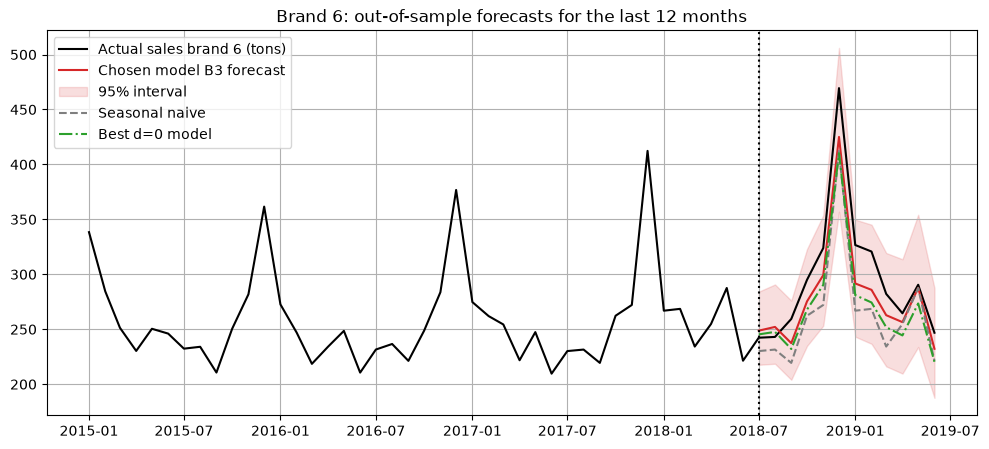

Share of test months inside the 95% interval of the chosen model: 100%


In [83]:
ci6 = b_final.get_forecast(12).conf_int(alpha=0.05)
plt.figure(figsize=(12, 5))
plt.plot(np.exp(y6), color='black', label='Actual sales brand 6 (tons)')
plt.plot(np.exp(fc6['Chosen B3 (0,1,1)(1,1,0)']), color='tab:red', label='Chosen model B3 forecast')
plt.fill_between(y6_test.index, np.exp(ci6.iloc[:, 0]), np.exp(ci6.iloc[:, 1]), color='tab:red', alpha=0.15, label='95% interval')
plt.plot(np.exp(snaive6), color='tab:grey', linestyle='--', label='Seasonal naive')
plt.plot(np.exp(fc6[list(fc6)[3]]), color='tab:green', linestyle='-.', label='Best d=0 model')
plt.axvline(y6_test.index[0], color='black', linestyle=':')
plt.title('Brand 6: out-of-sample forecasts for the last 12 months')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

# is the actual value inside the 95% interval?
inside = ((y6_test >= ci6.iloc[:, 0]) & (y6_test <= ci6.iloc[:, 1])).mean()
print(f"Share of test months inside the 95% interval of the chosen model: {100*inside:.0f}%")

**Interpretación de la evaluación**

- **Sí gana.** El modelo elegido (B3) tiene MAPE de **6.41%** contra **10.91%** del ingenuo estacional (41% menos error) y RMSE de 23.6 contra 39.0 toneladas. Los 12 meses de prueba caen dentro de su intervalo al 95%.
- **¿Por qué pierde el ingenuo?** En el año de prueba la marca creció ~12%. El ingenuo repite el año anterior (supone crecimiento cero), así que se queda corto todos los meses. El modelo con $d=1$ arrastra el crecimiento reciente hacia adelante.
- **Validación de $d=1$:** el mejor modelo con $d=0$ tiene MAPE de 9.10%, mejor que el ingenuo pero bastante peor que los modelos con $d=1$. Fuera de muestra se confirma que el crecimiento de esta marca no regresaba a una media fija.
- El modelo del grid (0,1,1)(1,1,1) lo hace aún mejor en el test (MAPE 4.12%), pero **no cambio mi elección por eso**. Elegir el modelo viendo el test sería usar el test para calibrar (*data leakage*), y con solo 12 meses de prueba esa diferencia puede ser suerte. Sus coeficientes estacionales no son significativos y casi se cancelan, así que no confiaría en que repita ese desempeño.

### d) Pronóstico final e interpretación

Re-estimo el modelo elegido con **todos** los datos y pronostico los 12 meses siguientes al último mes del dataset, con intervalos al 95%:

===== Final model brand 6: (0,1,1)(1,1,0,12), all data =====  (40 residuals)
            coef  p-value
ma.L1    -0.5754   0.0002
ar.S.L12 -0.5637   0.0001
Ljung-Box p-value (lag 6): 0.1560 | Ljung-Box p-value (lag 12): 0.3025
AIC = -100.81
Residual ACF lags 1-12: [-0.13 -0.1  -0.16  0.    0.2  -0.22  0.25 -0.16  0.    0.05 -0.08  0.05]
            forecast (tons)  lower 95%  upper 95%  same month last year  implied annual % change
2019-07-01            267.9      237.3      302.5                 242.3                     10.6
2019-08-01            269.2      235.9      307.1                 243.0                     10.8
2019-09-01            268.7      233.2      309.5                 259.4                      3.6
2019-10-01            314.3      270.3      365.3                 295.0                      6.5
2019-11-01            334.2      285.0      391.9                 323.9                      3.2
2019-12-01            496.7      420.2      587.1                 469.5         

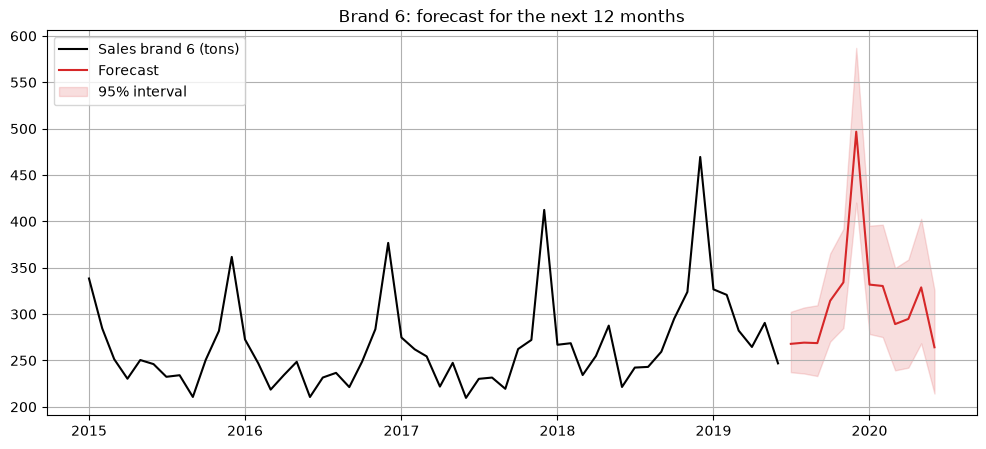

In [84]:
res6_final = fit_sarima(y6, final6_order, final6_seasonal, trend='n')
_ = diagnose_short(res6_final, 'Final model brand 6: (0,1,1)(1,1,0,12), all data', plots=False)

fc6_final = res6_final.get_forecast(12)
ci6_final = fc6_final.conf_int(alpha=0.05)
fc6_table = pd.DataFrame({
    'forecast (tons)': np.exp(fc6_final.predicted_mean),
    'lower 95%': np.exp(ci6_final.iloc[:, 0]),
    'upper 95%': np.exp(ci6_final.iloc[:, 1]),
    'same month last year': np.exp(y6.iloc[-12:]).values,
}).round(1)
fc6_table['implied annual % change'] = (100 * (fc6_table['forecast (tons)'] / fc6_table['same month last year'] - 1)).round(1)
print(fc6_table)

plt.figure(figsize=(12, 5))
plt.plot(np.exp(y6), color='black', label='Sales brand 6 (tons)')
plt.plot(fc6_table['forecast (tons)'], color='tab:red', label='Forecast')
plt.fill_between(fc6_table.index, fc6_table['lower 95%'], fc6_table['upper 95%'], color='tab:red', alpha=0.15, label='95% interval')
plt.title('Brand 6: forecast for the next 12 months')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

**Crecimiento de largo plazo y vida media.** En el modelo elegido, sea $w_t=(1-L)(1-L^{12})\ln Q_t$ el cambio mes a mes del crecimiento anual. El modelo es

$$(1-\Phi_1L^{12})\,w_t = (1+\theta_1L)\,\varepsilon_t$$

Como tiene $d=1$ y $D=1$ y no tiene constante, **el crecimiento anual no tiene una media fija a la cual regresar**: es I(1). Por eso, a diferencia del IGAE, $c/(1-\phi_1)$ no existe. Para calcular lo que piden (crecimiento de largo plazo y vida media) hago dos cosas:

1. Con la **función impulso-respuesta** del modelo veo cómo un shock de 1 (en log) afecta el crecimiento anual en los meses siguientes, y de ahí calculo la vida media.
2. Como **referencia**, estimo con todos los datos el mejor modelo con $d=0$ (el que asume crecimiento anual estacionario), que sí tiene media de largo plazo $c/(1-\phi_1)$ y vida media $\ln 0.5/\ln|\phi_1|$.

theta1 = -0.5754, Phi1 (seasonal AR) = -0.5637
                    effect on annual growth  effect on log sales
months after shock                                              
0                                     1.000                1.000
1                                     0.425                0.425
2                                     0.425                0.425
6                                     0.425                0.425
11                                    0.425                0.425
12                                   -0.139                0.861
13                                    0.185                0.610
24                                    0.503                1.364
35                                    0.320                0.930
Same as statsmodels impulse_responses: True

The effect of a shock on the annual growth falls below half after 1 month(s).


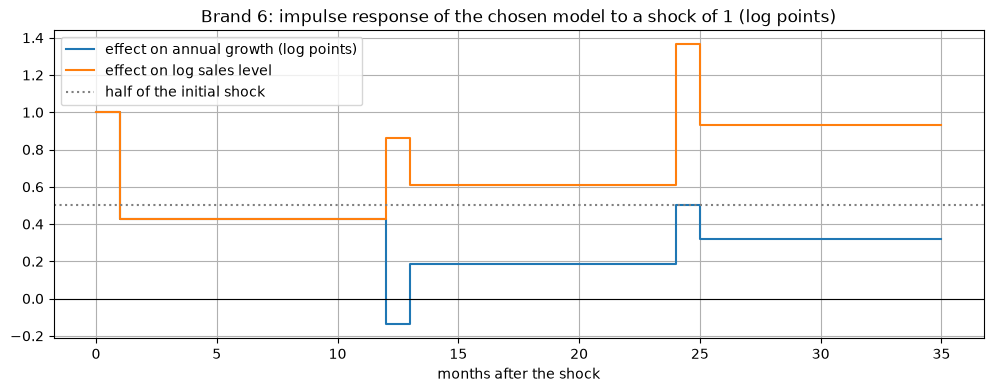

In [85]:
theta6 = float(res6_final.params['ma.L1'])
Phi6 = float(res6_final.params['ar.S.L12'])
print(f"theta1 = {theta6:.4f}, Phi1 (seasonal AR) = {Phi6:.4f}")

# Impulse response: simulate the model with a single shock of 1 at t=0 (no other shocks)
H = 36
eps = np.zeros(H + 13); eps[13] = 1.0
w = np.zeros(H + 13)
for t in range(13, H + 13):
    w[t] = Phi6 * w[t - 12] + eps[t] + theta6 * eps[t - 1]       # (1 - Phi L^12) w_t = (1 + theta L) e_t
w = w[13:]
annual_growth_irf = np.cumsum(w)                    # annual growth = cumulative sum of w (because of d=1)
log_level_irf = np.zeros(H)                          # log level: undo the seasonal difference
for k in range(H):
    log_level_irf[k] = annual_growth_irf[k] + (log_level_irf[k - 12] if k >= 12 else 0)

below_half = np.where(np.abs(annual_growth_irf) <= 0.5)[0]
hl6 = int(below_half[0]) if len(below_half) else np.inf
irf_tbl = pd.DataFrame({'months after shock': range(H),
                        'effect on annual growth': annual_growth_irf.round(3),
                        'effect on log sales': log_level_irf.round(3)}).set_index('months after shock')
print(irf_tbl.loc[[0, 1, 2, 6, 11, 12, 13, 24, 35]])
# cross-check with statsmodels: impulse responses of the observed series (log sales)
sm_irf = np.asarray(res6_final.impulse_responses(steps=H - 1)).ravel()
print(f"Same as statsmodels impulse_responses: {np.allclose(sm_irf, log_level_irf)}")
print(f"\nThe effect of a shock on the annual growth falls below half after {hl6} month(s).")

fig, ax = plt.subplots(figsize=(12, 4))
ax.step(range(H), annual_growth_irf, where='post', label='effect on annual growth (log points)')
ax.step(range(H), log_level_irf, where='post', label='effect on log sales level')
ax.axhline(0.5, color='grey', linestyle=':', label='half of the initial shock')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('months after the shock')
ax.set_title('Brand 6: impulse response of the chosen model to a shock of 1 (log points)')
ax.legend()
ax.grid(True)
plt.show()

In [86]:
# Reference: best d=0 model re-estimated with all data (assumes stationary annual growth)
ref_order, ref_seasonal = grid6_d0.loc[0, 'order'], grid6_d0.loc[0, 'seasonal']
res6_ref = fit_sarima(y6, ref_order, ref_seasonal, trend='c')
print(pd.DataFrame({'coef': res6_ref.params, 'p-value': res6_ref.pvalues}).round(4))
c_ref, phi_ref = float(res6_ref.params['intercept']), float(res6_ref.params['ar.L1'])
Phi_ref = float(res6_ref.params.get('ar.S.L12', 0.0))
# long-run mean of the annual growth: E[w] (1 - phi)(1 - Phi) = c
mean_g_ref = c_ref / ((1 - phi_ref) * (1 - Phi_ref))
print(f"\nReference d=0 model SARIMA{ref_order}{ref_seasonal[:3]}: long-run mean annual growth = {100*mean_g_ref:.2f}%, "
      f"half-life (AR term) = {np.log(0.5)/np.log(abs(phi_ref)):.2f} months")

# What the chosen model implies for growth: average annual growth of the 12-month forecast
g_fc = float(np.mean(fc6_final.predicted_mean.values - y6.iloc[-12:].values))
g_last = float(g6.iloc[-12:].mean())
print(f"Chosen model: mean annual growth in the last 12 observed months = {100*g_last:.1f}%; "
      f"implied mean annual growth of the next 12 months = {100*g_fc:.1f}%")

             coef  p-value
intercept  0.0005   0.8642
ar.L1      0.9703   0.0000
ma.L1     -0.5664   0.0003
ar.S.L12  -0.5669   0.0002
sigma2     0.0038   0.0002

Reference d=0 model SARIMA(1, 0, 1)(1, 1, 0): long-run mean annual growth = 1.04%, half-life (AR term) = 23.01 months
Chosen model: mean annual growth in the last 12 observed months = 11.8%; implied mean annual growth of the next 12 months = 6.3%


**Interpretación del modelo final, SARIMA(0,1,1)(1,1,0)$_{12}$ con todos los datos**

El modelo es $(1-\Phi_1L^{12})(1-L)(1-L^{12})\ln Q_t = (1+\theta_1L)\varepsilon_t$. Con los 54 meses, los dos coeficientes son significativos y los residuales pasan Ljung-Box (p = 0.16 en el lag 6 y 0.30 en el lag 12).

- **$\hat\theta_1=-0.575$ (MA regular):** el 57.5% de una sorpresa mensual se revierte al mes siguiente. Por ejemplo, si un mes se vende más de lo esperado porque los clientes adelantaron compras (una promoción, o una cadena que se surte por adelantado), al mes siguiente se vende menos. El 42.5% restante se queda como un cambio **permanente** en el nivel de ventas.
- **$\hat\Phi_1=-0.564$ (AR estacional):** el cambio del crecimiento en un mes, comparado con el mismo mes del año anterior, se revierte en ~56% al año siguiente. El patrón estacional se corrige solo: si un diciembre sale atípicamente fuerte, el siguiente diciembre tiende a crecer menos.
- **Sin constante:** con $d=1$ y $D=1$ no hay una tendencia determinística. El modelo no tiene un crecimiento "de equilibrio" fijo.

**Crecimiento anual de largo plazo implicado.** En el modelo elegido el crecimiento anual es I(1), así que **no tiene una media de largo plazo** a la cual regresar ($c/(1-\phi_1)$ no existe). Su mejor pronóstico del crecimiento es el crecimiento reciente, ajustado por los términos MA y SAR: pronostica en promedio **6.3%** de crecimiento anual para los próximos 12 meses (julio 2019 – junio 2020), menos que el 11.8% de los últimos 12 meses observados, porque los últimos meses (abril–junio 2019) ya venían más lentos. Como referencia, el mejor modelo con $d=0$ estimado con todos los datos da una media de largo plazo de solo **1.0%** anual, con una constante no significativa (p = 0.86) y un $\hat\phi_1=0.97$, prácticamente una raíz unitaria. Eso confirma que suponer un crecimiento estacionario no era realista para esta marca.

**Vida media de un shock al crecimiento.**
- En el modelo elegido, un shock al crecimiento anual cae de 1 a 0.43 **después de 1 mes** (vida media < 1 mes) por el MA(1). Pero el 43% que queda no desaparece: con $d=1$ y $D=1$ los shocks tienen un **efecto permanente** en el nivel de ventas (en la gráfica de impulso-respuesta el efecto en el log de ventas no regresa a cero).
- Con el modelo de referencia ($d=0$), la vida media de un shock al crecimiento es de **~23 meses**.

Las dos lecturas dicen lo mismo para el negocio: la mayor parte de una sorpresa mensual es ruido que se revierte rápido, pero lo que sí cambia el crecimiento de la marca dura años. **Pronóstico:** para los próximos 12 meses el modelo espera ventas entre ~264 y ~497 toneladas mensuales, con el pico en diciembre 2019 (497 t, intervalo al 95% de 420 a 587 t). Los intervalos se abren de ±12% a ±23% conforme crece el horizonte.

## Challenge 3.2: ¿El tipo de cambio ayuda a pronosticar el IGAE?

Descargo el tipo de cambio USD/MXN (`MXN=X`, pesos por dólar) de 2000-01-01 a 2026-09-30 (`end='2026-10-01'`) y calculo promedios mensuales. Nota: Yahoo solo tiene datos de `MXN=X` desde diciembre 2003, así que la muestra del ARIMAX empieza en 2004.

USD/MXN monthly data: 2003-12 to 2026-09


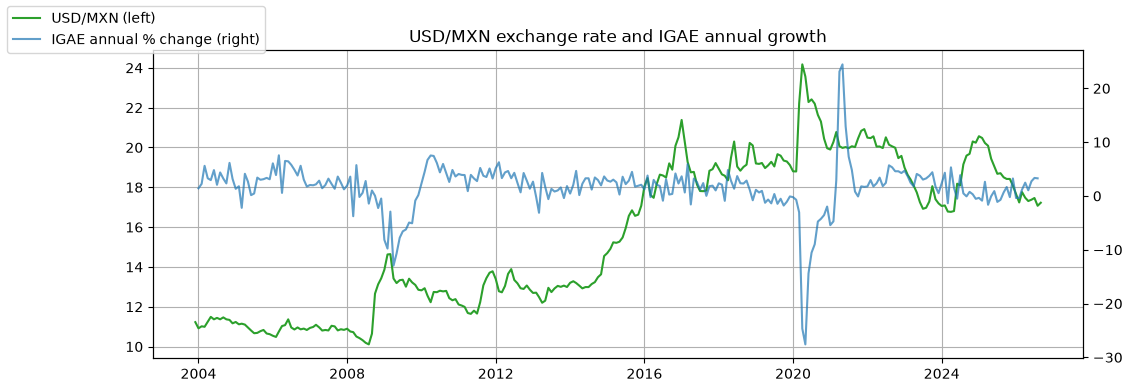

In [87]:
fx_daily = get_yahoo('MXN=X', start='2000-01-01', end='2026-10-01')
log_fx = np.log(fx_daily.resample('MS').mean()).asfreq('MS')
print(f"USD/MXN monthly data: {log_fx.index[0]:%Y-%m} to {log_fx.index[-1]:%Y-%m}")

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(np.exp(log_fx), color='tab:green', label='USD/MXN (left)')
ax2 = ax1.twinx()
ax2.plot(100 * igaedf['annualgrowth'].loc['2004':], color='tab:blue', alpha=0.7, label='IGAE annual % change (right)')
ax1.set_title('USD/MXN exchange rate and IGAE annual growth')
fig.legend(loc='upper left')
ax1.grid(True)
plt.show()

### a) ARIMAX con el log del USD/MXN rezagado un mes (muestra completa)

Paso $X$ en la misma forma que $Y$: **log-nivel** del promedio mensual, rezagado un mes. Comparo el AIC con y sin la variable externa **en la misma muestra**.

In [88]:
fx_lag1 = log_fx.shift(1).rename('log_usdmxn_lag1')
x_fx_in = fx_lag1.reindex(igae_log.index)
sample_fx = x_fx_in.notna()
y_fx, x_fx = igae_log[sample_fx], x_fx_in[sample_fx]
print(f"ARIMAX sample: {y_fx.index[0]:%Y-%m} to {y_fx.index[-1]:%Y-%m} ({len(y_fx)} months)")

res_fx = fit_sarima(y_fx, (1, 0, 1), (0, 1, 1, 12), exog=x_fx)
res_fx_nox = fit_sarima(y_fx, (1, 0, 1), (0, 1, 1, 12))
_ = diagnose(res_fx, 'ARIMAX: Model 3 + lagged log USD/MXN', plots=False)
_ = diagnose(res_fx_nox, 'SARIMA Model 3, same sample, no X', plots=False)

beta_fx = float(res_fx.params['log_usdmxn_lag1'])
beta_fx_p = float(res_fx.pvalues['log_usdmxn_lag1'])
print(f"\nbeta (USD/MXN) = {beta_fx:.4f}, p-value = {beta_fx_p:.4f}, 95% CI = {np.round(res_fx.conf_int().loc['log_usdmxn_lag1'].values, 4)}")
print(f"AIC with USD/MXN = {res_fx.aic:.2f} | AIC without = {res_fx_nox.aic:.2f} | difference = {res_fx.aic - res_fx_nox.aic:.2f}")
print(f"Effect of a 10% annual depreciation of the peso on IGAE annual growth: {100*beta_fx*np.log(1.10):.2f} percentage points")

ARIMAX sample: 2004-01 to 2026-08 (272 months)


===== ARIMAX: Model 3 + lagged log USD/MXN =====
                   coef  p-value
intercept        0.0022   0.0012
log_usdmxn_lag1 -0.2135   0.0000
ar.L1            0.8949   0.0000
ma.L1           -0.2762   0.0000
ma.S.L12        -0.9642   0.0000
Ljung-Box p-value (lag 12): 0.0002 | (lag 24): 0.0000
AIC = -1173.65
===== SARIMA Model 3, same sample, no X =====
             coef  p-value
intercept  0.0028   0.0001
ar.L1      0.8118   0.0000
ma.L1     -0.1302   0.0237
ma.S.L12  -0.9156   0.0000
Ljung-Box p-value (lag 12): 0.0004 | (lag 24): 0.0000
AIC = -1152.90

beta (USD/MXN) = -0.2135, p-value = 0.0000, 95% CI = [-0.2979 -0.1292]
AIC with USD/MXN = -1173.65 | AIC without = -1152.90 | difference = -20.74
Effect of a 10% annual depreciation of the peso on IGAE annual growth: -2.04 percentage points


**Interpretación de $\hat\beta$ (tipo de cambio)**

- $\hat\beta=-0.214$ (p ≈ 0, IC 95%: -0.30 a -0.13). Como $X$ y $Y$ entran en log y el modelo tiene $D=1$, es una **elasticidad entre tasas de crecimiento anuales**: si el mes pasado el peso estaba 10% más depreciado que un año antes ($\ln 1.10 = 0.095$), el crecimiento anual del IGAE de este mes es **~2.0 puntos porcentuales menor**.
- **Una depreciación del peso va con menos crecimiento de la actividad económica.** El signo negativo tiene sentido para México en 2004–2026: las grandes depreciaciones (2008–2009, 2016, 2020) coinciden con choques de aversión al riesgo y salida de capitales que también frenan la economía. Además, los insumos importados se encarecen y baja el poder de compra. También puede haber causalidad inversa (una economía débil debilita al peso), así que lo leo como una **asociación**, no necesariamente como un efecto causal.
- **AIC:** -1173.65 con el tipo de cambio contra -1152.90 sin él, en la misma muestra (2004–2026): **20.7 puntos menos**, una mejora grande dentro de muestra. Para comparar, el S&P 500 en clase mejoró el AIC en ~15.7 puntos en su muestra.

### b) Evaluación fuera de muestra: mismo test de 24 meses

Uso el mismo test de clase (últimos 24 meses). Para cada variable externa (USD/MXN y, para comparar, el S&P 500 de clase) estimo con datos de entrenamiento:

- el **ARIMAX** (Modelo 3 + X rezagada) y
- el **SARIMA sin X** en la misma muestra (para que la comparación sea justa).

**24 meses adelante:** necesito pronósticos de X. Uso una caminata aleatoria con drift **estimada solo con datos de entrenamiento** (hasta 2024-08). Como X está rezagada un mes, el primer mes de test usa el valor real de agosto 2024 (conocido) y el resto usa el pronóstico.

**1 mes adelante:** aplico los coeficientes estimados en entrenamiento a toda la serie con los valores **reales** de X (el valor del mes pasado siempre se conoce al momento de pronosticar).

In [89]:
def arimax_oos(log_x, xname, drift_start='2000-01-01'):
    """Out-of-sample comparison (same 24-month test as in class) of Model 3 with and without
    the lagged external variable log_x. Returns tables for 24-step and 1-step forecasts."""
    x_all = log_x.shift(1).rename(xname).reindex(igae_log.index)
    start = x_all.first_valid_index()
    y_s, x_s = igae_log.loc[start:], x_all.loc[start:]
    y_tr, x_tr = y_s.loc[:train.index[-1]], x_s.loc[:train.index[-1]]

    r_x = fit_sarima(y_tr, (1, 0, 1), (0, 1, 1, 12), exog=x_tr)
    r_nox = fit_sarima(y_tr, (1, 0, 1), (0, 1, 1, 12))

    # 24 months ahead: random walk with drift for log_x, estimated ONLY with training data
    lx_tr = log_x.loc[drift_start:train.index[-1]].dropna()
    drift = float(lx_tr.diff().mean())
    fut_idx = pd.date_range(lx_tr.index[-1] + pd.offsets.MonthBegin(1), test.index[-1], freq='MS')
    lx_fc = pd.Series(float(lx_tr.iloc[-1]) + drift * np.arange(1, len(fut_idx) + 1), index=fut_idx)
    x_test_fc = pd.concat([lx_tr, lx_fc]).shift(1).reindex(test.index).to_frame(xname)
    fc24_x = r_x.get_forecast(h_test, exog=x_test_fc).predicted_mean
    fc24_nox = r_nox.get_forecast(h_test).predicted_mean

    # 1 month ahead: train coefficients applied to the full sample, with the ACTUAL lagged X
    one_x = r_x.apply(y_s, exog=x_s).get_prediction(start=test.index[0], end=test.index[-1], dynamic=False).predicted_mean
    one_nox = r_nox.apply(y_s).get_prediction(start=test.index[0], end=test.index[-1], dynamic=False).predicted_mean

    t24 = pd.DataFrame({f'SARIMA no X (sample from {start:%Y})': metrics(test, fc24_nox),
                        f'ARIMAX + {xname}': metrics(test, fc24_x)}).T
    t1 = pd.DataFrame({f'SARIMA no X (sample from {start:%Y})': metrics(test, one_nox),
                       f'ARIMAX + {xname}': metrics(test, one_x)}).T
    info = {'beta (train)': float(r_x.params[xname]), 'p-value (train)': float(r_x.pvalues[xname]),
            'AIC with X (train)': r_x.aic, 'AIC no X (train)': r_nox.aic, 'drift used': drift}
    x_err = pd.DataFrame({'actual lagged X': x_s.loc[test.index], 'RW forecast of lagged X': x_test_fc[xname]})
    return t24, t1, info, x_err

fx24, fx1, fx_info, fx_xerr = arimax_oos(log_fx, 'log_usdmxn_lag1')
sp24, sp1, sp_info, sp_xerr = arimax_oos(log_sp, 'log_sp500_lag1')

bench24 = pd.DataFrame({'Seasonal naive': metrics(test, snaive)}).T
bench1 = pd.DataFrame({'Seasonal naive': metrics(test, snaive_1step)}).T
print('===== 24 months ahead (one origin: 2024-08) =====')
print(pd.concat([bench24, fx24, sp24]).round(3))
print('\n===== 1 month ahead =====')
print(pd.concat([bench1, fx1, sp1]).round(3))
print('\nTraining-sample estimates:')
print(pd.DataFrame({'USD/MXN': fx_info, 'S&P 500': sp_info}).round(4))

===== 24 months ahead (one origin: 2024-08) =====
                                 RMSE  MAPE (%)
Seasonal naive                  1.813     1.316
SARIMA no X (sample from 2004)  1.826     1.485
ARIMAX + log_usdmxn_lag1        3.489     2.995
SARIMA no X (sample from 1993)  3.188     2.709
ARIMAX + log_sp500_lag1         4.229     3.741

===== 1 month ahead =====
                                 RMSE  MAPE (%)
Seasonal naive                  1.759     1.262
SARIMA no X (sample from 2004)  1.399     1.053
ARIMAX + log_usdmxn_lag1        1.750     1.310
SARIMA no X (sample from 1993)  1.488     1.129
ARIMAX + log_sp500_lag1         1.918     1.516

Training-sample estimates:
                      USD/MXN    S&P 500
beta (train)          -0.2127     0.1405
p-value (train)        0.0000     0.0000
AIC with X (train) -1045.1439 -1692.6897
AIC no X (train)   -1023.9335 -1669.0370
drift used             0.0022     0.0046


¿Qué tan buenos fueron los pronósticos de la caminata aleatoria para las variables externas? Comparo el valor real de X con el pronosticado en el periodo de prueba (en niveles, no en log):

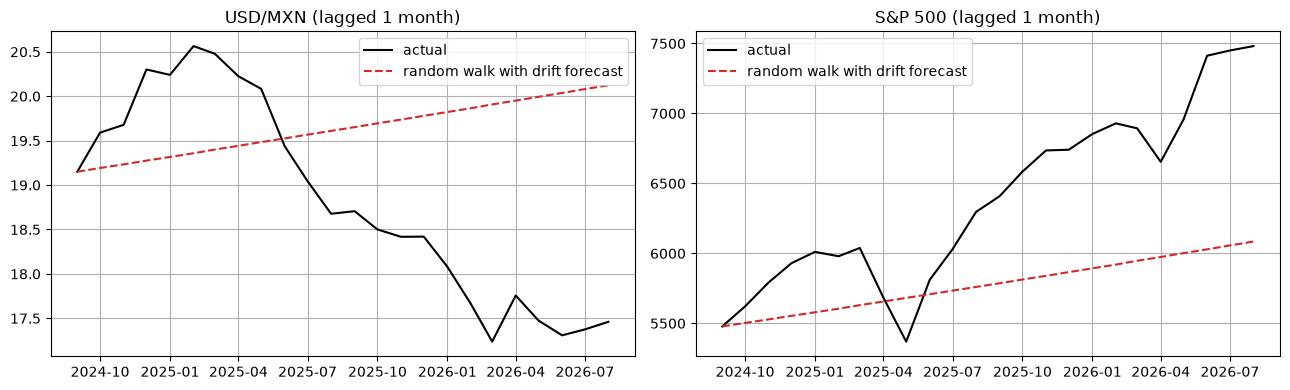

,USD/MXN,S&P 500
MAPE of the X forecast (%),7.38,9.36


In [90]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (xerr, title) in zip(axes, [(fx_xerr, 'USD/MXN (lagged 1 month)'), (sp_xerr, 'S&P 500 (lagged 1 month)')]):
    ax.plot(np.exp(xerr['actual lagged X']), color='black', label='actual')
    ax.plot(np.exp(xerr['RW forecast of lagged X']), color='tab:red', linestyle='--', label='random walk with drift forecast')
    ax.set_title(title)
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

xerr_tbl = pd.DataFrame({
    'USD/MXN': {'MAPE of the X forecast (%)': float(100 * np.mean(np.abs(np.exp(fx_xerr.iloc[:, 1]) / np.exp(fx_xerr.iloc[:, 0]) - 1)))},
    'S&P 500': {'MAPE of the X forecast (%)': float(100 * np.mean(np.abs(np.exp(sp_xerr.iloc[:, 1]) / np.exp(sp_xerr.iloc[:, 0]) - 1)))},
}).round(2)
xerr_tbl

**Conclusiones del Challenge 3.2**

| Horizonte | SARIMA sin X (muestra 2004) | ARIMAX + USD/MXN | SARIMA sin X (muestra 1993) | ARIMAX + S&P 500 | Ingenuo estacional |
|---|---|---|---|---|---|
| 24 meses, MAPE | 1.49% | 3.00% | 2.71% | 3.74% | 1.32% |
| 1 mes, MAPE | 1.05% | 1.31% | 1.13% | 1.52% | 1.26% |

- **¿Vale la pena el ARIMAX a 1 mes?** **No** en este periodo de prueba. Aunque a un mes el valor de $X$ (el tipo de cambio del mes pasado) es conocido, el ARIMAX empeora el MAPE de 1.05% a 1.31% y queda peor que el ingenuo. El problema no es pronosticar $X$, sino que **la relación cambió**: en 2025 el peso se apreció ~15% (de ~20.5 a ~17.3) y el modelo esperaba más crecimiento, pero la economía se estancó. La depreciación de 2024 vino de un choque político (elecciones y reforma judicial), no de una crisis como las que dominan la muestra de estimación.
- **¿Y a 24 meses?** **Tampoco**: el MAPE se duplica (1.49% → 3.00%). Aquí además se suma el error de pronosticar $X$: la caminata aleatoria con drift esperaba una depreciación gradual hasta ~20.1, pero el peso se apreció (error de pronóstico de $X$ de 7.4%). El ARIMAX hereda ese error.
- **Tipo de cambio vs. S&P 500.** Dentro de muestra los dos ayudan (mejoras de AIC de 15–24 puntos), y en la muestra completa el tipo de cambio mejora más el AIC (20.7 vs. 15.7). Fuera de muestra **ninguno mejora el pronóstico**. A 1 mes, el tipo de cambio empeora menos (+0.26 puntos de MAPE contra +0.39 del S&P), y a 24 meses el S&P empeora menos (+1.03 contra +1.51). El S&P subió ~35% en el periodo mientras México casi no creció (incertidumbre por aranceles y factores internos): las dos variables se "desacoplaron" del IGAE. Si tuviera que elegir, el **tipo de cambio** parece un poco más útil (mayor mejora en AIC y menor daño en el pronóstico de corto plazo), pero en este periodo ninguno vale la pena.
- **¿Por qué la respuesta puede cambiar con el horizonte?** A 1 mes, $X$ es un dato real y solo importa si el coeficiente sigue vigente. A 24 meses hay que **pronosticar $X$**, y el rezago de 1 mes solo da un mes de información real: el resto es el pronóstico de una caminata aleatoria, que para variables financieras es casi tan incierto como el IGAE mismo. Una variable externa ayuda más cuando se conoce por adelantado (calendario, promociones) o cuando su rezago es al menos tan largo como el horizonte.
- **Otro hallazgo:** el SARIMA sin $X$ estimado desde 2004 pronostica mucho mejor a 24 meses que el estimado desde 1993 (1.49% vs. 2.71%). Elegir la muestra de estimación importa tanto como agregar una variable. Por eso cada ARIMAX se compara contra el SARIMA en su misma muestra. Además, la evaluación a 24 meses tiene un solo origen de pronóstico, así que es frágil: con otro periodo de prueba el resultado podría cambiar.

## Challenge 3.3: Bitácora de decisiones (Challenge 3.1)

Cada fila es una decisión de modelado para la marca 6 con la evidencia que la sostuvo. Los números se toman directamente de los objetos calculados arriba, así que coinciden con los resultados del notebook.

In [91]:
def lbp(lb, i=1):
    return float(lb['lb_pvalue'].iloc[i])

def pv(res, name):
    return float(res.pvalues[name])

def racf(resid, k):
    return float(sm.tsa.acf(resid, nlags=k)[k])

eval6_names = list(eval6.index)
decision_log = pd.DataFrame([
    {'step': 1, 'decision': 'Transformación: logaritmo natural de las ventas (toneladas)',
     'evidence': 'Las ventas crecen y las oscilaciones estacionales son proporcionales al nivel; el log las vuelve cambios % aditivos y estabiliza la varianza.'},
    {'step': 2, 'decision': 'D = 1 (diferencia estacional, s = 12)',
     'evidence': f"El log-nivel no es estacionario: ADF (ct) p = {ident6.loc['log level', 'ADF p-value']:.3f}; patrón anual claro en la gráfica."},
    {'step': 3, 'decision': 'd = 1 (también una primera diferencia)',
     'evidence': (f"Cambio % anual: ADF p = {ident6.loc['annual % change (D=1)', 'ADF p-value']:.3f} pero KPSS p = "
                  f"{ident6.loc['annual % change (D=1)', 'KPSS p-value']:.2f} (ambas rechazan = ambiguo) y su media anual sube cada año; "
                  f"con d=1: ADF p = {ident6.loc['annual % change, 1st diff (d=1, D=1)', 'ADF p-value']:.4f}, KPSS p = "
                  f"{ident6.loc['annual % change, 1st diff (d=1, D=1)', 'KPSS p-value']:.2f} (estacionaria).")},
    {'step': 4, 'decision': "trend = 'n' (sin constante)",
     'evidence': 'Con d=1 y D=1 una constante implicaría una tendencia cuadrática en el log de ventas (nota del workshop).'},
    {'step': 5, 'decision': 'B0 (0,1,0)(0,1,0): punto de partida, sin términos ARMA',
     'evidence': f"ACF de residuales lag 1 = {racf(rb0, 1):.2f}, lag 12 = {racf(rb0, 12):.2f}; AIC = {b0.aic:.2f}."},
    {'step': 6, 'decision': 'Agregar MA(1) (q = 1) -> B1',
     'evidence': f"Pico negativo en el lag 1 de la ACF de la serie diferenciada; theta1 = {b1.params['ma.L1']:.3f} (p = {pv(b1, 'ma.L1'):.4f}); AIC {b0.aic:.2f} -> {b1.aic:.2f}."},
    {'step': 7, 'decision': 'Agregar un término estacional en el lag 12',
     'evidence': f"ACF de residuales de B1: lag 1 = {racf(rb1, 1):.2f} (corregido), lag 12 = {racf(rb1, 12):.2f} (pico negativo en el lag estacional)."},
    {'step': 8, 'decision': 'AR estacional (P = 1) en lugar de MA estacional (Q = 1) -> B3',
     'evidence': (f"B3: Phi1 = {b3.params['ar.S.L12']:.3f} (p = {pv(b3, 'ar.S.L12'):.4f}), AIC = {b3.aic:.2f}; "
                  f"B2: Theta1 = {b2.params['ma.S.L12']:.3f} (p = {pv(b2, 'ma.S.L12'):.4f}, no significativo), AIC = {b2.aic:.2f}.")},
    {'step': 9, 'decision': 'No agregar más términos: los residuales de B3 son ruido blanco',
     'evidence': f"B3 Ljung-Box p (lag 6) = {lbp(lbb3, 0):.3f}, (lag 12) = {lbp(lbb3):.3f}; ACF de residuales lag 12 = {racf(rb3, 12):.2f}."},
    {'step': 10, 'decision': 'Quedarme con B3 en lugar del mejor del grid (0,1,1)(1,1,1)',
     'evidence': (f"AIC {grid6.loc[0, 'AIC']:.2f} vs {b3.aic:.2f} (diferencia {b3.aic - grid6.loc[0, 'AIC']:.2f} < 2); el BIC prefiere B3 "
                  f"({b3.bic:.2f} vs {grid6.loc[0, 'BIC']:.2f}); los términos estacionales del grid no son significativos "
                  f"(Phi1 p = {pv(g6best, 'ar.S.L12'):.3f}, Theta1 = {g6best.params['ma.S.L12']:.2f} con p = {pv(g6best, 'ma.S.L12'):.3f}) y casi se cancelan.")},
    {'step': 11, 'decision': 'Modelo final: SARIMA(0,1,1)(1,1,0)_12 sobre el log de ventas',
     'evidence': (f"Fuera de muestra (12 meses): MAPE = {eval6.loc[eval6_names[1], 'MAPE (%)']:.2f}% vs ingenuo estacional "
                  f"{eval6.loc['Seasonal naive', 'MAPE (%)']:.2f}% y mejor modelo con d=0 {eval6.loc[eval6_names[3], 'MAPE (%)']:.2f}% (el test solo se usó para evaluar).")},
])
with pd.option_context('display.max_colwidth', None):
    display(decision_log.rename(columns={'step': 'paso', 'decision': 'decisión', 'evidence': 'evidencia'}).set_index('paso'))

,decisión,evidencia
paso,,
1,Transformación: logaritmo natural de las ventas (toneladas),Las ventas crecen y las oscilaciones estacionales son proporcionales al nivel; el log las vuelve cambios % aditivos y estabiliza la varianza.
2,"D = 1 (diferencia estacional, s = 12)",El log-nivel no es estacionario: ADF (ct) p = 0.895; patrón anual claro en la gráfica.
3,d = 1 (también una primera diferencia),"Cambio % anual: ADF p = 0.032 pero KPSS p = 0.01 (ambas rechazan = ambiguo) y su media anual sube cada año; con d=1: ADF p = 0.0000, KPSS p = 0.10 (estacionaria)."
4,trend = 'n' (sin constante),Con d=1 y D=1 una constante implicaría una tendencia cuadrática en el log de ventas (nota del workshop).
5,"B0 (0,1,0)(0,1,0): punto de partida, sin términos ARMA","ACF de residuales lag 1 = -0.48, lag 12 = -0.33; AIC = -52.78."
6,Agregar MA(1) (q = 1) -> B1,Pico negativo en el lag 1 de la ACF de la serie diferenciada; theta1 = -0.642 (p = 0.0000); AIC -52.78 -> -60.94.
7,Agregar un término estacional en el lag 12,"ACF de residuales de B1: lag 1 = -0.12 (corregido), lag 12 = -0.37 (pico negativo en el lag estacional)."
8,AR estacional (P = 1) en lugar de MA estacional (Q = 1) -> B3,"B3: Phi1 = -0.491 (p = 0.0252), AIC = -63.78; B2: Theta1 = -0.329 (p = 0.3868, no significativo), AIC = -61.69."
9,No agregar más términos: los residuales de B3 son ruido blanco,"B3 Ljung-Box p (lag 6) = 0.299, (lag 12) = 0.362; ACF de residuales lag 12 = 0.01."


**Resumen de la bitácora.** El camino fue: log → $D=1$ (estacionalidad y raíz unitaria) → $d=1$ (el crecimiento anual no tenía media constante: ADF y KPSS rechazaban al mismo tiempo) → MA(1) por el pico del lag 1 → AR estacional por el pico del lag 12 (el MA estacional no era significativo) → detenerme cuando los residuales pasaron Ljung-Box → preferir B3 sobre el modelo con menor AIC por parsimonia, por BIC y porque sus términos estacionales no eran significativos. El test de 12 meses lo usé **solo para evaluar**, no para elegir. Ahí el modelo elegido redujo el error del ingenuo estacional en 41%, y el modelo con $d=0$ quedó peor, lo cual confirma fuera de muestra la decisión de $d=1$.

---
# Referencias

- Box, G. E. P., & Jenkins, G. M. (1970). *Time Series Analysis: Forecasting and Control*. Holden-Day.
- Dickey, D. A., & Fuller, W. A. (1979). Distribution of the Estimators for Autoregressive Time Series with a Unit Root. *JASA*, 74(366), 427–431.
- Engle, R. F., & Granger, C. W. J. (1987). Co-Integration and Error Correction: Representation, Estimation, and Testing. *Econometrica*, 55(2), 251–276.
- Granger, C. W. J., & Newbold, P. (1974). Spurious Regressions in Econometrics. *Journal of Econometrics*, 2(2), 111–120.
- Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., & Shin, Y. (1992). Testing the Null Hypothesis of Stationarity Against the Alternative of a Unit Root. *Journal of Econometrics*, 54(1–3), 159–178.
- Ljung, G. M., & Box, G. E. P. (1978). On a Measure of Lack of Fit in Time Series Models. *Biometrika*, 65(2), 297–303.
- Murray, M. P. (1994). A Drunk and Her Dog: An Illustration of Cointegration and Error Correction. *The American Statistician*, 48(1), 37–39.
- Dorantes, A. (2026). Workshop 4, Stats for AI – Bloque 2. https://rpubs.com/cdorante/ti2016_b2_w4